# LogHub: Разведочный Анализ

## Происхождение данных

[LogHub](https://github.com/logpai/loghub) - это публичный репозиторий, содержащий датасеты логов вычислительных систем, подготовленных специально для аналитики над системными журналами (парсинг, поиск аномалий, выявление точек отказа). В LogHub содержатся логи разных систем: распределенного ПО для работы с данными (HDFS, Hadoop, Spark и пр.), суперкомпьютеров (BGL, HPC, Thunderbird), операционных систем (Linux, Windows, Mac, Android), серверных приложений (Apache, OpenSSH) и прочих программных компонентов (Proxifier, HealthApp).
Подробное описание как самих датасетов, так и методологии их сбора изложено в [He и др.
(2020)](https://arxiv.org/abs/2008.06448) и дополнено в [Zhu и др. (2023)](https://arxiv.org/abs/2308.10828).

Логи - это полуструктурированный текст. У каждой строки должны быть временная метка, индикатор критичности (INFO, WARN и пр.), наименование компонента / идентификатор ноды и произвольное сообщение. В сообщении смешаны фиксированная часть (шаблон) и параметры вроде идентификаторов, IP-адресов, путей и чисел. Некоторые датасеты LogHub уже идут с разметкой аномалий (напр. HDFS, BGL), но большая часть все же не размечена.

### Цель ноутбука

Этот ноутбук содержит исключительно **разведочный анализ**. Мы посмотрим на:

- формат, кодировку и размер каждого датасета
- то, сколько в каждом датасете строк и какой таймфрейм он охватывает
- распределение уровней критичности, нод и пр.
- какая у строчек средняя длина и сколько есть шаблонов
- пробелы и всплески во временном ряде
- проблемы DQ (незаполненные поля, закоррапченные строки, проблемы с кодировкой)

Непосредственно поиск аномалий в скоуп не входит и будет произведен в рамках следующих чекпоинтов.

### Какие датасеты посмотрим

  - **HDFS (Hadoop Distributed File System)**:  логи, записанные 203 Amazon EC2 нодами (38.7 часов). Содержат операции над блоками (юнит сплитования HDFS, по умолчанию 128МБ): запись, репликация, удаление, - а также разметку аномалий. Датасет часто используется для бенчмаркинга детекции аномалий ([He и др., 2020](https://arxiv.org/abs/2008.06448)).

  - **Spark**: логи Spark-джобов, бегущих на Amazon EMR-кластере. Содержит классические Spark-операции (шедулинг, шаффл, хранение) и включает событийные сообщение от драйвера и эксекьюторов (компоненты Spark-кластера). Разметка аномалий отсутствует; в основном используется для парсинга и обучения без учителя ([Zhu и др., 2023](https://arxiv.org/abs/2308.10828)).

  - **Linux**: системные сообщения (`/var/log/messages`), собранные с нескольких Linux-машин в проде. Включает сообщения ядра, логи демонов, события аутентификации, ошибки железа. Включает разметку для SSH-сессий и других ошибок на уровне системы ([He и др., 2020](https://arxiv.org/abs/2008.06448)).

  - **Proxifier**: логи Proxifier'а, прокси-клиента для Windows, который перенаправляет трафик приложений через HTTP/SOCKS-прокси. Содержит события подключений, аутентификации, DNS и маршрутизации трафика. Один из немногих логов отдельных приложений в LogHub; разметка аномалий отсутствует ([He и др., 2020](https://arxiv.org/abs/2008.06448)).

## Физическая организация файлов

Для воспроизводимости запусков ноутбука вынесли в отдельную helper-утилиту функционал по загрузке датасетов на локальную машину. Датасеты, однако, слишком большие для загрузки непосредственно в RAM, поэтому разделим скачивание и чтение. Сначала скачивание :)

### HDFS

In [2]:
# скачаем все датасеты HDFS
!util/loghub_download.sh HDFS_v1 data/HDFS_v1 --extract # относительно маленький, размеченный
!util/loghub_download.sh HDFS_v2 data/HDFS_v2 --extract # крупный, неразмеченный

downloading HDFS_v1 (1.47GiB): https://zenodo.org/records/8196385/files/HDFS_v1.zip?download=1
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  177M  100  177M    0     0  15.1M      0  0:00:11  0:00:11 --:--:-- 33.2M
data/HDFS_v1
downloading HDFS_v2 (16.06GiB): https://zenodo.org/records/8196385/files/HDFS_v2.zip?download=1
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  785M  100  785M    0     0  27.4M      0  0:00:28  0:00:28 --:--:-- 19.8M
data/HDFS_v2


In [ ]:
# посмотрим, что выгрузилось
%%bash
ls -lh data/HDFS_v1/ | awk 'NR>1 {print $5, $9}'
echo ---
file data/HDFS_v1/HDFS.log
echo ---
head -10 data/HDFS_v1/HDFS.log
echo ---
ls -lh data/HDFS_v1/preprocessed | awk 'NR>1 {print $5, $9}'

1.5G HDFS.log
4.0K preprocessed
1.4K README.md
---
data/HDFS_v1/HDFS.log: ASCII text, with CRLF line terminators
---
081109 203518 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010
081109 203518 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_200811092030_0001/job.jar. blk_-1608999687919862906
081109 203519 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.10.6:40524 dest: /10.250.10.6:50010
081109 203519 145 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.14.224:42420 dest: /10.250.14.224:50010
081109 203519 145 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_-1608999687919862906 terminating
081109 203519 145 INFO dfs.DataNode$PacketResponder: PacketResponder 2 for block blk_-1608999687919862906 terminating
081109 203519 145 INFO dfs.DataNode$PacketResponder: Received block

Судя по выводу, мы имеем умеренного размера основной лог (1.5Гб) и уже готовый препроцессинг. Мы его обязательно учтем в нашем EDA, но, поскольку не везде данные уже представлены в удобном виде, научиться парсить HDFS-лог самостоятельно все равно придется. Этим мы займемся, когда будем смотреть на данные HDFS_v2 и HDFS_v3. На этих же данных посмотрим, что именно ребята уже сделали за нас.

In [ ]:
!head -6 data/HDFS_v1/preprocessed/anomaly_label.csv

BlockId,Label
blk_-1608999687919862906,Normal
blk_7503483334202473044,Normal
blk_-3544583377289625738,Anomaly
blk_-9073992586687739851,Normal
blk_7854771516489510256,Normal


Видим, что разметка аномалий привязана к блокам данных, а не к каждой отдельной записи непосредственно лога.

In [ ]:
!head -6 data/HDFS_v1/preprocessed/Event_occurrence_matrix.csv

BlockId,Label,Type,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14,E15,E16,E17,E18,E19,E20,E21,E22,E23,E24,E25,E26,E27,E28,E29
blk_-1608999687919862906,Success,,0,0,203,0,10,7,0,0,3,0,3,0,0,0,0,4,0,4,0,0,10,1,10,0,4,10,0,0,0
blk_7503483334202473044,Success,,0,2,1,0,3,0,0,0,3,0,3,0,0,0,0,0,0,0,0,0,3,1,3,0,0,3,0,0,0
blk_-3544583377289625738,Fail,21,0,0,203,0,3,0,0,0,3,0,3,0,0,0,0,0,0,0,0,1,3,1,3,0,0,3,0,0,0
blk_-9073992586687739851,Success,,0,3,0,0,3,0,0,0,3,0,3,0,0,0,0,0,0,0,0,0,3,1,3,0,0,3,0,0,0
blk_7854771516489510256,Success,,0,3,1,15,3,0,0,0,3,0,3,0,0,0,0,0,0,0,0,0,3,1,3,0,0,3,0,0,0


Пока не очень понятно, за что отвечает поле **Type**, но все остальные атрибуты ясны: лог был предварительно разложен с помощью какого-то движка шаблонизирования на уникальные события (E<число>) и по каждому блоку были собраны списки событий, которые с ним происходили. Fail и Success (поле **Label**), скорее всего, - экспертная разметка (считается ли блок покоррапченным или с ним было все хорошо). Посмотрим на event traces:

In [ ]:
!head -6 data/HDFS_v1/preprocessed/Event_traces.csv

BlockId,Label,Type,Features,TimeInterval,Latency
blk_-1608999687919862906,Success,,"[E5,E22,E5,E5,E11,E11,E9,E9,E11,E9,E26,E26,E26,E6,E5,E16,E6,E5,E18,E25,E26,E26,E3,E25,E6,E6,E5,E5,E16,E18,E26,E26,E5,E6,E5,E16,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E18,E25,E6,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E26,E26,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E25,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E18,E6,E5,E3,E3,E3,E3,E3,E16,E3,E3,E3,E3,E26,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E3,E23,E23,E23,E23,E23,E23,E23,E23,E23,E23,E21,E21,E21,E21,E21,E21,E21,E21,E21,E21]","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

Я так понимаю, это последовательности событий с блоком и сколько между ними прошло времени. **Latency**, судя по первым строкам, - это сумма **TimeInterval**'ов.

In [ ]:
!head -6 data/HDFS_v1/preprocessed/HDFS.log_templates.csv

EventId,EventTemplate
E1,[*]Adding an already existing block[*]
E2,[*]Verification succeeded for[*]
E3,[*]Served block[*]to[*]
E4,[*]Got exception while serving[*]to[*]
E5,[*]Receiving block[*]src:[*]dest:[*]


А это, похоже, нормализованное представление непосредственно событий, выведенное движком шаблонизирования. Последний файл (`HDFS.npz`), кажется, запакованный numpy-массив. Посмотрим, что он содержит:

In [44]:
import numpy as np

with np.load('data/HDFS_v1/preprocessed/HDFS.npz', allow_pickle=True) as data:
    arrays = {k: data[k] for k in data.files}
arrays.keys()

dict_keys(['x_data', 'y_data'])

In [ ]:
print(arrays['x_data'], arrays['x_data'].shape)
print(arrays['y_data'], arrays['y_data'].shape)

[list(['E5', 'E5', 'E5', 'E22', 'E11', 'E9', 'E11', 'E11', 'E9', 'E9', 'E26', 'E26', 'E26'])
 list(['E5', 'E22', 'E5', 'E5', 'E11', 'E9', 'E11', 'E9', 'E11', 'E9', 'E26', 'E26', 'E26'])
 list(['E5', 'E5', 'E5', 'E22', 'E11', 'E9', 'E11', 'E9', 'E11', 'E9', 'E26', 'E26', 'E26', 'E23', 'E23', 'E23', 'E21', 'E21', 'E21'])
 ...
 list(['E5', 'E22', 'E5', 'E5', 'E11', 'E9', 'E11', 'E9', 'E26', 'E26', 'E11', 'E9', 'E26', 'E4', 'E4', 'E3', 'E2', 'E23', 'E23', 'E23', 'E21', 'E21', 'E21'])
 list(['E5', 'E5', 'E22', 'E5', 'E11', 'E9', 'E11', 'E9', 'E26', 'E26', 'E11', 'E9', 'E26', 'E23', 'E23', 'E23', 'E21', 'E21', 'E21'])
 list(['E5', 'E5', 'E5', 'E22', 'E11', 'E9', 'E11', 'E9', 'E11', 'E9', 'E26', 'E26', 'E26', 'E23', 'E23', 'E23', 'E21', 'E21', 'E21'])] (575061,)
[0 0 0 ... 0 0 0] (575061,)


Похоже, каждая строка здесь - это последовательность событий по блокам, а `y` - это лейбл, является ли блок аномальным. Проверим:

In [ ]:
print(np.unique(arrays['y_data'])) # это правда классификация
len(arrays['x_data'])

[0 1]


575061

In [ ]:
!echo $(( $(wc -l < data/HDFS_v1/preprocessed/anomaly_label.csv) - 1 ))

575061


Подтвердилось: в предобработанных данных грануляция - каждый отдельный блок. Отсюда можем взять инсайт на будущее - важно выделить скозной идентификатор (вроде блока, сессии и пр.), т.к. аномалия может не только кластеризоваться близко во времени, но быть "размазана" по всему логу или по крупной его части в рамках одной сквозной сущности.

## Посмотрим HDFS_v2

HDFS_v2 - сильно больше и не размечен. Там, скорее всего, не будет предобработанных структур. Посмотрим на содержимое директорий:

In [ ]:
!ls -lh data/HDFS_v2/node_logs | awk 'NR>1 {print $5, $9}'

666M hadoop-hdfs-datanode-mesos-01.log
391M hadoop-hdfs-datanode-mesos-02.log
425M hadoop-hdfs-datanode-mesos-03.log
360M hadoop-hdfs-datanode-mesos-05.log
390M hadoop-hdfs-datanode-mesos-06.log
422M hadoop-hdfs-datanode-mesos-07.log
404M hadoop-hdfs-datanode-mesos-08.log
400M hadoop-hdfs-datanode-mesos-09.log
380M hadoop-hdfs-datanode-mesos-10.log
351M hadoop-hdfs-datanode-mesos-11.log
404M hadoop-hdfs-datanode-mesos-13.log
362M hadoop-hdfs-datanode-mesos-14.log
333M hadoop-hdfs-datanode-mesos-15.log
297M hadoop-hdfs-datanode-mesos-16.log
427M hadoop-hdfs-datanode-mesos-17.log
438M hadoop-hdfs-datanode-mesos-18.log
429M hadoop-hdfs-datanode-mesos-19.log
410M hadoop-hdfs-datanode-mesos-20.log
419M hadoop-hdfs-datanode-mesos-21.log
419M hadoop-hdfs-datanode-mesos-22.log
418M hadoop-hdfs-datanode-mesos-23.log
395M hadoop-hdfs-datanode-mesos-25.log
403M hadoop-hdfs-datanode-mesos-26.log
401M hadoop-hdfs-datanode-mesos-27.log
407M hadoop-hdfs-datanode-mesos-28.log
383M hadoop-hdfs-datanode

По содержимому видно, что это уже немного другой датасет: здесь идет разбивка как на ноды (что хорошо, это дает еще одну ось для поиска аномалий), так и по микросервису. Время устроить себе и вам ликбез по тому, за что в HDFS отвечают дата-ноды и нейм-ноды:

- **NameNode** — главный узел, хранящий метаданные файловой системы (дерево каталогов и сведения о том, какие DataNode хранят каждый блок). Клиенты спрашивают у него, где находятся данные, а затем читают и записывают данные напрямую с DataNode.
- **DataNode** — рабочий узел, который хранит сами блоки на своём локальном диске и обслуживает операции чтения и записи. Он отправляет NameNode сигналы о своём состоянии (heartbeats) и отчёты о блоках (block reports); блоки реплицируются между DataNode (по умолчанию — 3 копии).
- **SecondaryNameNode** — Периодически объединяет журнал изменений (edit log) NameNode в новую контрольную точку (checkpoint), чтобы журнал не рос бесконечно и перезапуски оставались быстрыми.

Судя по всему, в HDFS_v1 мы имели дело только с DataNode'ами. Проверим формат:

In [ ]:
!head -1000 data/HDFS_v2/node_logs/hadoop-hdfs-datanode-mesos-01.log | tail -20

2016-02-02 13:48:28,240 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: Got finalize command for block pool BP-108841162-10.10.34.11-1440074360971
2016-02-02 14:22:05,130 INFO org.apache.hadoop.hdfs.server.datanode.DirectoryScanner: BlockPool BP-108841162-10.10.34.11-1440074360971 Total blocks: 2, missing metadata files:0, missing block files:0, missing blocks in memory:0, mismatched blocks:0
2016-02-02 19:48:28,240 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: Successfully sent block report 0x1a29702642ad39,  containing 1 storage report(s), of which we sent 1. The reports had 2 total blocks and used 1 RPC(s). This took 0 msec to generate and 1 msecs for RPC and NN processing. Got back one command: FinalizeCommand/5.
2016-02-02 19:48:28,240 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: Got finalize command for block pool BP-108841162-10.10.34.11-1440074360971
2016-02-02 20:22:05,130 INFO org.apache.hadoop.hdfs.server.datanode.DirectoryScanner: BlockPool BP-1088411

Не очень похоже :( Возможно, версии разные

Главные выводы:
- HDFS_v2 - более богатый лог: он больше и в нем есть разбивка как по нодам, там и по разным подсистемам HDFS.
- В HDFS_v2 действительно нет никакой разметки аномалий.
- Формат логов отличается. Почему - пока неизвестно, но точно понятно, что обрабатывать файл должны будут другие рутины.

HDFS_v3 мы пропустим - это TraceBench: инструментированные трейс-данные, а не сырой текстовый лог, с другой схемой и другой единицей анализа (трассы запросов, а не строки логов), поэтому она не подходит под пайплайн парсинга/шаблонизации/поиска аномалий в сырых логах.

### Spark

In [3]:
# сначала скачиваем
!util/loghub_download.sh Spark data/Spark --extract

downloading Spark (2.75GiB): https://zenodo.org/records/8196385/files/Spark.tar.gz?download=1
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  174M  100  174M    0     0  5808k      0  0:00:30  0:00:30 --:--:-- 5807k
data/Spark


In [ ]:
%%bash
ls -lh data/Spark | awk 'NR>1 {print $9}' | head -5
echo ...
echo Всего $(ls -l data/Spark | wc -l)

application_1440487435730_0039
application_1448006111297_0137
application_1448006111297_0138
application_1460011102909_0176
application_1472621869829_0081
...
Всего 195


Окей, судя по всему, мы имеем дело с разными приложениями (возможно, с гетерогенными логами). Всего приложений 195. Внутри вложенные логи, возможно каждый отдельный инстанс запуска Spark-приложения:

In [ ]:
%%bash
ls -lh data/Spark/application_1440487435730_0039 | awk 'NR>1 {print $5, $9}' | head -5
echo ...
echo Всего $(ls -lh data/Spark/application_1440487435730_0039 | wc -l)

58K container_1440487435730_0039_01_000015.log
57K container_1440487435730_0039_01_000043.log
57K container_1440487435730_0039_01_000071.log
55K container_1440487435730_0039_01_000099.log
55K container_1440487435730_0039_01_000127.log
...
Всего 22


Что за файлы?

In [ ]:
!file data/Spark/application_1440487435730_0039/container_1440487435730_0039_01_000015.log

data/Spark/application_1440487435730_0039/container_1440487435730_0039_01_000015.log: ASCII text, with very long lines (304), with CRLF line terminators


In [ ]:
!head -300 data/Spark/application_1440487435730_0039/container_1440487435730_0039_01_000015.log | tail -40

15/09/01 18:17:08 INFO executor.Executor: Finished task 31102.0 in stage 0.0 (TID 29563). 1835 bytes result sent to driver
15/09/01 18:17:08 INFO executor.CoarseGrainedExecutorBackend: Got assigned task 30125
15/09/01 18:17:08 INFO executor.Executor: Running task 31690.0 in stage 0.0 (TID 30125)
15/09/01 18:17:08 INFO rdd.BinaryFileRDD: Input split: Paths:/yxsu/dataset/ImageNet/ILSVRC2012_img_test/ILSVRC2012_test_00051747.JPEG:0+170005
15/09/01 18:17:08 INFO executor.Executor: Finished task 31690.0 in stage 0.0 (TID 30125). 1835 bytes result sent to driver
15/09/01 18:17:09 INFO executor.CoarseGrainedExecutorBackend: Got assigned task 30689
15/09/01 18:17:09 INFO executor.Executor: Running task 32278.0 in stage 0.0 (TID 30689)
15/09/01 18:17:09 INFO rdd.BinaryFileRDD: Input split: Paths:/yxsu/dataset/ImageNet/ILSVRC2012_img_test/ILSVRC2012_test_00052715.JPEG:0+94303,/yxsu/dataset/ImageNet/ILSVRC2012_img_test/ILSVRC2012_test_00052718.JPEG:0+129729
15/09/01 18:17:09 INFO executor.Executo

Посмотрим другое приложение. Отличается ли?

In [ ]:
!head -400 data/Spark/application_1460011102909_0176/container_1460011102909_0176_01_000001.log | tail -40

16/07/26 12:00:32 INFO impl.AMRMClientImpl: Received new token for : mesos-slave-22:36973
16/07/26 12:00:32 INFO impl.AMRMClientImpl: Received new token for : mesos-slave-20:58815
16/07/26 12:00:32 INFO impl.AMRMClientImpl: Received new token for : mesos-slave-28:49453
16/07/26 12:00:32 INFO impl.AMRMClientImpl: Received new token for : mesos-slave-17:41511
16/07/26 12:00:32 INFO impl.AMRMClientImpl: Received new token for : mesos-slave-06:54763
16/07/26 12:00:32 INFO yarn.YarnAllocator: Launching container container_1460011102909_0176_01_000012 for on host mesos-slave-19
16/07/26 12:00:32 INFO yarn.YarnAllocator: Launching ExecutorRunnable. driverUrl: spark://CoarseGrainedScheduler@10.10.34.18:47211,  executorHostname: mesos-slave-19
16/07/26 12:00:32 INFO yarn.ExecutorRunnable: Starting Executor Container
16/07/26 12:00:32 INFO yarn.YarnAllocator: Launching container container_1460011102909_0176_01_000013 for on host mesos-slave-26
16/07/26 12:00:32 INFO impl.ContainerManagementProto

В целом компоненты те же самые: YARN, Executor. Структурно логи те же самые. Предстоит выяснить, пишет ли каждое отдельное приложение свой собственный лог.

### Linux

Аналогично, скачаем, распакуем и посмотрим файлы

In [4]:
!util/loghub_download.sh Linux data/Linux --extract

downloading Linux (2.25MiB): https://zenodo.org/records/8196385/files/Linux.tar.gz?download=1
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  226k  100  226k    0     0   927k      0 --:--:-- --:--:-- --:--:--  928k
data/Linux


In [ ]:
%%bash
ls -lh data/Linux | awk 'NR>1 {print $5, $9}'
echo ----
file data/Linux/Linux.log
echo ----
head -25 data/Linux/Linux.log

2.3M Linux.log
----
data/Linux/Linux.log: ASCII text
----
Jun  9 06:06:20 combo syslogd 1.4.1: restart.
Jun  9 06:06:20 combo syslog: syslogd startup succeeded
Jun  9 06:06:20 combo syslog: klogd startup succeeded
Jun  9 06:06:20 combo kernel: klogd 1.4.1, log source = /proc/kmsg started.
Jun  9 06:06:20 combo kernel: Linux version 2.6.5-1.358 (bhcompile@bugs.build.redhat.com) (gcc version 3.3.3 20040412 (Red Hat Linux 3.3.3-7)) #1 Sat May 8 09:04:50 EDT 2004
Jun  9 06:06:20 combo kernel: BIOS-provided physical RAM map:
Jun  9 06:06:20 combo kernel:  BIOS-e820: 0000000000000000 - 00000000000a0000 (usable)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 00000000000f0000 - 0000000000100000 (reserved)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 0000000000100000 - 0000000007eae000 (usable)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 0000000007eae000 - 0000000008000000 (reserved)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 00000000ffb00000 - 0000000100000000 (reserved)
Jun  9 06:06:20 combo kernel: 0MB

Не настолько замысловато, в отличие от прыдыдущих систем: все в одном небольшом ASCII-файле. Что примечательно, сюда пишут многие компоненты: `kernel`, `syslog`, `irqbalance`. Есть таймстэмп.

### Наконец, Proxifier

Сделаем все то же, что и с линуксовым логом, тут тоже всего один файл.

In [5]:
!util/loghub_download.sh Proxifier data/Proxifier --extract

downloading Proxifier (2.42MiB): https://zenodo.org/records/8196385/files/Proxifier.tar.gz?download=1
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  168k  100  168k    0     0   732k      0 --:--:-- --:--:-- --:--:--  734k
data/Proxifier


In [ ]:
%%bash
ls -lh data/Proxifier | awk 'NR>1 {print $5, $9}'
echo ----
file data/Proxifier/Proxifier.log
echo ----
head -25 data/Proxifier/Proxifier.log

2.5M Proxifier.log
----
data/Proxifier/Proxifier.log: CSV ASCII text
----
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - 

Файл более структурированный, чем в Linux'е. Заметно, что тоже есть метка времени, наименование приложения, но видно, что логи в основном про сетевое взаимодействие. Есть численная сводка потоков данных, на это сможем опереться в будущем. Есть еще приложение и сам прокси. Есть протокол. Достаточно пространства для поиска аномалий.

## Первично смотрим на файлы

Все файлы ASCII-закодированы, но на всякий случай все равно укажем utf-8 как супермножество. Файлы крупные, будем читать в потоковом режиме.

In [6]:
from itertools import islice


def read_lines_buffered(path, chunk_size=10000, encoding='utf-8', errors='surrogateescape'):
    '''читает файл построчно; внутри — пачками по chunk_size строк'''
    if chunk_size < 1:
        raise ValueError('chunk_size must be >= 1')
    with open(path, encoding=encoding, errors=errors) as f:
        while chunk := list(islice(f, chunk_size)):
            for line in chunk:
                yield (line, )

Реализуем несколько простых парсеров.

In [7]:
import datetime
import re

from typing import Iterable, Optional, Union


def read_hdfs_v1_with_timestamp(generator: Iterable) -> tuple:
    regex = re.compile(r'^(?P<date>\d{6}) (?P<time>\d{6})(?=\s|$)')
    for (line, *extra) in generator:
      match_ = regex.match(line)
      try:
          date, time = match_['date'], match_['time']
          yield (line, *extra, datetime.datetime(2000 + int(date[0:2]), int(date[2:4]), int(date[4:6]),
              int(time[0:2]), int(time[2:4]), int(time[4:6])))
      except (ValueError, KeyError):
          yield (line, *extra, None)


def read_hdfs_v2_with_timestamp(generator: Iterable) -> Iterable[tuple]:
    regex = re.compile(
        r'^(?P<date>\d{4}-\d{2}-\d{2}) '
        r'(?P<time>\d{2}:\d{2}:\d{2})'
        r'(?:,(?P<frac>\d{1,9}))?'
        r'(?=\s|$)'
    )
    for (line, *extra) in generator:
        m = regex.match(line)
        if m is None:
            yield (line, *extra, None)
            continue
        try:
            d, t, frac = m['date'], m['time'], m['frac']
            yield (line, *extra, datetime.datetime(
                int(d[0:4]), int(d[5:7]), int(d[8:10]),
                int(t[0:2]), int(t[3:5]), int(t[6:8]),
                int((frac or '0').ljust(6, '0')[:6]),
            ))
        except (ValueError, TypeError):
            yield (line, *extra, None)


def read_spark_with_timestamp(generator: Iterable) -> Iterable[tuple]:
    regex = re.compile(
        r'^(?P<date>\d{2}/\d{2}/\d{2}) '
        r'(?P<time>\d{2}:\d{2}:\d{2})'
        r'(?:,(?P<frac>\d{1,9}))?'
        r'(?=\s|$)'
    )
    for (line, *extra) in generator:
        m = regex.match(line)
        if m is None:
            yield (line, *extra, None)
            continue
        try:
            d, t, frac = m['date'], m['time'], m['frac']
            yield (line, *extra, datetime.datetime(
                2000 + int(d[0:2]), int(d[3:5]), int(d[6:8]),
                int(t[0:2]), int(t[3:5]), int(t[6:8]),
                int((frac or '0').ljust(6, '0')[:6]),
            ))
        except (ValueError, TypeError):
            yield (line, *extra, None)


def read_proxifier_with_timestamp(generator: Iterable, year: int) -> Iterable[tuple]:
    regex = re.compile(
        r'^\[(?P<date>\d{2}\.\d{2}) '
        r'(?P<time>\d{2}:\d{2}:\d{2})\]'
        r'(?:\s+(?P<rest>.*))?$'
    )
    for (line, *extra) in generator:
        m = regex.match(line)
        if m is None:
            yield (line, *extra, None)
            continue
        try:
            d, t = m['date'], m['time']
            yield (line, *extra, datetime.datetime(
                year, int(d[0:2]), int(d[3:5]),
                int(t[0:2]), int(t[3:5]), int(t[6:8]),
            ))
        except (ValueError, TypeError):
            yield (line, *extra, None)


def read_linux_with_timestamp(generator: Iterable, year: int) -> Iterable[tuple]:
    months = ('Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
              'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec')
    regex = re.compile(
        r'^(?P<month>[A-Z][a-z]{2}) +'
        r'(?P<day>\d{1,2}) '
        r'(?P<time>\d{2}:\d{2}:\d{2})'
        r'(?=\s|$)'
    )
    for (line, *extra) in generator:
        m = regex.match(line)
        if m is None:
            yield (line, *extra, None)
            continue
        try:
            mon, day, t = m['month'], m['day'], m['time']
            yield (line, *extra, datetime.datetime(
                year, months.index(mon) + 1, int(day),
                int(t[0:2]), int(t[3:5]), int(t[6:8]),
            ))
        except (ValueError, TypeError):
            yield (line, *extra, None)

Соберем статистику по нашим файлам

In [8]:
import random


def collect_log_info(
    file_name: str,
    generator: Iterable,
    max_broken: int = 1000,
    first: int = 100,
    random_: int = 100,
    random_at: int = 1000
) -> tuple:
    '''собрать информацию по логу в потоковом режиме'''

    char_count = 0

    no_timestamp_rows = []
    no_timestamp_row_count = 0

    empty_rows = []
    empty_row_count = 0

    prev_line = None
    double_rows = []
    double_row_count = 0

    bad_encoding_rows = []
    bad_encoding_row_count = 0

    prev_timestamp = None
    bad_chrono_rows = []
    bad_chrono_row_count = 0

    first_rows = []
    random_rows = []

    min_timestamp = None
    max_timestamp = None

    for line_num, (line, timestamp) in enumerate(generator):

        if timestamp is None:
            no_timestamp_row_count += 1
            if len(no_timestamp_rows) < max_broken:
                no_timestamp_rows.append((line_num, line))
        char_count += len(line)
        if not line:
            empty_row_count += 1
            if len(empty_rows) < max_broken:
                empty_rows.append(line_num)
        if line == prev_line:
            double_row_count += 1
            if len(double_rows) < max_broken:
                double_rows.append((line_num, line))
        prev_line = line
        if any(0xDC80 <= ord(ch) <= 0xDCFF for ch in line):
            bad_encoding_row_count += 1
            if len(bad_encoding_rows) < max_broken:
                bad_encoding_rows.append((line_num, line))
        if timestamp is not None:
            min_timestamp = min(timestamp, min_timestamp) if min_timestamp is not None else timestamp
            max_timestamp = max(timestamp, max_timestamp) if max_timestamp is not None else timestamp
            if prev_timestamp is not None:
                if timestamp < prev_timestamp:
                    bad_chrono_row_count += 1
                    if len(bad_chrono_rows) < max_broken:
                        bad_chrono_rows.append((line_num, line))
            prev_timestamp = timestamp

        if line_num < first:
            first_rows.append((line_num, line))
        if not random.randint(0, random_at) and len(random_rows) < random_:
            random_rows.append((line_num, line))

    return (
        file_name,
        line_num + 1,
        char_count / (line_num + 1),
        min_timestamp,
        max_timestamp,
        no_timestamp_rows,
        no_timestamp_row_count,
        empty_rows,
        empty_row_count,
        double_rows,
        double_row_count,
        bad_encoding_rows,
        bad_encoding_row_count,
        bad_chrono_rows,
        bad_chrono_row_count,
        first_rows,
        random_rows
    )

In [9]:
import glob


hdfs_v1_info = [collect_log_info('data/HDFS_v1/HDFS.log', read_hdfs_v1_with_timestamp(read_lines_buffered('data/HDFS_v1/HDFS.log')))]
hdfs_v2_info = [collect_log_info(file_name, read_hdfs_v2_with_timestamp(read_lines_buffered(file_name))) for file_name in glob.glob("data/HDFS_v2/node_logs/*.log", recursive=True)]
spark_info = [collect_log_info(file_name, read_spark_with_timestamp(read_lines_buffered(file_name))) for file_name in glob.glob("data/Spark/**/*.log", recursive=True)]
linux_info = [collect_log_info('data/Linux/Linux.log', read_linux_with_timestamp(read_lines_buffered('data/Linux/Linux.log'), year=2026))]
proxifier_info = [collect_log_info('data/Proxifier/Proxifier.log', read_proxifier_with_timestamp(read_lines_buffered('data/Proxifier/Proxifier.log'), year=2026))]

In [10]:
from itertools import chain

import pandas as pd


COLS = ['file_name', 'row_count', 'avg_char_count', 'min_timestamp', 'max_timestamp', 'no_timestamp_rows',
    'no_timestamp_row_count', 'empty_rows', 'empty_row_count', 'double_rows', 'double_row_count', 'bad_encoding_rows',
    'bad_encoding_row_count', 'bad_chrono_rows', 'bad_chrono_row_count', 'first_rows', 'random_rows']

df = pd.DataFrame([e for e in chain(hdfs_v1_info, hdfs_v2_info, spark_info, linux_info, proxifier_info)], columns=COLS)

In [ ]:
df.head()

,file_name,row_count,avg_char_count,min_timestamp,max_timestamp,no_timestamp_rows,no_timestamp_row_count,empty_rows,empty_row_count,double_rows,double_row_count,bad_encoding_rows,bad_encoding_row_count,bad_chrono_rows,bad_chrono_row_count,first_rows,random_rows
0,data/HDFS_v1/HDFS.log,11175629,140.198576,2008-11-09 20:35:18.000,2008-11-11 11:16:28.000,[],0,[],0,"[(2518, 081109 203605 152 INFO dfs.DataNode$Pa...",2118,[],0,[],0,"[(0, 081109 203518 143 INFO dfs.DataNode$DataX...","[(136, 081109 203528 156 INFO dfs.DataNode$Dat..."
1,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,2058180,216.524434,2015-08-21 11:16:11.596,2017-07-31 18:29:24.602,"[(1, /****************************************...",502019,[],0,"[(547, \tat java.io.FilterInputStream.read(Fil...",249,[],0,"[(93155, 2015-09-02 17:37:08,388 INFO org.apac...",133,"[(0, 2015-08-21 11:16:11,596 INFO org.apache.h...","[(82, \tat org.apache.hadoop.ipc.Client.call(C..."
2,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1545418,200.326189,2015-08-21 11:16:04.966,2017-07-31 21:18:35.241,"[(1, /****************************************...",497398,[],0,"[(1132665, 2016-10-06 20:19:07,769 INFO org.ap...",97,[],0,"[(8281, 2015-12-02 12:18:41,513 INFO org.apach...",45,"[(0, 2015-08-21 11:16:04,966 INFO org.apache.h...","[(66, 2015-08-21 11:16:08,747 INFO org.apache...."
3,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1793138,209.479151,2015-08-21 11:16:06.786,2016-12-27 21:13:13.088,"[(1, /****************************************...",499351,[],0,"[(85859, \tat java.io.FilterInputStream.read(F...",158,[],0,"[(121935, 2015-12-02 12:10:12,136 INFO org.apa...",58,"[(0, 2015-08-21 11:16:06,786 INFO org.apache.h...","[(134, 2015-08-21 11:26:13,484 INFO org.apache..."
4,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1968173,214.235318,2015-08-21 11:16:04.774,2017-07-31 20:59:08.923,"[(1, /****************************************...",501970,[],0,"[(86259, \tat java.io.FilterInputStream.read(F...",263,[],0,"[(117009, 2015-12-02 11:59:11,182 INFO org.apa...",101,"[(0, 2015-08-21 11:16:04,774 INFO org.apache.h...","[(743, 2015-08-25 17:56:18,083 INFO org.apache..."


Итак, у нас получилась сводная статистика по всем имеющимся датасетам. Поищем интересные моменты.

По HDFS_v1 подтверждается, что лог писался полтора дня, все строки имеют временную разметку, пустых строк нет, то есть каждая запись является полноценным событием в журнале. С кодировкой все хорошо, лог идет в хронологическом порядке. Есть только дублирующиеся строки, посмотрим, не ошибка ли это:

In [ ]:
double_line_num = df.loc[df['file_name'] == 'data/HDFS_v1/HDFS.log', 'double_rows'].iloc[0][0][0]
for line_num, (line, ) in enumerate(read_lines_buffered('data/HDFS_v1/HDFS.log')):
    if line_num == double_line_num - 1:
        print(line)
    if line_num == double_line_num:
        print(line)
        break

081109 203605 152 INFO dfs.DataNode$PacketResponder: Received block blk_-4710160024743429585 of size 67108864 from /10.251.125.174

081109 203605 152 INFO dfs.DataNode$PacketResponder: Received block blk_-4710160024743429585 of size 67108864 from /10.251.125.174



Действительно, похоже на полноценный дубль. Вряд ли в одну секунду случилась бы передача по сетиодного и того же блока с одним и тем же размером.

Взглянем на HDFS_v2:

In [ ]:
df[df['file_name'].str.startswith('data/HDFS_v2/')].assign(no_timestamp_pct=lambda df: df['no_timestamp_row_count'] / df['row_count'])

,file_name,row_count,avg_char_count,min_timestamp,max_timestamp,no_timestamp_rows,no_timestamp_row_count,empty_rows,empty_row_count,double_rows,double_row_count,bad_encoding_rows,bad_encoding_row_count,bad_chrono_rows,bad_chrono_row_count,first_rows,random_rows,no_timestamp_pct
1,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,2058180,216.524434,2015-08-21 11:16:11.596,2017-07-31 18:29:24.602,"[(1, /****************************************...",502019,[],0,"[(547, \tat java.io.FilterInputStream.read(Fil...",249,[],0,"[(93155, 2015-09-02 17:37:08,388 INFO org.apac...",133,"[(0, 2015-08-21 11:16:11,596 INFO org.apache.h...","[(82, \tat org.apache.hadoop.ipc.Client.call(C...",0.243914
2,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1545418,200.326189,2015-08-21 11:16:04.966,2017-07-31 21:18:35.241,"[(1, /****************************************...",497398,[],0,"[(1132665, 2016-10-06 20:19:07,769 INFO org.ap...",97,[],0,"[(8281, 2015-12-02 12:18:41,513 INFO org.apach...",45,"[(0, 2015-08-21 11:16:04,966 INFO org.apache.h...","[(66, 2015-08-21 11:16:08,747 INFO org.apache....",0.321853
3,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1793138,209.479151,2015-08-21 11:16:06.786,2016-12-27 21:13:13.088,"[(1, /****************************************...",499351,[],0,"[(85859, \tat java.io.FilterInputStream.read(F...",158,[],0,"[(121935, 2015-12-02 12:10:12,136 INFO org.apa...",58,"[(0, 2015-08-21 11:16:06,786 INFO org.apache.h...","[(134, 2015-08-21 11:26:13,484 INFO org.apache...",0.278479
4,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1968173,214.235318,2015-08-21 11:16:04.774,2017-07-31 20:59:08.923,"[(1, /****************************************...",501970,[],0,"[(86259, \tat java.io.FilterInputStream.read(F...",263,[],0,"[(117009, 2015-12-02 11:59:11,182 INFO org.apa...",101,"[(0, 2015-08-21 11:16:04,774 INFO org.apache.h...","[(743, 2015-08-25 17:56:18,083 INFO org.apache...",0.255044
5,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1234539,261.568952,2015-08-21 11:16:05.400,2017-01-26 19:36:16.907,"[(1, /****************************************...",29097,[],0,"[(33655, \tat java.io.FilterInputStream.read(F...",168,[],0,"[(91773, 2015-09-02 17:37:05,948 INFO org.apac...",63,"[(0, 2015-08-21 11:16:05,400 INFO org.apache.h...","[(103, STARTUP_MSG: args = []\n), (544, STAR...",0.023569
6,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,2036700,215.993444,2015-08-21 11:16:04.920,2017-07-31 17:07:21.379,"[(1, /****************************************...",501621,[],0,"[(85451, \tat java.io.FilterInputStream.read(F...",269,[],0,"[(887226, 2016-09-23 14:48:14,790 INFO org.apa...",99,"[(0, 2015-08-21 11:16:04,920 INFO org.apache.h...","[(396, 2015-08-21 22:50:50,513 INFO org.apache...",0.246291
7,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,2020905,215.655595,2015-08-21 11:15:59.374,2017-07-31 21:54:17.769,"[(1, /****************************************...",502033,[],0,"[(85857, \tat java.io.FilterInputStream.read(F...",287,[],0,"[(105993, 2015-11-11 12:06:03,539 INFO org.apa...",103,"[(0, 2015-08-21 11:15:59,374 INFO org.apache.h...","[(215, 2015-08-21 11:42:34,045 INFO org.apache...",0.248420
8,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1879359,212.139115,2015-08-21 11:16:05.542,2017-02-16 10:52:26.390,"[(1, /****************************************...",499214,[],0,"[(85488, \tat java.io.FilterInputStream.read(F...",159,[],0,"[(93310, 2015-09-02 17:37:41,197 INFO org.apac...",103,"[(0, 2015-08-21 11:16:05,542 INFO org.apache.h...","[(2589, 2015-08-27 18:47:18,194 INFO org.apach...",0.265630
9,data/HDFS_v2/node_logs/hadoop-hdfs-datanode-me...,1916188,212.912662,2015-08-21 11:16:07.316,2017-07-31 18:17:52.838,"[(1, /****************************************...",501963,[],0,"[(84758, \tat java.io.FilterInputStream.read(F...",274,[],0,"[(106907, 2015-11-11 12:18:49,930 INFO org.apa...",49,"[(0, 2015-08-21 11:16:07,316 INFO org.apache.h...","[(6, STARTUP_MSG: classpath = /usr/local/had...",0.261959
10,data/HDFS_v2

Аналогично есть дублирующиеся строки и, скорее всего, нужно будет либо предобработать этот датасет, либо изучить это поведение на предмет аномалии более детально позже. Есть записи со сломанной хронологией, но их немного. Имеет смысл посмотреть, насколько большой дифф во времени у рядом стоящих записей. Если небольшой, то можно считать их последовательными. Если большой, то либо выбросим эти строки, либо пересортируем лог (если будем решать задачу временного ряда). Что настораживает больше, примерно в четверти всех случаев не заполнен таймстэмп. Вот эти строки точно стоит изучить внимательно. Возьмем произвольный файл:

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/HDFS_v2/'), 'no_timestamp_rows'].iloc[0][:100]))

/************************************************************
STARTUP_MSG: Starting DataNode
STARTUP_MSG:   host = mesos-slave-30/127.0.1.1
STARTUP_MSG:   args = []
STARTUP_MSG:   version = 2.7.1
STARTUP_MSG:   classpath = /usr/local/hadoop/etc/hadoop:/usr/local/hadoop/share/hadoop/common/lib/xz-1.0.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-io-2.4.jar:/usr/local/hadoop/share/hadoop/common/lib/hadoop-annotations-2.7.1.jar:/usr/local/hadoop/share/hadoop/common/lib/hadoop-auth-2.7.1.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-httpclient-3.1.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-beanutils-core-1.8.0.jar:/usr/local/hadoop/share/hadoop/common/lib/curator-framework-2.7.1.jar:/usr/local/hadoop/share/hadoop/common/lib/httpclient-4.2.5.jar:/usr/local/hadoop/share/hadoop/common/lib/asm-3.2.jar:/usr/local/hadoop/share/hadoop/common/lib/jackson-xc-1.9.13.jar:/usr/local/hadoop/share/hadoop/common/lib/gson-2.2.4.jar:/usr/local/hadoop/share/hadoop/common/lib/commo

Какой вывод можно сделать: есть стартап-месседжи, которые с точки зрения поиска аномалий не несут никакого смысла, но содержат в себе информацию о хосте и версии ПО. Что не менее важно, видно, что в данном логе есть многострочные сообщения (Java-эксепшены), нужно будет специальным образом обработать эти записи перед подачей в ML-алгоритм. В рамках этого ноутбука мы не будем работать с семантикой сообщений, поэтому пока что не будем принимать во внимание содержимое этих эксепшенов. Как можно будет их обработать: атрибуцируем записи без меток времени последней записи с такой меткой.

Первые и случайные строки:

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/HDFS_v2/'), 'first_rows'].iloc[0]))

2015-08-21 11:16:05,400 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting DataNode
STARTUP_MSG:   host = mesos-slave-30/127.0.1.1
STARTUP_MSG:   args = []
STARTUP_MSG:   version = 2.7.1
STARTUP_MSG:   classpath = /usr/local/hadoop/etc/hadoop:/usr/local/hadoop/share/hadoop/common/lib/xz-1.0.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-io-2.4.jar:/usr/local/hadoop/share/hadoop/common/lib/hadoop-annotations-2.7.1.jar:/usr/local/hadoop/share/hadoop/common/lib/hadoop-auth-2.7.1.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-httpclient-3.1.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-beanutils-core-1.8.0.jar:/usr/local/hadoop/share/hadoop/common/lib/curator-framework-2.7.1.jar:/usr/local/hadoop/share/hadoop/common/lib/httpclient-4.2.5.jar:/usr/local/hadoop/share/hadoop/common/lib/asm-3.2.jar:/usr/local/hadoop/share/hadoop/common/lib/jackson-xc-1.9.13.jar:/usr/local/h

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/HDFS_v2/'), 'random_rows'].iloc[0]))

2015-08-21 11:16:07,093 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: Namenode Block pool BP-108841162-10.10.34.11-1440074360971 (Datanode Uuid f80f56cb-3389-49a3-82de-d9e1a1d06d65) service to mesos-master-1/10.10.34.11:9000 trying to claim ACTIVE state with txid=11992
2015-08-27 18:47:00,242 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: Receiving BP-108841162-10.10.34.11-1440074360971:blk_1073750059_9235 src: /10.10.34.11:50373 dest: /10.10.34.40:50010
2015-08-27 18:48:23,886 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: PacketResponder: BP-108841162-10.10.34.11-1440074360971:blk_1073753701_12877, type=HAS_DOWNSTREAM_IN_PIPELINE terminating
2015-08-27 18:49:07,729 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: PacketResponder: BP-108841162-10.10.34.11-1440074360971:blk_1073755698_14874, type=HAS_DOWNSTREAM_IN_PIPELINE terminating
2015-08-27 18:51:10,536 INFO org.apache.hadoop.hdfs.server.datanode.DataNode: Receiving BP-108841162-10.10.34.11-1440074360971

Видно следующее:
- Лог пишут разные компоненты, подсистемы DataNode.
- Система может перезапускаться, каждый запуск продолжает писать лог там, где закончил предыдущий.
- Эксепшены выводятся начиная со следующей строки и могут быть многострочными.
- Есть лейблы INFO и пр.

Что там со Spark? Видно, что файлов достаточно много (более 3500), однако в основном все небольшие (75 перцентиль всего 1150 строк, а половина всех файлов короче 53 строк):

In [ ]:
spark_df = df[df['file_name'].str.startswith('data/Spark/')]
spark_df['row_count'].describe()

,row_count
count,3852.000000
mean,8628.401869
std,52888.986626
min,5.000000
25%,26.000000
50%,53.000000
75%,1150.000000
max,705770.000000


Примерно у трети файлов есть проблемы с заполнением временной метки.

In [ ]:
spark_df[spark_df['no_timestamp_row_count'] > 0].shape[0]

1043

Пустых строк нет.

In [ ]:
spark_df[spark_df['empty_row_count'] > 0].shape[0]

0

Но у тех записей, где заполнен таймстэмп, у 96 файлов нарушается хронология. Файлы небольшие, сможем сортировать прямо в памяти.

In [ ]:
spark_df[spark_df['bad_chrono_row_count'] > 0].shape[0]

96

Посмотрим на вывод случайных приложений:

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/Spark/'), 'first_rows'].iloc[0]))

17/03/28 11:38:23 INFO executor.CoarseGrainedExecutorBackend: Registered signal handlers for [TERM, HUP, INT]
17/03/28 11:38:23 INFO spark.SecurityManager: Changing view acls to: yarn,curi
17/03/28 11:38:23 INFO spark.SecurityManager: Changing modify acls to: yarn,curi
17/03/28 11:38:23 INFO spark.SecurityManager: SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(yarn, curi); users with modify permissions: Set(yarn, curi)
17/03/28 11:38:24 INFO spark.SecurityManager: Changing view acls to: yarn,curi
17/03/28 11:38:24 INFO spark.SecurityManager: Changing modify acls to: yarn,curi
17/03/28 11:38:24 INFO spark.SecurityManager: SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(yarn, curi); users with modify permissions: Set(yarn, curi)
17/03/28 11:38:24 INFO slf4j.Slf4jLogger: Slf4jLogger started
17/03/28 11:38:25 INFO Remoting: Starting remoting
17/03/28 11:38:25 INFO Remoting: Remoting started; listenin

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/Spark/'), 'first_rows'].iloc[100]))

17/06/06 22:12:01 INFO executor.CoarseGrainedExecutorBackend: Registered signal handlers for [TERM, HUP, INT]
17/06/06 22:12:02 INFO spark.SecurityManager: Changing view acls to: yarn,curi
17/06/06 22:12:02 INFO spark.SecurityManager: Changing modify acls to: yarn,curi
17/06/06 22:12:02 INFO spark.SecurityManager: SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(yarn, curi); users with modify permissions: Set(yarn, curi)
17/06/06 22:12:03 INFO spark.SecurityManager: Changing view acls to: yarn,curi
17/06/06 22:12:03 INFO spark.SecurityManager: Changing modify acls to: yarn,curi
17/06/06 22:12:03 INFO spark.SecurityManager: SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(yarn, curi); users with modify permissions: Set(yarn, curi)
17/06/06 22:12:03 INFO slf4j.Slf4jLogger: Slf4jLogger started
17/06/06 22:12:03 INFO Remoting: Starting remoting
17/06/06 22:12:03 INFO Remoting: Remoting started; listenin

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/Spark/'), 'first_rows'].iloc[1200]))

17/06/09 16:38:39 INFO executor.CoarseGrainedExecutorBackend: Registered signal handlers for [TERM, HUP, INT]
17/06/09 16:38:40 INFO spark.SecurityManager: Changing view acls to: yarn,curi
17/06/09 16:38:40 INFO spark.SecurityManager: Changing modify acls to: yarn,curi
17/06/09 16:38:40 INFO spark.SecurityManager: SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(yarn, curi); users with modify permissions: Set(yarn, curi)
17/06/09 16:38:40 INFO spark.SecurityManager: Changing view acls to: yarn,curi
17/06/09 16:38:40 INFO spark.SecurityManager: Changing modify acls to: yarn,curi
17/06/09 16:38:40 INFO spark.SecurityManager: SecurityManager: authentication disabled; ui acls disabled; users with view permissions: Set(yarn, curi); users with modify permissions: Set(yarn, curi)
17/06/09 16:38:41 INFO slf4j.Slf4jLogger: Slf4jLogger started
17/06/09 16:38:41 INFO Remoting: Starting remoting
17/06/09 16:38:41 INFO Remoting: Remoting started; listenin

По данным примерам непонятно, логируют ли что-либо сами приложения: видны логи обвязки самого Spark.

Spark-логов много. Посмотрим распределение охватов.

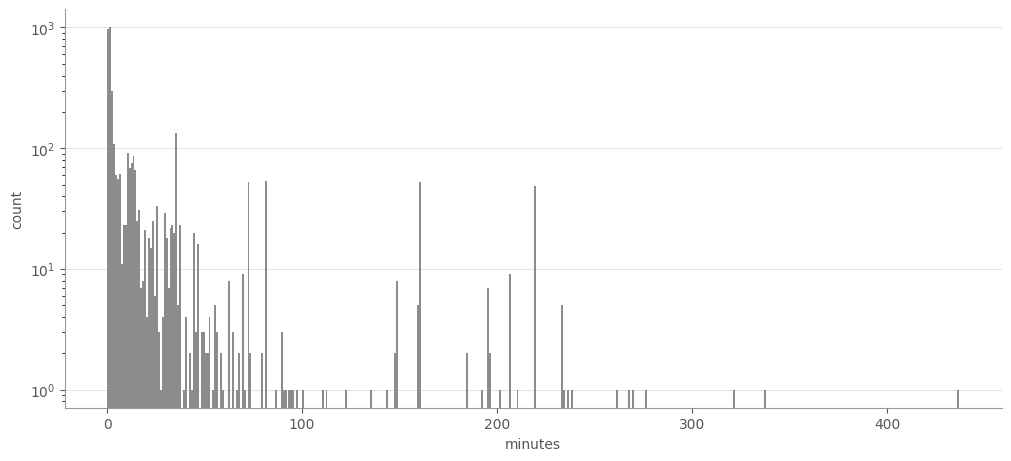

In [ ]:
import matplotlib.pyplot as plt


s = spark_df['max_timestamp'] - spark_df['min_timestamp']
minutes = s.dropna().dt.total_seconds() / 60
bins = np.arange(np.floor(minutes.min()), np.ceil(minutes.max()) + 1, 1)

fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
ax.hist(minutes, bins=bins, color='#8c8c8c',
        edgecolor='white' if len(bins) < 300 else 'none', linewidth=0.4)

ax.set_xlabel('minutes')
ax.set_ylabel('count')
ax.set_yscale('log')                      # remove if the distribution isn't heavy-tailed
ax.grid(axis='y', color='#dddddd', linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
for sp in ax.spines.values():
    sp.set_color('#999999')
ax.tick_params(colors='#555555')
ax.xaxis.label.set_color('#555555')
ax.yaxis.label.set_color('#555555')
plt.show()

In [ ]:
s.describe()

,0
count,3852
mean,0 days 00:17:38.462357217
std,0 days 00:41:05.317544781
min,0 days 00:00:00
25%,0 days 00:00:59
50%,0 days 00:01:48
75%,0 days 00:13:49
max,0 days 07:16:56


В основном задачи кратковременные. Возможно, в Spark'е нужно будет атрибуцировать аномалию конкретной задаче.

По Линуксу лог немного худшего качества: есть как старые проблемы (нарушение хронологии), небольшое кол-во дублей, так и ошибки декодирования: у 20 строк встретились проблемы с кодировкой. Нужно будет предобработать, прежде чем кормить как простым моделям, так и трансформерным.

In [ ]:
df[df['file_name'].str.startswith('data/Linux')]

,file_name,row_count,avg_char_count,min_timestamp,max_timestamp,no_timestamp_rows,no_timestamp_row_count,empty_rows,empty_row_count,double_rows,double_row_count,bad_encoding_rows,bad_encoding_row_count,bad_chrono_rows,bad_chrono_row_count,first_rows,random_rows
3884,data/Linux/Linux.log,25567,91.903078,2026-01-01 04:02:05,2026-12-31 04:07:34,[],0,[],0,"[(871, Jun 13 11:55:09 combo rpc.statd[1636]: ...",6,"[(867, Jun 13 11:55:04 combo rpc.statd[1636]: ...",20,"[(91, Jun 9 06:06:17 combo network: Setting n...",112,"[(0, Jun 9 06:06:20 combo syslogd 1.4.1: rest...","[(15, Jun 9 06:06:20 combo kernel: DMA zone..."


Как вообще выглядят линуксовые логи?

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/Linux/'), 'first_rows'].iloc[0]))

Jun  9 06:06:20 combo syslogd 1.4.1: restart.
Jun  9 06:06:20 combo syslog: syslogd startup succeeded
Jun  9 06:06:20 combo syslog: klogd startup succeeded
Jun  9 06:06:20 combo kernel: klogd 1.4.1, log source = /proc/kmsg started.
Jun  9 06:06:20 combo kernel: Linux version 2.6.5-1.358 (bhcompile@bugs.build.redhat.com) (gcc version 3.3.3 20040412 (Red Hat Linux 3.3.3-7)) #1 Sat May 8 09:04:50 EDT 2004
Jun  9 06:06:20 combo kernel: BIOS-provided physical RAM map:
Jun  9 06:06:20 combo kernel:  BIOS-e820: 0000000000000000 - 00000000000a0000 (usable)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 00000000000f0000 - 0000000000100000 (reserved)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 0000000000100000 - 0000000007eae000 (usable)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 0000000007eae000 - 0000000008000000 (reserved)
Jun  9 06:06:20 combo kernel:  BIOS-e820: 00000000ffb00000 - 0000000100000000 (reserved)
Jun  9 06:06:20 combo kernel: 0MB HIGHMEM available.
Jun  9 06:06:20 combo kernel: 126MB LO

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/Linux/'), 'random_rows'].iloc[0]))

Jun 10 11:31:44 combo syslog: syslogd startup succeeded
Jun 18 01:30:59 combo sshd(pam_unix)[31206]: check pass; user unknown
Jul  2 04:15:43 combo sshd(pam_unix)[24578]: authentication failure; logname= uid=0 euid=0 tty=NODEVssh ruser= rhost=zummit.com 
Aug  2 08:06:03 combo udev[25224]: creating device node '/udev/vcsa2'
Aug  9 19:19:54 combo ftpd[24111]: connection from 221.243.161.206 () at Tue Aug  9 19:19:54 2005 
Sep  6 16:03:42 combo ftpd[2459]: connection from 68.236.199.200 (static-68-236-199-200.nwrk.east.verizon.net) at Tue Sep  6 16:03:42 2005 
Sep 28 09:12:25 combo udev[2679]: creating device node '/udev/vcs5'
Oct  6 05:46:42 combo sshd(pam_unix)[30738]: authentication failure; logname= uid=0 euid=0 tty=NODEVssh ruser= rhost=202.39.240.228  user=root
Oct  8 13:17:00 combo sshd(pam_unix)[6219]: check pass; user unknown
Nov 17 17:37:55 combo sshd(pam_unix)[6765]: authentication failure; logname= uid=0 euid=0 tty=NODEVssh ruser= rhost=220.117.241.3 
Nov 19 11:17:37 combo ker

На что похоже? Логи очень разнообразные, хотя все и с временной меткой. Сервисы пишут произвольные сообщения. В логе отсутствует разметка критичности.

У Proxifier'а все лучше. Есть только одна строчка с проблемной хронологией, однако достаточно большое относительно размера датасета кол-во дублей, но, возможно, для сетевого инструмента это ок. Возможно, пишет много heartbeat'ов или вроде того.

In [ ]:
df[df['file_name'].str.startswith('data/Proxifier')]

,file_name,row_count,avg_char_count,min_timestamp,max_timestamp,no_timestamp_rows,no_timestamp_row_count,empty_rows,empty_row_count,double_rows,double_row_count,bad_encoding_rows,bad_encoding_row_count,bad_chrono_rows,bad_chrono_row_count,first_rows,random_rows
3885,data/Proxifier/Proxifier.log,21329,118.171738,2026-07-26 13:30:34,2026-10-30 21:21:48,[],0,[],0,"[(1, [10.30 16:49:06] chrome.exe - proxy.cse.c...",5802,[],0,"[(10108, [07.26 13:30:34] chrome.exe *64 - t11...",1,"[(0, [10.30 16:49:06] chrome.exe - proxy.cse.c...","[(650, [10.30 16:49:28] chrome.exe - proxy.cse..."


Посмотрим на первые и случайные строки:

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/Proxifier/'), 'first_rows'].iloc[0]))

[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 16:49:06] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime

In [ ]:
print(''.join(line for _, line in df.loc[df['file_name'].str.startswith('data/Proxifier/'), 'random_rows'].iloc[0]))

[10.30 16:53:24] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 896 bytes sent, 375 bytes received, lifetime <1 sec
[10.30 16:54:07] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 1292 bytes (1.26 KB) sent, 2437 bytes (2.37 KB) received, lifetime <1 sec
[10.30 17:37:57] chrome.exe - proxy.cse.cuhk.edu.hk:5070 close, 0 bytes sent, 0 bytes received, lifetime <1 sec
[10.30 18:03:23] Skype.exe - 112.104.105.187:443 open through proxy proxy.cse.cuhk.edu.hk:5070 HTTPS
[10.30 20:45:18] chrome.exe - proxy.cse.cuhk.edu.hk:5070 open through proxy proxy.cse.cuhk.edu.hk:5070 HTTPS
[10.30 20:45:21] chrome.exe - proxy.cse.cuhk.edu.hk:5070 open through proxy proxy.cse.cuhk.edu.hk:5070 HTTPS
[10.30 20:45:21] chrome.exe - proxy.cse.cuhk.edu.hk:5070 open through proxy proxy.cse.cuhk.edu.hk:5070 HTTPS
[10.30 20:46:20] chrome.exe - proxy.cse.cuhk.edu.hk:5070 open through proxy proxy.cse.cuhk.edu.hk:5070 HTTPS
[10.30 20:46:20] chrome.exe - proxy.cse.cuhk.edu.hk:5070 open through proxy proxy.cse.cuhk.edu.hk

Можно сделать предварительный вывод, что лог гомогенный и строго типизированный: временная метка, приложение, событие (сессия или отправка / приемка байт). Лейблов критичности также нет.

## Время

Мы посмотрели на общие свойства датасетов: их объем, физическую организацию, средний размер строки, поискали баги в данных и нюансы форматов. Посмотрим более содержательно. Нас интересует темпоральный аспект: какой у данных охват времени, есть ли провалы в данных и наблюдается ли сезонность. Сначала посмотрим на общее состояние лога, затем в разных разбивках. Что точно уже понятно про даты - в файлах нет таймзоны и они в разных форматах. Где-то нет года, добавили синтетический. Возьмем уже готовый парсер времени, посмотрим на временной ряд с разной детализацией.

Реализуем небольшой нарезчик, который в потоковом режиме агрегирует наши файлы на окна-пятиминутки и подсчитает кол-во записей в каждом из них.

In [13]:
from collections import Counter
from typing import Iterator


def count_per_window(generator: Iterable[tuple], minutes: int = 5) -> Iterator[tuple]:
    '''
    (line, *extra, timestamp) -> (начало окна, *extra, число строк)
    группировка по окну и по всем extra; таймстемп — последний элемент кортежа
    '''
    step = datetime.timedelta(minutes=minutes)
    max_ts = None
    current, counts = None, Counter()
    for item in generator:
        ts = item[-1]
        if ts is None:
            continue
        if max_ts is None or ts > max_ts:
            max_ts = ts
        else:
            ts = max_ts
        midnight = ts.replace(hour=0, minute=0, second=0, microsecond=0)
        window = midnight + step * ((ts - midnight) // step)
        if window != current:
            if current is not None:
                for extra, n in counts.items():
                    yield (current, *extra, n)
            current, counts = window, Counter()
        counts[tuple(item[1:-1])] += 1
    if current is not None:
        for extra, n in counts.items():
            yield (current, *extra, n)

Добавим к этому агрегатор, чтобы смотреть на более сжатых отрезках:

In [14]:
def coarsen_windows(rows: Iterable[tuple], minutes: int = 60) -> Iterator[tuple]:
    '''
    (начало окна, *extra, число строк) -> то же, но окна длиной `minutes` минут; счётчики суммируются по (окно, *extra)
    вход должен идти по возрастанию окон (как у count_per_window)
    '''
    step = datetime.timedelta(minutes=minutes)
    current, counts = None, Counter()
    for window, *extra, n in rows:
        midnight = window.replace(hour=0, minute=0, second=0, microsecond=0)
        coarse = midnight + step * ((window - midnight) // step)
        if coarse != current:
            if current is not None:
                for key, total in counts.items():
                    yield (current, *key, total)
            current, counts = coarse, Counter()
        counts[tuple(extra)] += n
    if current is not None:
        for key, total in counts.items():
            yield (current, *key, total)

Соберем разбивки по времени

In [ ]:
time_data = []
for file_name, iter_ in [
    ('data/HDFS_v1/HDFS.log', read_hdfs_v1_with_timestamp(read_lines_buffered('data/HDFS_v1/HDFS.log'))),
    *[(file_name, read_hdfs_v2_with_timestamp(read_lines_buffered(file_name))) for file_name in glob.glob("data/HDFS_v2/node_logs/*.log", recursive=True)],
    # не будем включать Spark, т.к. задачи там все равно очень короткие
    ('data/Linux/Linux.log', read_linux_with_timestamp(read_lines_buffered('data/Linux/Linux.log'), year=2026)),
    ('data/Proxifier/Proxifier.log', read_proxifier_with_timestamp(read_lines_buffered('data/Proxifier/Proxifier.log'), year=2026))
]:

    iter_5min = list(count_per_window(iter_))
    iter_30min = list(coarsen_windows(iter_5min, 30))
    iter_1hr = list(coarsen_windows(iter_30min, 60))
    iter_3hr = list(coarsen_windows(iter_1hr, 180))
    iter_6hr = list(coarsen_windows(iter_3hr, 360))
    iter_12hr = list(coarsen_windows(iter_6hr, 720))
    iter_24hr = list(coarsen_windows(iter_12hr, 1440))

    time_data.append((file_name, '5min', iter_5min))
    time_data.append((file_name, '30min', iter_30min))
    time_data.append((file_name, '1hr', iter_1hr))
    time_data.append((file_name, '3hr', iter_3hr))
    time_data.append((file_name, '6hr', iter_6hr))
    time_data.append((file_name, '12hr', iter_12hr))
    time_data.append((file_name, '24hr', iter_24hr))

    print(f'{file_name} - собрали интервалы.')

data/Proxifier/Proxifier.log - собрали интервалы.


In [ ]:
time_df = pd.DataFrame(time_data, columns=['file_name', 'time_type', 'values'])

Таким образом, получаем разбивки по интервалам

In [ ]:
time_df

,file_name,time_type,values
0,data/HDFS_v1/HDFS.log,5min,"[(2008-11-09 20:35:00, 32186), (2008-11-09 20:..."
1,data/HDFS_v1/HDFS.log,30min,"[(2008-11-09 20:30:00, 188723), (2008-11-09 21..."
2,data/HDFS_v1/HDFS.log,1hr,"[(2008-11-09 20:00:00, 188723), (2008-11-09 21..."
3,data/HDFS_v1/HDFS.log,3hr,"[(2008-11-09 18:00:00, 188723), (2008-11-09 21..."
4,data/HDFS_v1/HDFS.log,6hr,"[(2008-11-09 18:00:00, 879379), (2008-11-10 00..."
...,...,...,...
27204,data/Proxifier/Proxifier.log,1hr,"[(2026-10-30 16:00:00, 2272), (2026-10-30 17:0..."
27205,data/Proxifier/Proxifier.log,3hr,"[(2026-10-30 15:00:00, 4612), (2026-10-30 18:0..."
27206,data/Proxifier/Proxifier.log,6hr,"[(2026-10-30 12:00:00, 4612), (2026-10-30 18:0..."
27207,data/Proxifier/Proxifier.log,12hr,"[(2026-10-30 12:00:00, 21329)]"


Нарисуем распределение логов:

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


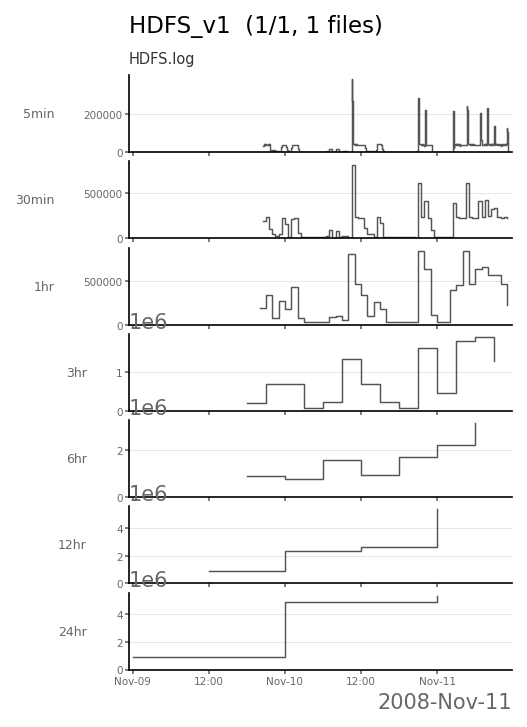

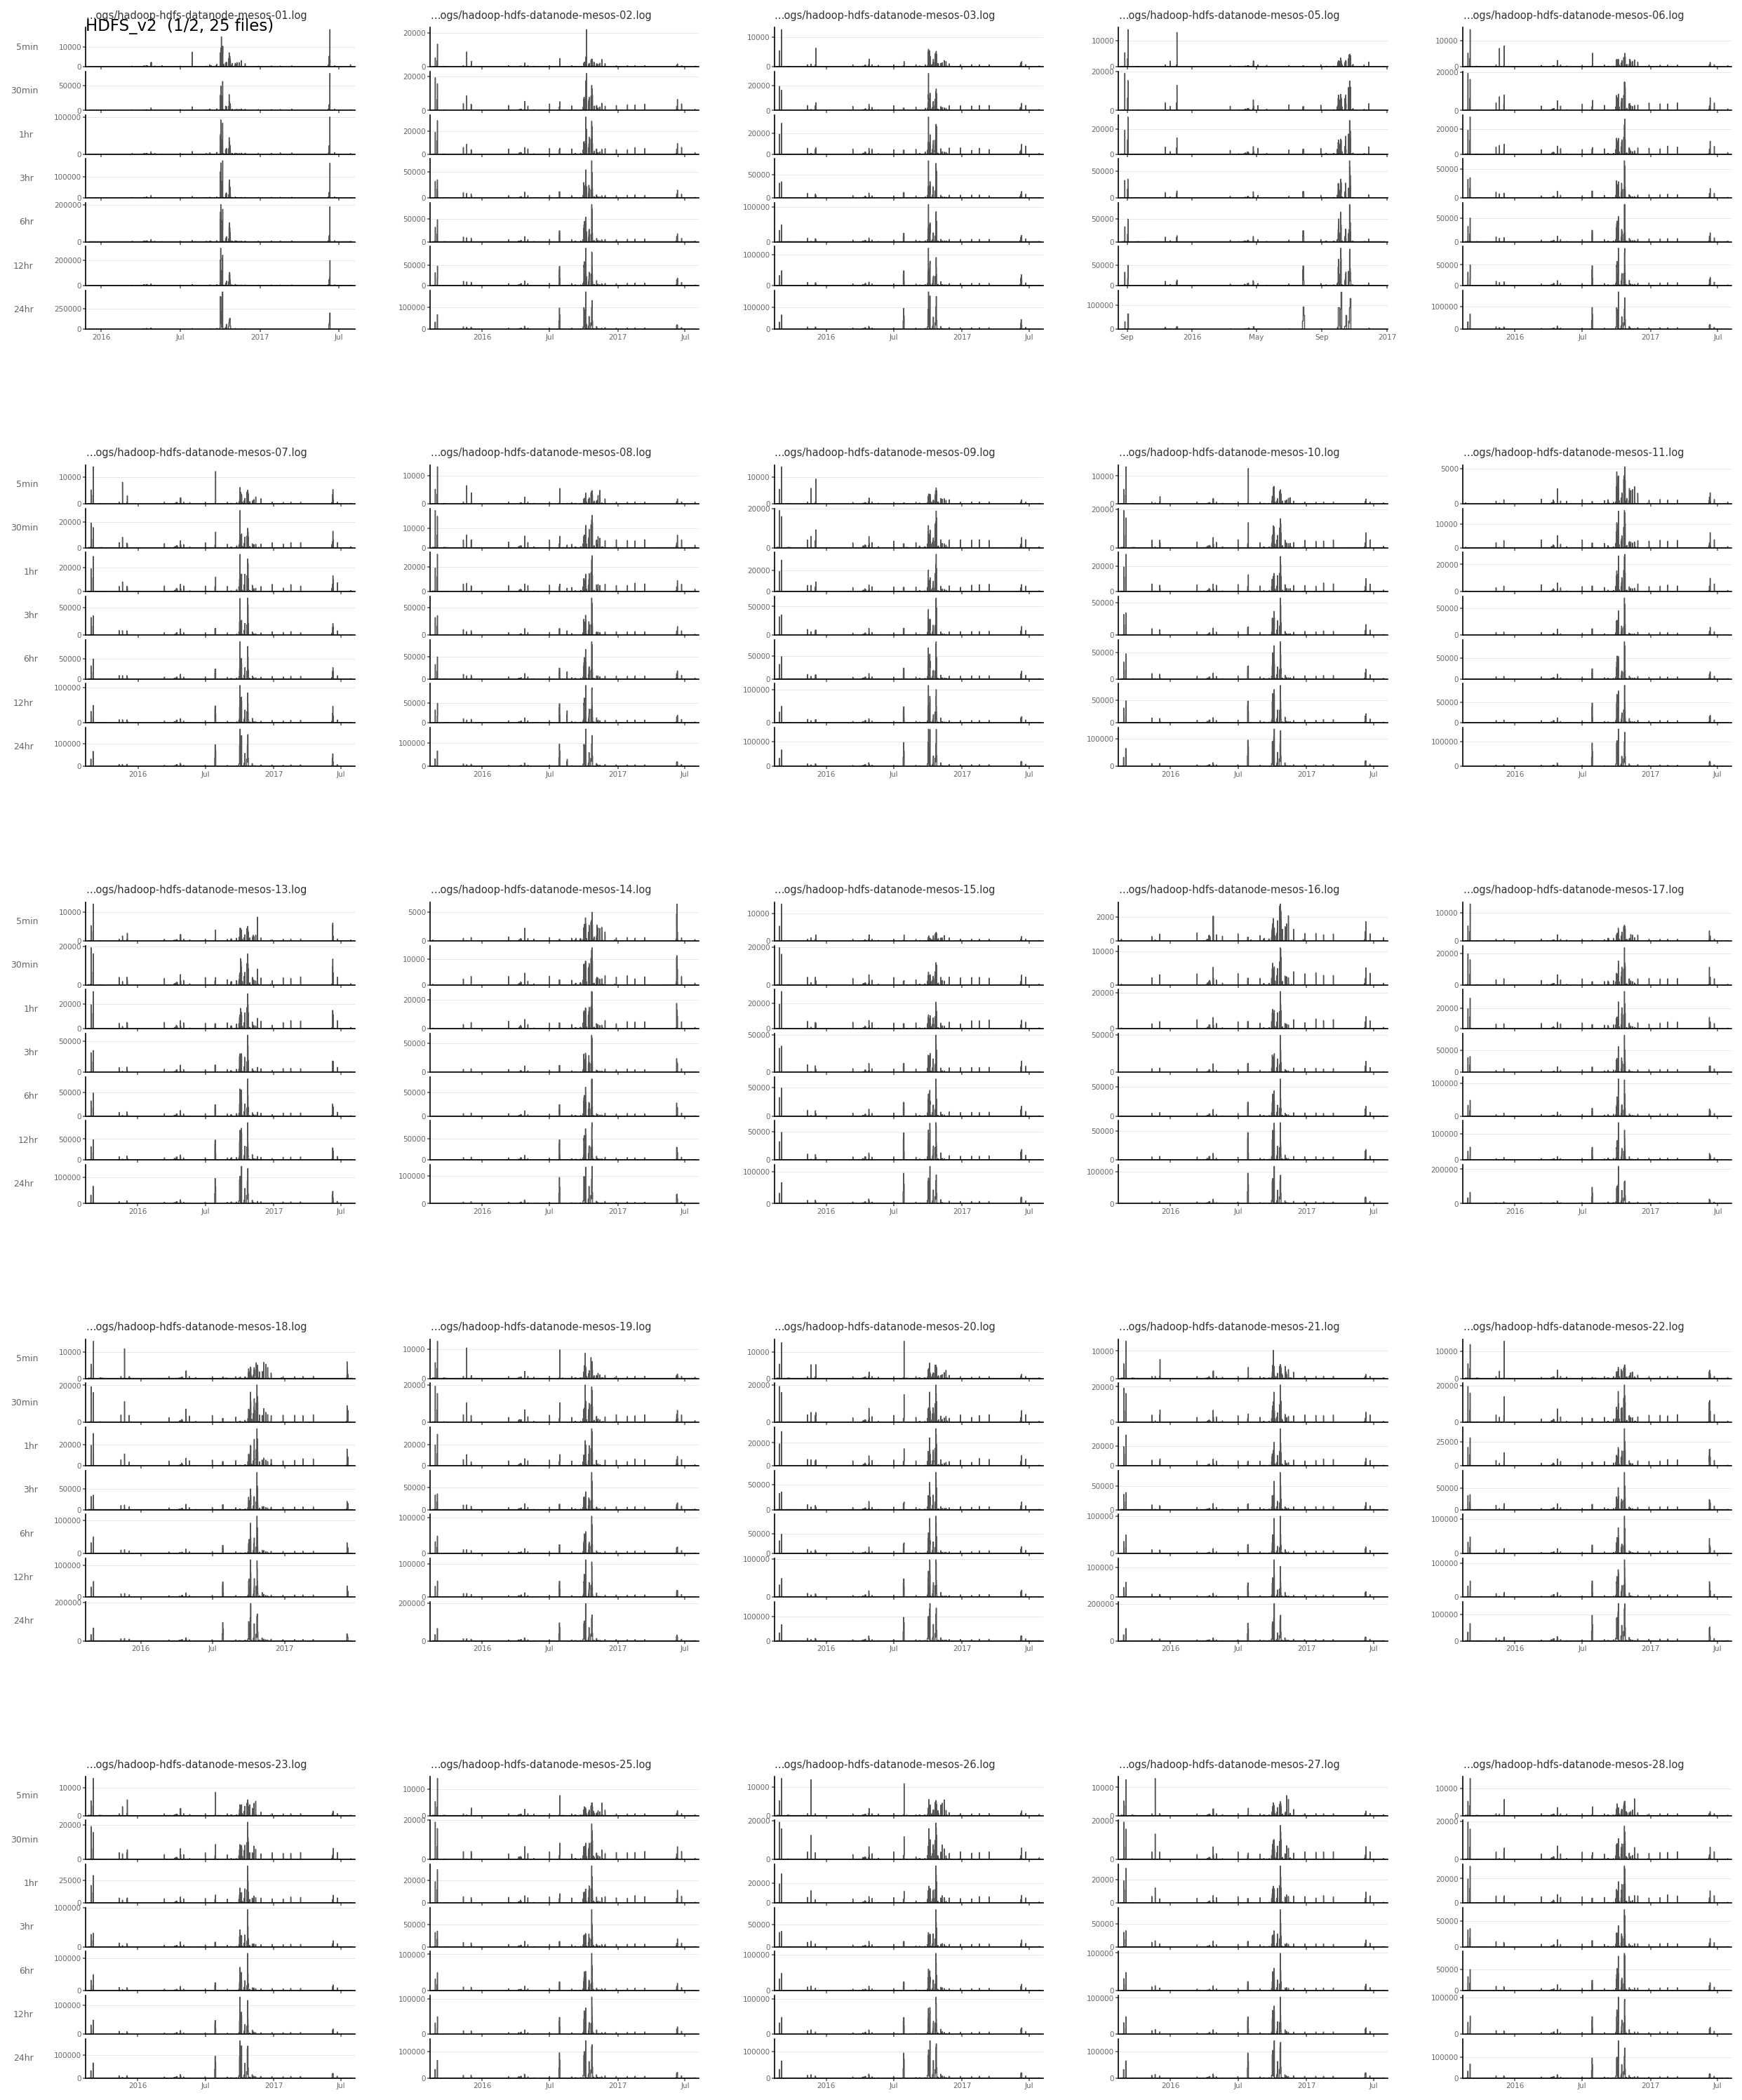

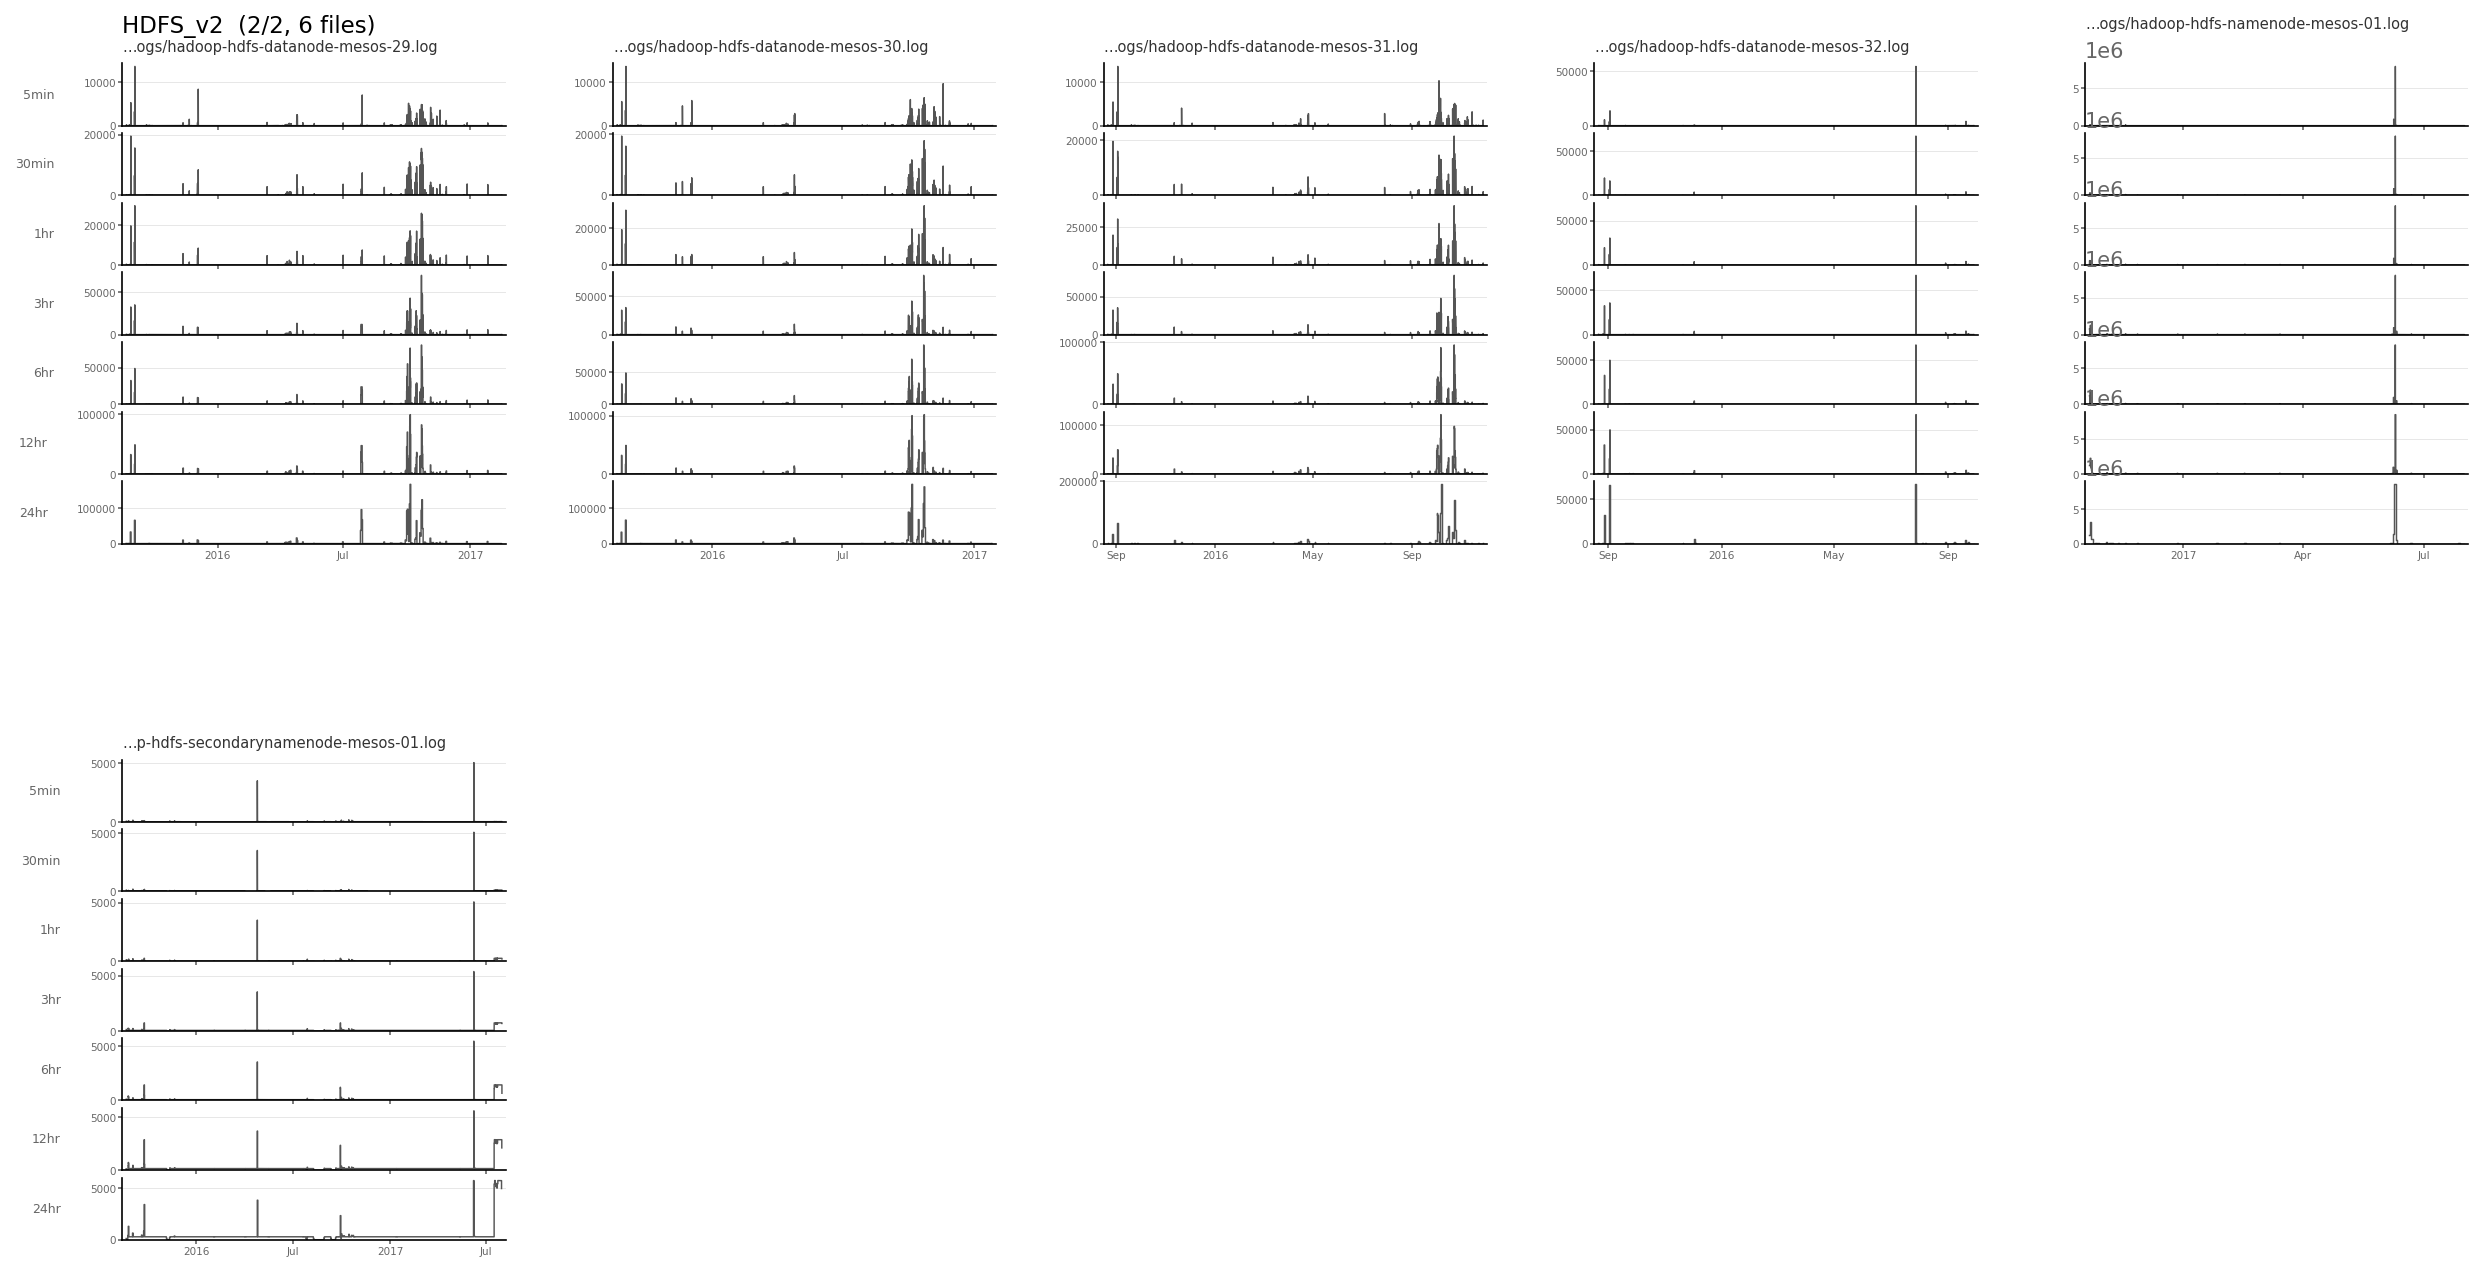

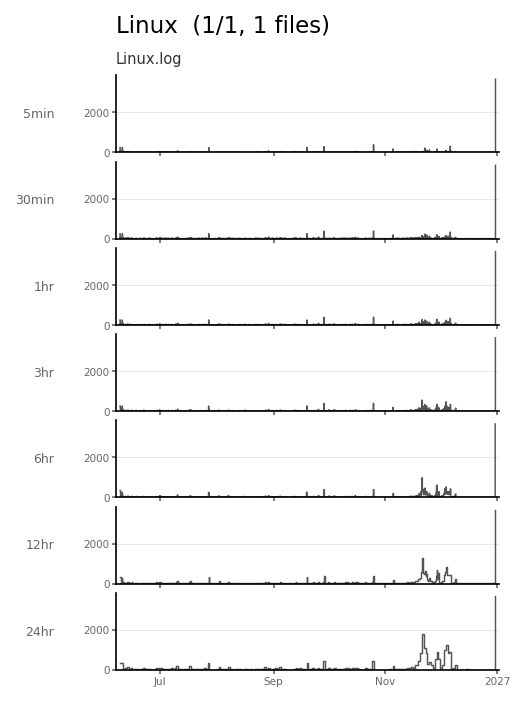

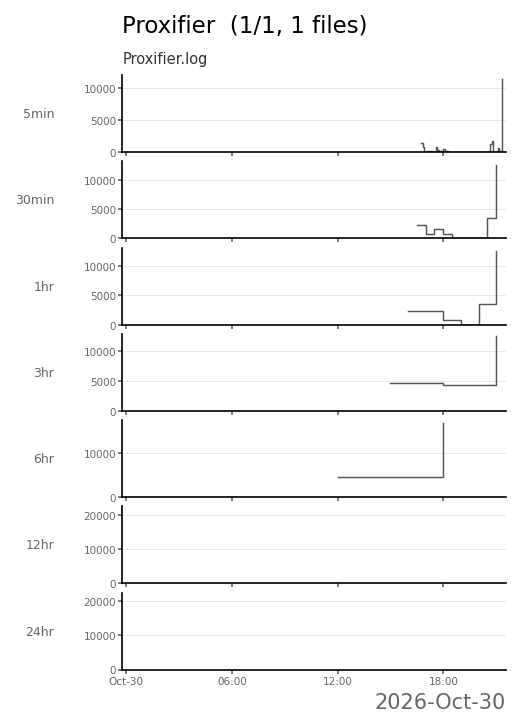

In [ ]:
import math

import matplotlib.dates as mdates

from matplotlib.gridspec import GridSpecFromSubplotSpec


plt.rcParams['figure.dpi'] = 150

TIME_TYPES = ['5min', '30min', '1hr', '3hr', '6hr', '12hr', '24hr']
FREQ = {'5min': '5min', '30min': '30min', '1hr': '1h', '3hr': '3h', '6hr': '6h', '12hr': '12h', '24hr': '24h'}
LINE_COLOR = '#555555'


def fill_empty(values: list, time_type: str) -> pd.Series:
    '''[(timestamp, count), ...] -> Series на полной сетке окон; пустые окна = 0'''
    if not values:
        return pd.Series(dtype='int64')
    s = pd.Series([c for _, c in values], index=pd.DatetimeIndex([t for t, _ in values]))
    s = s.sort_index().groupby(level=0).sum()
    freq = FREQ[time_type]
    n_points = (s.index[-1] - s.index[0]) / pd.Timedelta(freq)
    full = pd.date_range(s.index[0], s.index[-1], freq=freq)
    return s.reindex(full, fill_value=0)


def short_name(file_name: str, width: int = 38) -> str:
    '''data/<system>/rest -> rest, с обрезкой слева'''
    parts = file_name.split('/', 2)
    name = parts[2] if len(parts) > 2 else parts[-1]
    return name if len(name) <= width else '…' + name[-(width - 1):]


def plot_file(fig, spec, file_name: str, by_type: dict, first_col: bool):
    '''одна ячейка сетки: линии по типам окон друг над другом (общая ось X)'''
    inner = GridSpecFromSubplotSpec(len(TIME_TYPES), 1, subplot_spec=spec, hspace=0.12)
    axes = []
    for i, tt in enumerate(TIME_TYPES):
        ax = fig.add_subplot(inner[i, 0], sharex=axes[0] if axes else None)
        axes.append(ax)
        try:
            s = fill_empty(by_type.get(tt) or [], tt)
        except ValueError as e:
            ax.text(0.5, 0.5, str(e), ha='center', va='center', fontsize=5, transform=ax.transAxes)
            s = pd.Series(dtype='int64')
        if len(s):
            ax.plot(s.index, s.values, drawstyle='steps-post', lw=0.7, color=LINE_COLOR)
            ax.set_ylim(bottom=0)
        ax.tick_params(labelsize=5, length=2, pad=1, colors='#666666', labelbottom=(i == len(TIME_TYPES) - 1))
        ax.grid(axis='y', color='#e3e3e3', lw=0.4)
        ax.spines[['top', 'right']].set_visible(False)
        ax.margins(x=0.01)
        if first_col:
            ax.set_ylabel(tt, fontsize=6, color='#666666', rotation=0, ha='right', va='center', labelpad=14)
    last = axes[-1]
    loc = mdates.AutoDateLocator(minticks=3, maxticks=5)
    last.xaxis.set_major_locator(loc)
    last.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    axes[0].set_title(short_name(file_name), fontsize=7, loc='left', color='#333333')


def plot_systems(df: pd.DataFrame, per_row: int = 5, max_files: int = 25):
    '''
    df: file_name, time_type, values [(timestamp, count), ...]
    Генератор: на каждую систему (data/<system>/...) отдаёт одну или несколько фигур по max_files файлов.
    yield (system, страница, число страниц, fig). После показа/сохранения делайте plt.close(fig).
    '''
    system = df['file_name'].str.split('/').str[1]
    for system_name, group in df.groupby(system, sort=True):
        by_file = {
            f: dict(zip(sub['time_type'], sub['values']))
            for f, sub in group.groupby('file_name', sort=True)
        }
        files = list(by_file)
        pages = [files[i:i + max_files] for i in range(0, len(files), max_files)]
        for page, chunk in enumerate(pages, 1):
            n_rows = math.ceil(len(chunk) / per_row)
            fig = plt.figure(figsize=(per_row * 3.4, n_rows * 4.0 + 0.6))
            outer = fig.add_gridspec(n_rows, per_row, hspace=0.45, wspace=0.28,
                                     left=0.07, right=0.99, top=1 - 0.5 / (n_rows * 4.0 + 0.6), bottom=0.03)
            for k, file_name in enumerate(chunk):
                plot_file(fig, outer[k // per_row, k % per_row], file_name, by_file[file_name],
                          first_col=(k % per_row == 0))
            fig.suptitle(f'{system_name}  ({page}/{len(pages)}, {len(chunk)} files)', fontsize=11, x=0.07, ha='left')
            yield system_name, page, len(pages), fig


for system, page, n_pages, fig in plot_systems(time_df):
    plt.show()
    plt.close(fig)

Что можно сказать о данных? Во-первых, есть пропуски и предстоит выяснить, обсуловлены они тем, что система не работала (была выключена), или просто бездействием. Это можно проверить, посмотрев на примыкающающие к пробелам записи лога (есть ли явные сообщения о включении/выключении). В датасете HDFS_v1 присутствует явно выраженная сезонность, вероятно обусловленная временем эксплуатации. Есть явный тренд на увеличение нагрузки. В HDFS_v2 тоже есть сезонность (умеренные пики на протяжении всего периода эксплуатации), однако примерно в середине интервала все ноды начали писать больше обычного. Длилось это примерно несколько недель. Похоже на однократную обработку большого объема данных, типа инициализирующей загрузки. При этом важно отметить, что некоторые дата-ноды пишут сильно меньше других. Перекос? У Linux также наблюдается увеличение объемов логирования ближе к концу интервала. Повышенная нагрузка? У Proxifier'а какой-то ненормальный пик в самом конце лога, как будто с таймстэмпами напортачено.

## Распределения
Посмотрим, как ведет себя со временем распределение компонент и уровней критичности. Напишем потоковые парсеры:

In [15]:
def read_hdfs_v1_with_level(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\d{6} \d{6} \d+ (?P<level>[A-Z]+)(?=\s|$)')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['level'] if m else None)


def read_hdfs_v1_with_component(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\d{6} \d{6} \d+ [A-Z]+ (?P<component>[^\s:]+):')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['component'] if m else None)

In [16]:
def read_hdfs_v2_with_level(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}(?:,\d{1,9})? (?P<level>[A-Z]+)(?=\s|$)')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['level'] if m else None)


def read_hdfs_v2_with_component(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}(?:,\d{1,9})? [A-Z]+ (?P<component>[^\s:]+):')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['component'] if m else None)

In [17]:
def read_spark_with_level(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\d{2}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}(?:,\d{1,9})? (?P<level>[A-Z]+)(?=\s|$)')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['level'] if m else None)


def read_spark_with_component(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\d{2}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}(?:,\d{1,9})? [A-Z]+ (?P<component>[^\s:]+):')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['component'] if m else None)

In [18]:
def read_linux_with_component(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(
        r'^[A-Z][a-z]{2} +\d{1,2} \d{2}:\d{2}:\d{2} \S+ '
        r'(?P<component>[^\s\[:]+)(?:\[\d+\])?(?: \d[\d.]*)?:'
    )
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['component'] if m else None)

In [19]:
def read_proxifier_with_component(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\[\d{2}\.\d{2} \d{2}:\d{2}:\d{2}\] (?P<component>.+?) - ')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['component'] if m else None)


def read_proxifier_with_event(generator: Iterable) -> Iterator[tuple]:
    regex = re.compile(r'^\[\d{2}\.\d{2} \d{2}:\d{2}:\d{2}\] .+? - \S+ (?P<event>open|close|error)\b')
    for (line, *extra) in generator:
        m = regex.match(line)
        yield (line, *extra, m['event'] if m else None)

Соберем конкретные генераторы (Spark обработаем отдельно)

In [ ]:
hdfs_v1_reader = read_hdfs_v1_with_timestamp(read_hdfs_v1_with_component(read_hdfs_v1_with_level(read_lines_buffered('data/HDFS_v1/HDFS.log'))))
hdfs_v2_datanode_reader = read_hdfs_v2_with_timestamp(read_hdfs_v2_with_component(read_hdfs_v2_with_level(read_lines_buffered('data/HDFS_v2/node_logs/hadoop-hdfs-datanode-mesos-03.log'))))
hdfs_v2_namenode_reader = read_hdfs_v2_with_timestamp(read_hdfs_v2_with_component(read_hdfs_v2_with_level(read_lines_buffered('data/HDFS_v2/node_logs/hadoop-hdfs-namenode-mesos-01.log'))))
hdfs_v2_secondarynamenode_reader = read_hdfs_v2_with_timestamp(read_hdfs_v2_with_component(read_hdfs_v2_with_level(read_lines_buffered('data/HDFS_v2/node_logs/hadoop-hdfs-secondarynamenode-mesos-01.log'))))
linux_reader = read_linux_with_timestamp(read_linux_with_component(read_lines_buffered('data/Linux/Linux.log')), year=2026)
proxifier_reader = read_proxifier_with_timestamp(read_proxifier_with_event(read_proxifier_with_component(read_lines_buffered('data/Proxifier/Proxifier.log'))), year=2026)

In [ ]:
hdfs_v1_full_1hr = list(count_per_window(hdfs_v1_reader, minutes=60))
hdfs_v2_datanode_1hr = list(count_per_window(hdfs_v2_datanode_reader, minutes=60))
hdfs_v2_namenode_reader = list(count_per_window(hdfs_v2_namenode_reader, minutes=60))
hdfs_v2_secondarynamenode_reader = list(count_per_window(hdfs_v2_secondarynamenode_reader, minutes=60))
linux_reader = list(count_per_window(linux_reader, minutes=60))
proxifier_reader = list(count_per_window(proxifier_reader, minutes=60))

In [ ]:
LEVEL_ORDER = ['TRACE', 'DEBUG', 'INFO', 'WARN', 'WARNING', 'ERROR', 'FATAL']


def rows_to_frame(rows: list, extras: list[str]) -> pd.DataFrame:
    '''строки count_per_window (окно, *extra, число) -> DataFrame с именованными колонками'''
    return pd.DataFrame(rows, columns=['window', *extras, 'n'])


def short_tail(name: str) -> str:
    '''org.apache.hadoop.hdfs.server.datanode.DataNode -> DataNode'''
    return name.rsplit('.', 1)[-1]


def plot_category_heatmap(df: pd.DataFrame, by: str, minutes: int = 60, top: int | None = None,
                          order: list | None = None, shorten=None, row_norm: bool = False, title: str = ''):
    '''
    строки = значения колонки `by` (уровень / компонент), столбцы = окна времени, цвет = log(1 + число строк).
    Пустые окна (в т.ч. дыры во времени) — белые.
    top: оставить top самых частых значений, остальные сложить в (other)
    order: желаемый порядок строк (например LEVEL_ORDER); иначе по убыванию частоты
    row_norm: нормировать каждую строку на её максимум (видно КОГДА, а не СКОЛЬКО)
    '''
    d = df[['window', by, 'n']].copy()
    d[by] = d[by].fillna('(none)')
    if shorten is not None:
        before = d[by].nunique()
        d[by] = d[by].map(shorten)
        if d[by].nunique() < before:
            print(f'WARNING: shortening merged {before - d[by].nunique()} names in "{by}"')
    m = d.groupby([by, 'window'])['n'].sum().unstack('window', fill_value=0)

    if top is not None and len(m) > top:
        keep = m.sum(axis=1).nlargest(top).index
        rest = m.drop(index=keep).sum()
        m = m.loc[keep]
        m.loc['(other)'] = rest
    totals = m.sum(axis=1)
    tail = {'(other)': 1, '(none)': 2}
    rank = {name: i for i, name in enumerate(order or [])}
    m = m.loc[sorted(m.index, key=lambda k: (tail.get(k, 0), rank.get(k, len(rank)), -totals[k]))]

    step = pd.Timedelta(minutes=minutes)
    full = pd.date_range(m.columns.min(), m.columns.max(), freq=step)
    m = m.reindex(columns=full, fill_value=0)

    z = m.values / m.values.max(axis=1, keepdims=True) if row_norm else np.log1p(m.values)
    x_edges = mdates.date2num((full.append(pd.DatetimeIndex([full[-1] + step]))).to_numpy())
    y_edges = np.arange(len(m) + 1)

    fig, ax = plt.subplots(figsize=(14, max(2.5, 0.3 * len(m) + 1.8)), layout='constrained')
    im = ax.pcolormesh(x_edges, y_edges, z, cmap='Greys', vmin=0, shading='flat')
    ax.invert_yaxis()
    ax.set_yticks(np.arange(len(m)) + 0.5, [f'{k}  ({totals[k]:,})' for k in m.index], fontsize=8)
    ax.xaxis_date()
    im = ax.pcolormesh(x_edges, y_edges, z, cmap='Greys', vmin=0, shading='flat')
    ax.invert_yaxis()
    ax.set_yticks(np.arange(len(m)) + 0.5, [f'{k}  ({totals[k]:,})' for k in m.index], fontsize=8)
    ax.xaxis_date()
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.set_title(title)
    fig.colorbar(im, ax=ax, pad=0.01, label='row max = 1' if row_norm else 'log(1 + lines)')
    plt.close(fig)
    return fig

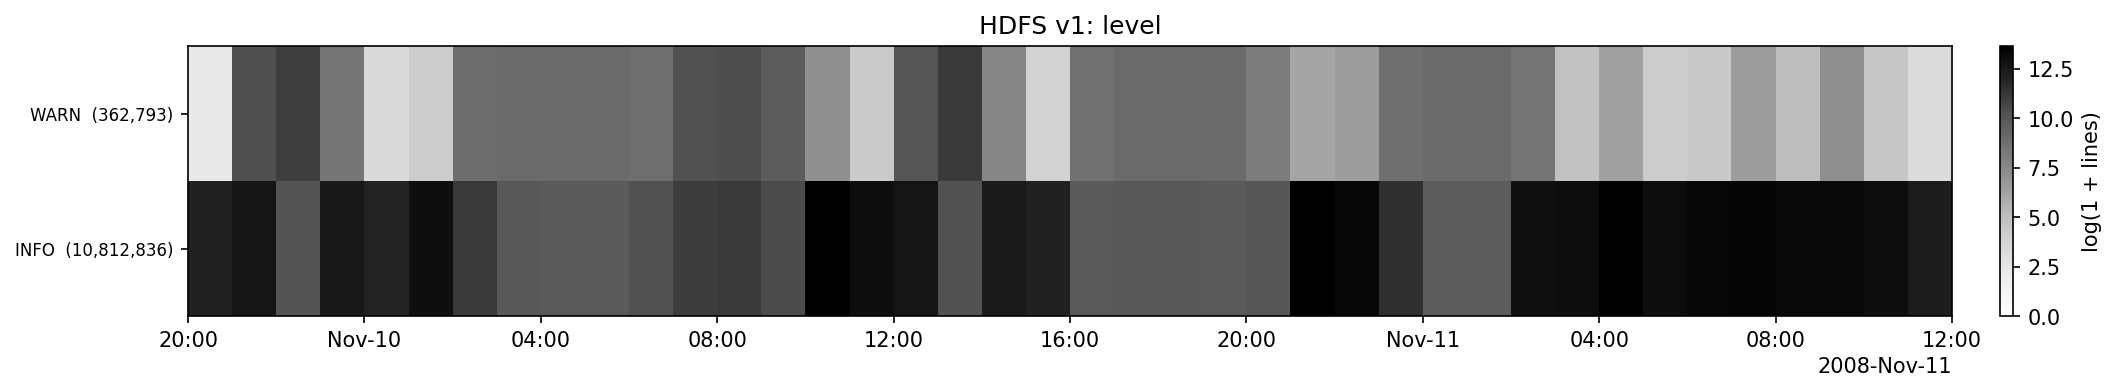

In [ ]:
hdfs_v1_full_df = rows_to_frame(hdfs_v1_full_1hr, ['level', 'component'])
plot_category_heatmap(hdfs_v1_full_df, 'level', order=LEVEL_ORDER, title='HDFS v1: level')

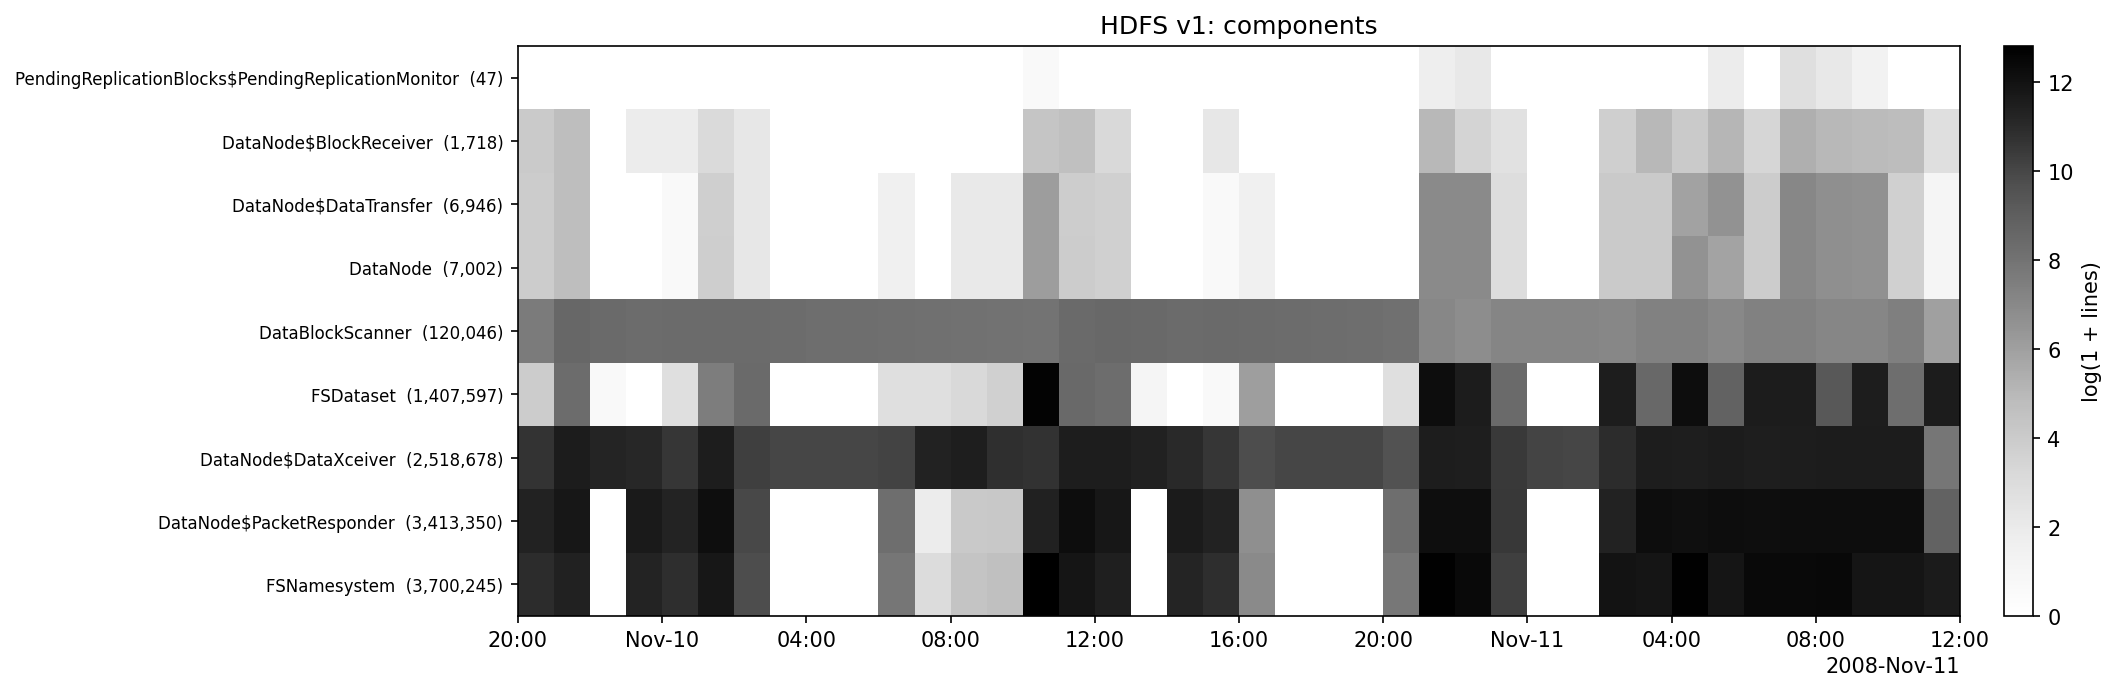

In [ ]:
plot_category_heatmap(hdfs_v1_full_df, 'component', top=25, shorten=short_tail, title='HDFS v1: components')

## Взглянем на шаблоны

Для начала установим drain3:

In [20]:
!pip install drain3

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for drain3: filename=drain3-0.9.11-py3-none-any.whl size=24086 sha256=52fe8062f2473b88c789ae1868383813fc40a419a09e65489dc4f619959582e1
  Stored in directory: /root/.cache/pip/wheels/77/7b/c6/81836300840d5e110d022e5efa4337472f48b97faa46540388
Successfully built drain3
  Attempting uninstall: jsonpickle
    Found existing installation: jsonpickle 4.1.4
    Uninstalling jsonpickle-4.1.4:
      Successfully uninstalled jsonpickle-4.1.4
  Attempting uninstall: cachetools
    Found existing installation: cachetools 6.2.6
    Uninstalling cachetools-6.2.6:
      Successfully uninstalled cachetools-6.2.6
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [drain3]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyiceberg 0.1

In [22]:
from drain3 import TemplateMiner
from drain3.masking import MaskingInstruction
from drain3.template_miner_config import TemplateMinerConfig


HEADERS = {
    'hdfs_v1': re.compile(r'^\d{6} \d{6} \d+ [A-Z]+ [^\s:]+: ?'),
    'hdfs_v2': re.compile(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}(?:,\d{1,9})? [A-Z]+ [^\s:]+: ?'),
    'spark': re.compile(r'^\d{2}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}(?:,\d{1,9})? [A-Z]+ [^\s:]+: ?'),
    'linux': re.compile(r'^[A-Z][a-z]{2} +\d{1,2} \d{2}:\d{2}:\d{2} \S+ [^\s\[:]+(?:\[\d+\])?(?: \d[\d.]*)?: ?'),
    'proxifier': re.compile(r'^\[\d{2}\.\d{2} \d{2}:\d{2}:\d{2}\] .+? - ')
}


def make_miner(extra_masks: Iterable[tuple[str, str]] = (), sim_th: float = 0.4) -> TemplateMiner:
    '''extra_masks: [(regex, имя)] поверх общих масок IP и чисел'''
    config = TemplateMinerConfig()
    config.drain_sim_th = sim_th
    config.drain_depth = 4
    config.drain_max_children = 100
    config.profiling_enabled = False
    masks = [*extra_masks,
             (r'((?<=[^A-Za-z0-9])|^)(\d{1,3}\.){3}\d{1,3}(:\d+)?((?=[^A-Za-z0-9])|$)', 'IP'),
             (r'((?<=[^A-Za-z0-9])|^)(-?\d+)((?=[^A-Za-z0-9])|$)', 'NUM')]
    config.masking_instructions = [MaskingInstruction(rx, name) for rx, name in masks]
    return TemplateMiner(config=config)


def read_with_template(generator: Iterable, miner: TemplateMiner, header: re.Pattern) -> Iterator[tuple]:
    '''
    дописывает id шаблона (или None, если у строки нет заголовка — например, продолжение стектрейса).
    В Drain уходит только текст сообщения после header; miner обучается по ходу потока.
    '''
    for (line, *extra) in generator:
        m = header.match(line)
        if m is None:
            yield (line, *extra, None)
            continue
        yield (line, *extra, miner.add_log_message(line[m.end():].rstrip('\n'))['cluster_id'])


def template_table(miner: TemplateMiner) -> list[tuple]:
    '''итог после прохода: (id, сколько строк, текст шаблона), по убыванию частоты'''
    return sorted(((c.cluster_id, c.size, c.get_template()) for c in miner.drain.clusters), key=lambda r: -r[1])

In [23]:
hdfs_v1_miner = make_miner([(r'blk_-?\d+', 'BLK')])
hdfs_v1_reader = read_hdfs_v1_with_timestamp(read_with_template(
    read_hdfs_v1_with_component(read_hdfs_v1_with_level(read_lines_buffered('data/HDFS_v1/HDFS.log'))),
    hdfs_v1_miner,
    HEADERS['hdfs_v1']
))

In [34]:
miner_v2 = make_miner()


def hdfs_v2_reader(path):
    return read_hdfs_v2_with_timestamp(read_with_template(
        read_hdfs_v2_with_component(read_hdfs_v2_with_level(read_lines_buffered(path))),
        miner_v2, HEADERS['hdfs_v2']))


hdfs_v2_datanode_reader = hdfs_v2_reader('data/HDFS_v2/node_logs/hadoop-hdfs-datanode-mesos-03.log')
hdfs_v2_namenode_reader = hdfs_v2_reader('data/HDFS_v2/node_logs/hadoop-hdfs-namenode-mesos-01.log')
hdfs_v2_secondarynamenode_reader = hdfs_v2_reader('data/HDFS_v2/node_logs/hadoop-hdfs-secondarynamenode-mesos-01.log')

In [60]:
miner_linux = make_miner()
linux_reader = read_linux_with_timestamp(
    read_with_template(
        read_linux_with_component(read_lines_buffered('data/Linux/Linux.log')),
        miner_linux, HEADERS['linux']),
    year=2026)

In [63]:
HOST = (r'((?<=[^A-Za-z0-9])|^)(?:[A-Za-z0-9-]+\.)+[A-Za-z]{2,}(:\d+)?((?=[^A-Za-z0-9])|$)', 'HOST')
miner_px = make_miner([HOST])
proxifier_reader = read_proxifier_with_timestamp(
    read_with_template(
        read_proxifier_with_event(read_proxifier_with_component(read_lines_buffered('data/Proxifier/Proxifier.log'))),
        miner_px, HEADERS['proxifier']),
    year=2026)

Посмотрим распределение шаблонов:

In [50]:
import textwrap


def rows_to_frame(rows: list, extras: list[str]) -> pd.DataFrame:
    '''строки count_per_window (окно, *extra, число) -> DataFrame с именованными колонками'''
    return pd.DataFrame(rows, columns=['window', *extras, 'n'])


def template_hour_frame(rows: list, extras: list[str], miner) -> pd.DataFrame:
    '''
    строки count_per_window (окно 60 мин) -> (window, template_id, n, template): суммируем по шаблону и часу,
    уровень / компонент и прочие extra сворачиваются. Вызывать ПОСЛЕ прохода — тексты шаблонов берутся из miner.
    '''
    df = rows_to_frame(rows, extras)
    df = df.groupby(['window', 'template_id'], dropna=False, as_index=False)['n'].sum()
    text = {c.cluster_id: c.get_template() for c in miner.drain.clusters}
    df['template'] = df['template_id'].map(lambda i: f'#{int(i)} {text.get(int(i), "?")}' if pd.notna(i) else None)
    return df


def plot_template_pages(df: pd.DataFrame, per_figure: int = 8, top: int | None = None,
    label_width: int = 34, title: str = ''):
    '''
    генератор фигур: шаблоны по убыванию частоты, по per_figure панелей на фигуру.
    Шкала цвета у каждой панели своя (шаблоны очень разные по частоте).
    '''
    totals = df.groupby('template')['n'].sum().sort_values(ascending=False)
    names = list(totals.index)[:top] if top else list(totals.index)
    for start in range(0, len(names), per_figure):
        chunk = names[start:start + per_figure]
        yield plot_day_hour_panels(df[df['template'].isin(chunk)], 'template', order=chunk, per_panel_scale=True,
            label_width=label_width,
            title=f'{title}: templates {start + 1}-{start + len(chunk)} of {len(names)}')

In [46]:
def day_hour_matrix(d: pd.DataFrame, days: pd.DatetimeIndex) -> np.ndarray:
    '''окна -> матрица 24 x число_дней; окна короче часа суммируются в часы'''
    g = d.groupby([d['window'].dt.normalize(), d['window'].dt.hour])['n'].sum()
    return g.unstack(fill_value=0).reindex(index=days, columns=range(24), fill_value=0).values.T


def plot_day_hour_panels(df: pd.DataFrame, by: str, top: int | None = None, order: list | None = None,
                         shorten=None, per_panel_scale: bool = False, label_width: int | None = None,
                         title: str = ''):
    '''
    по панели на каждое значение колонки `by` (уровень / компонент / шаблон): x = дни, y = час суток,
    цвет = log(1 + число строк). Общая ось дат, годы помещаются на одном графике.
    top: только top самых частых значений; order: порядок панелей
    per_panel_scale: своя шкала цвета у каждой панели (иначе общая — панели сравнимы по объёму)
    label_width: переносить длинные подписи (тексты шаблонов) по этой ширине
    '''
    d = df[['window', by, 'n']].copy()
    d[by] = d[by].fillna('(none)')
    if shorten is not None:
        before = d[by].nunique()
        d[by] = d[by].map(shorten)
        if d[by].nunique() < before:
            print(f'WARNING: shortening merged {before - d[by].nunique()} names in "{by}"')
    totals = d.groupby(by)['n'].sum()
    rank = {name: i for i, name in enumerate(order or [])}
    names = sorted(totals.index, key=lambda k: (k == '(none)', rank.get(k, len(rank)), -totals[k]))
    if order is None:
        names = sorted(names, key=lambda k: (k == '(none)', -totals[k]))
    names = names[:top] if top else names

    days = pd.date_range(d['window'].min().normalize(), d['window'].max().normalize(), freq='D')
    mats = {k: np.log1p(day_hour_matrix(d[d[by] == k], days)) for k in names}
    vmax = None if per_panel_scale else max(m.max() for m in mats.values())
    x_edges = mdates.date2num(days.append(pd.DatetimeIndex([days[-1] + pd.Timedelta(days=1)])).to_numpy())

    fig, axes = plt.subplots(len(names), 1, figsize=(14, 1.5 * len(names) + 1.2), sharex=True,
                             squeeze=False, layout='constrained')
    axes = axes[:, 0]
    for ax, k in zip(axes, names):
        im = ax.pcolormesh(x_edges, np.arange(25), mats[k], cmap='Greys', vmin=0, vmax=vmax, shading='flat')
        ax.invert_yaxis()
        ax.set_yticks([0.5, 6.5, 12.5, 18.5], ['00', '06', '12', '18'], fontsize=7)
        label = textwrap.fill(textwrap.shorten(k, 150), label_width) if label_width else k
        ax.set_ylabel(f'{label}\n({totals[k]:,})', rotation=0, ha='right', va='center', fontsize=7, labelpad=8)
    loc = mdates.AutoDateLocator()
    axes[-1].xaxis_date()
    axes[-1].xaxis.set_major_locator(loc)
    axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    axes[0].set_title(title)
    if not per_panel_scale:
        fig.colorbar(im, ax=list(axes), pad=0.01, label='log(1 + lines)')
    return fig

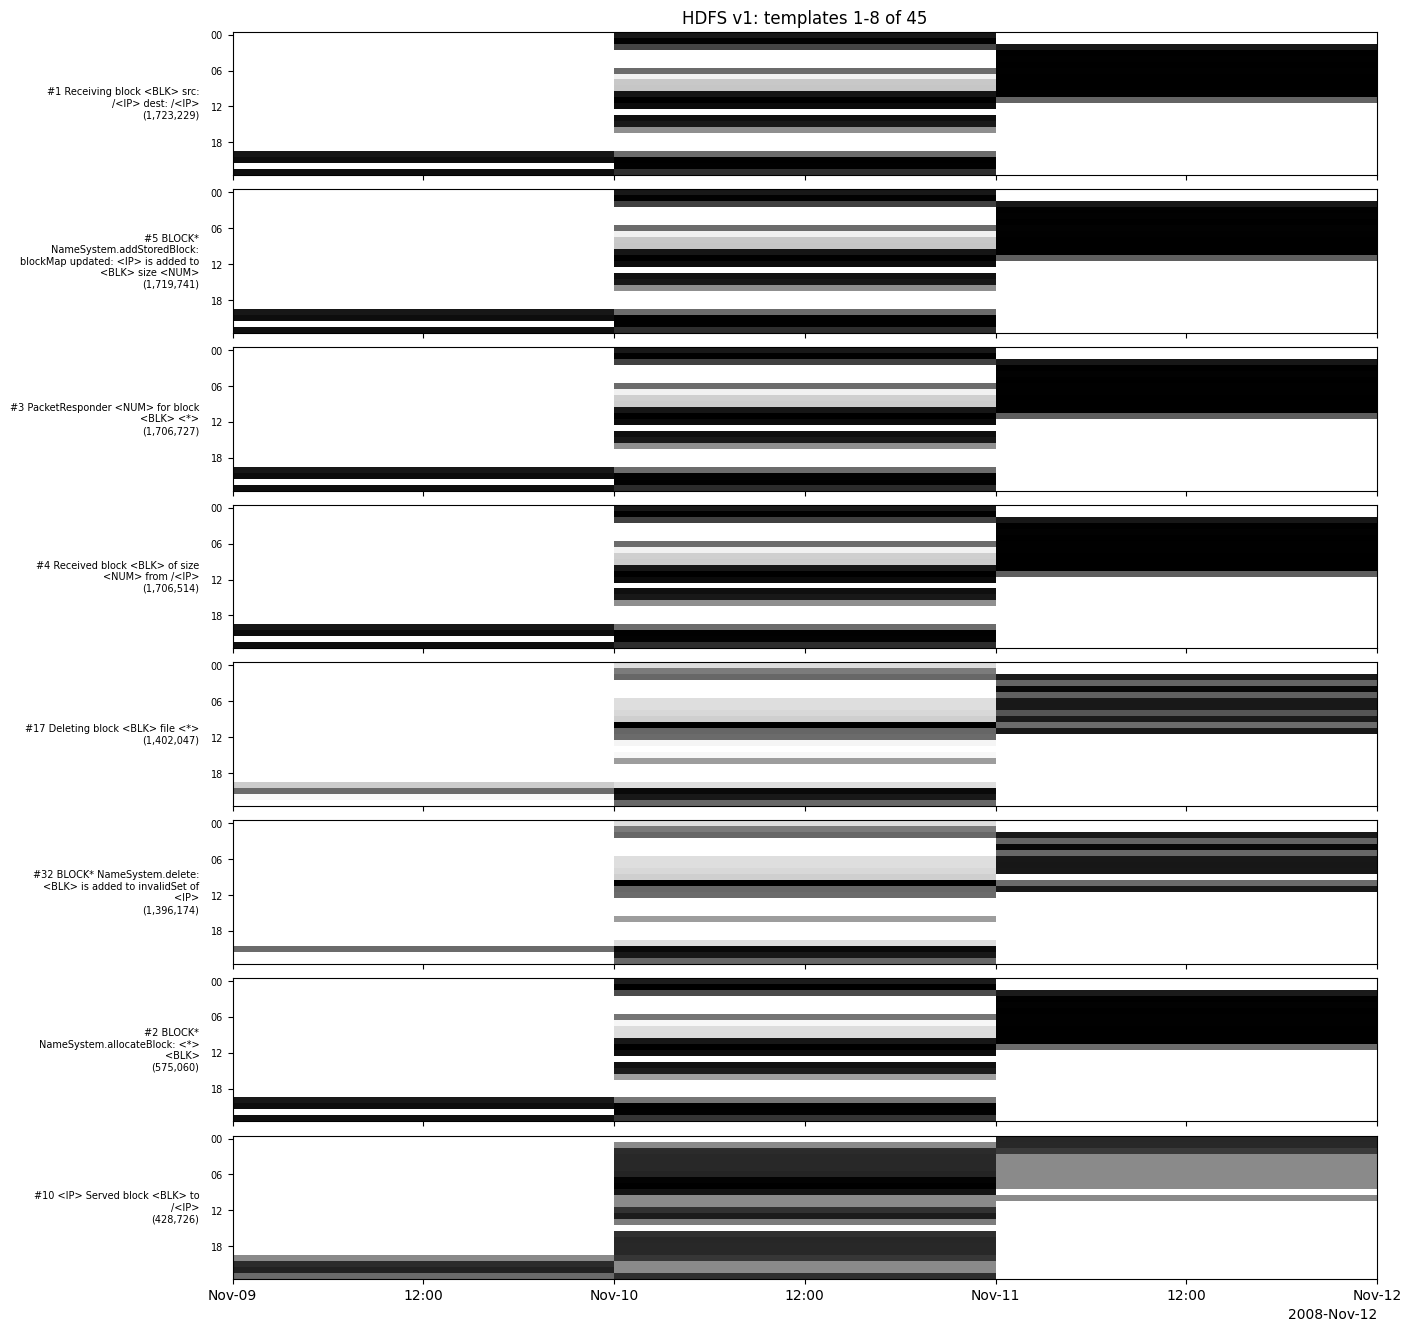

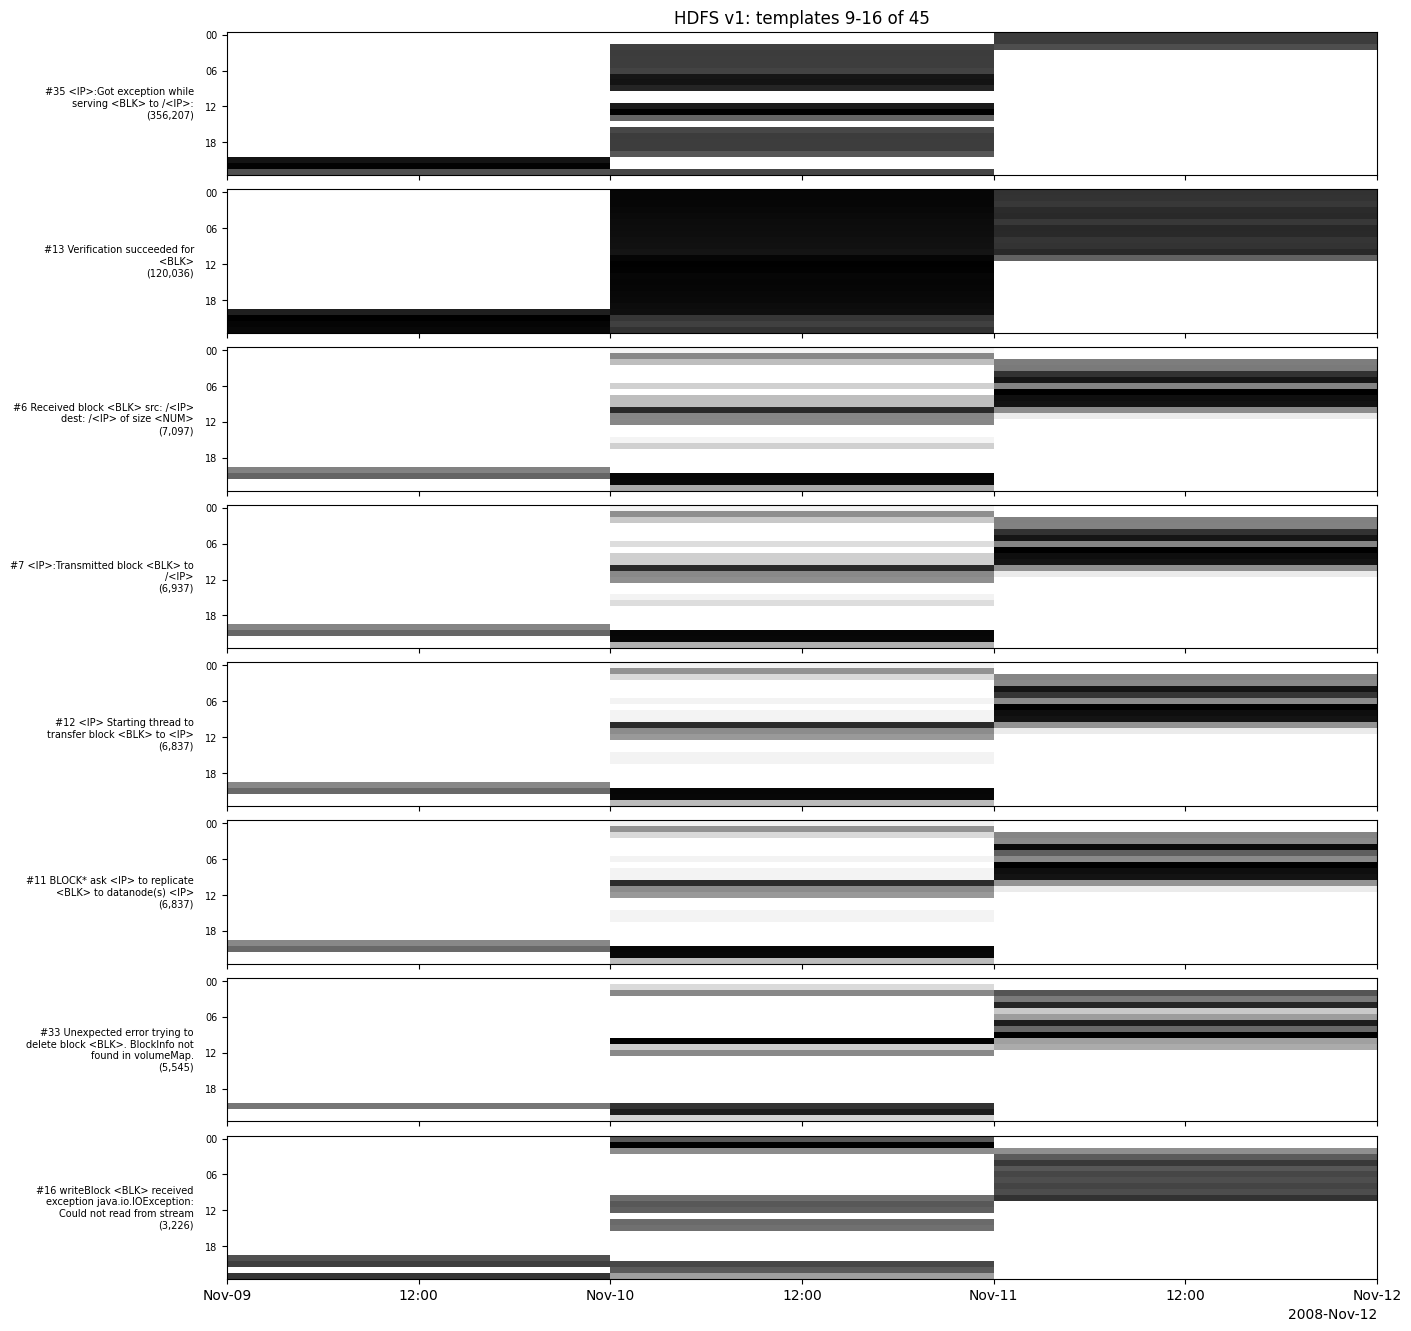

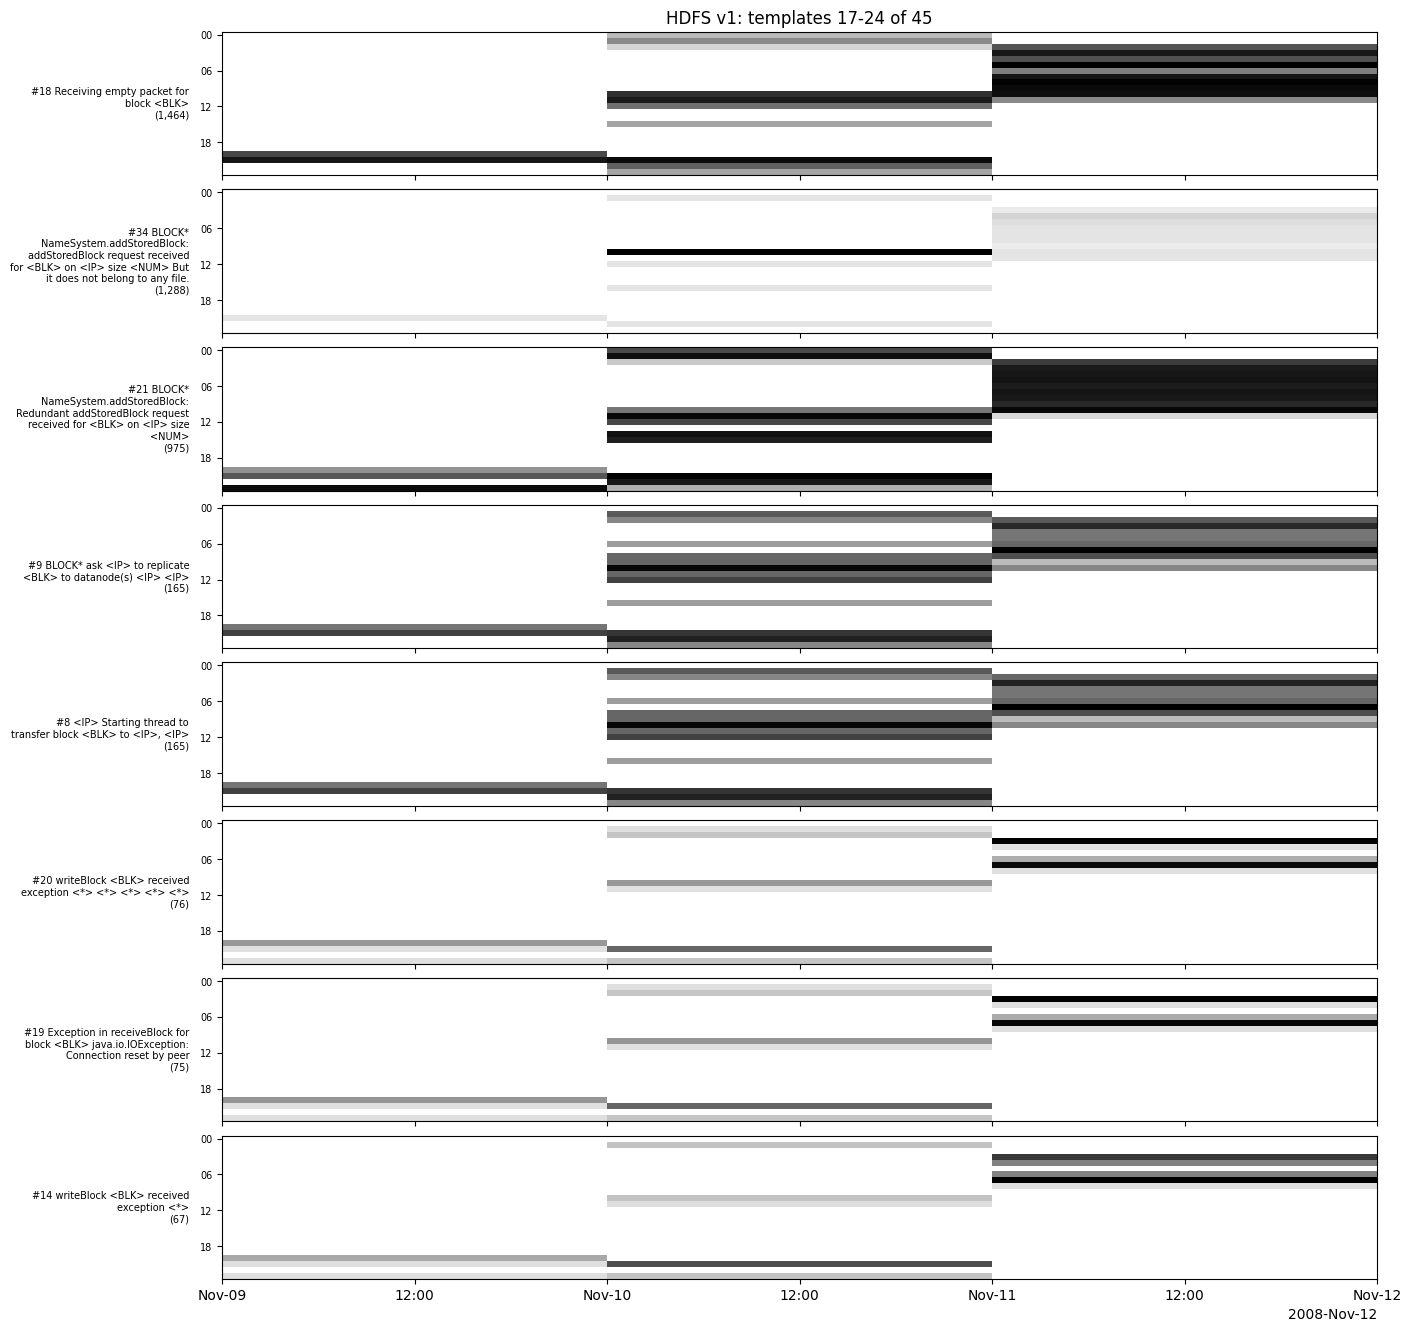

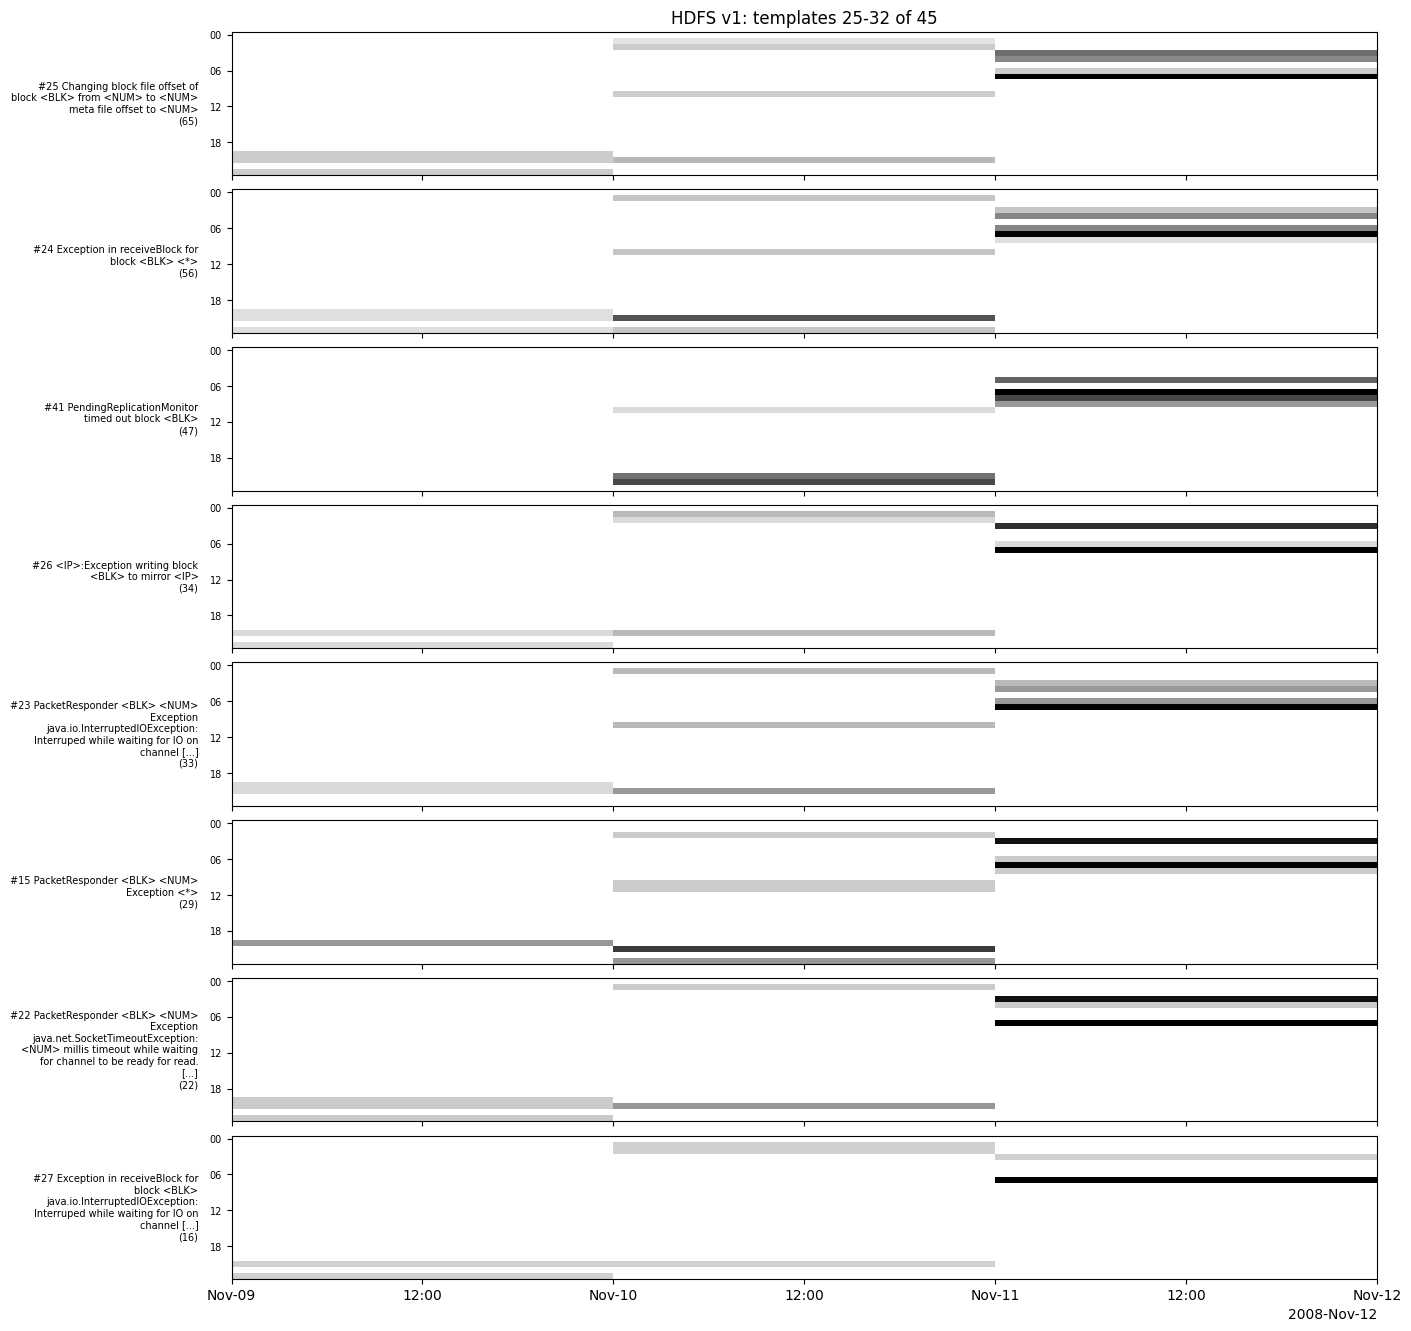

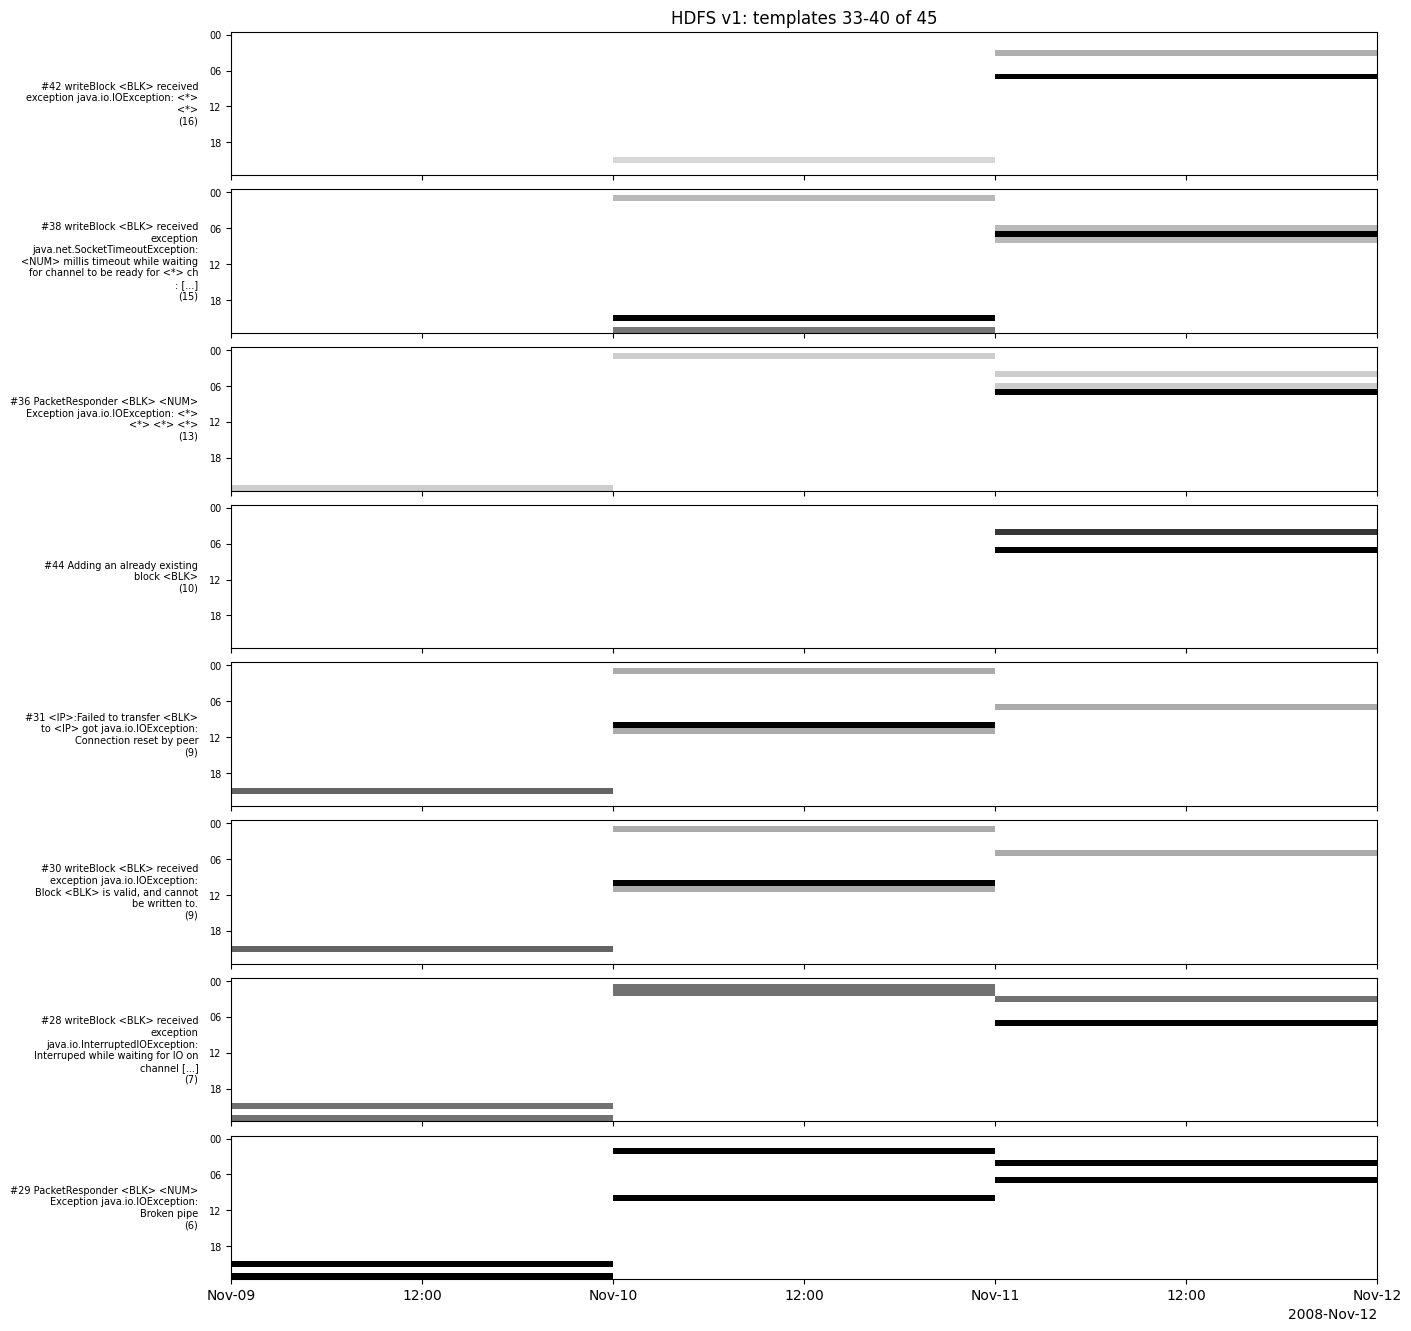

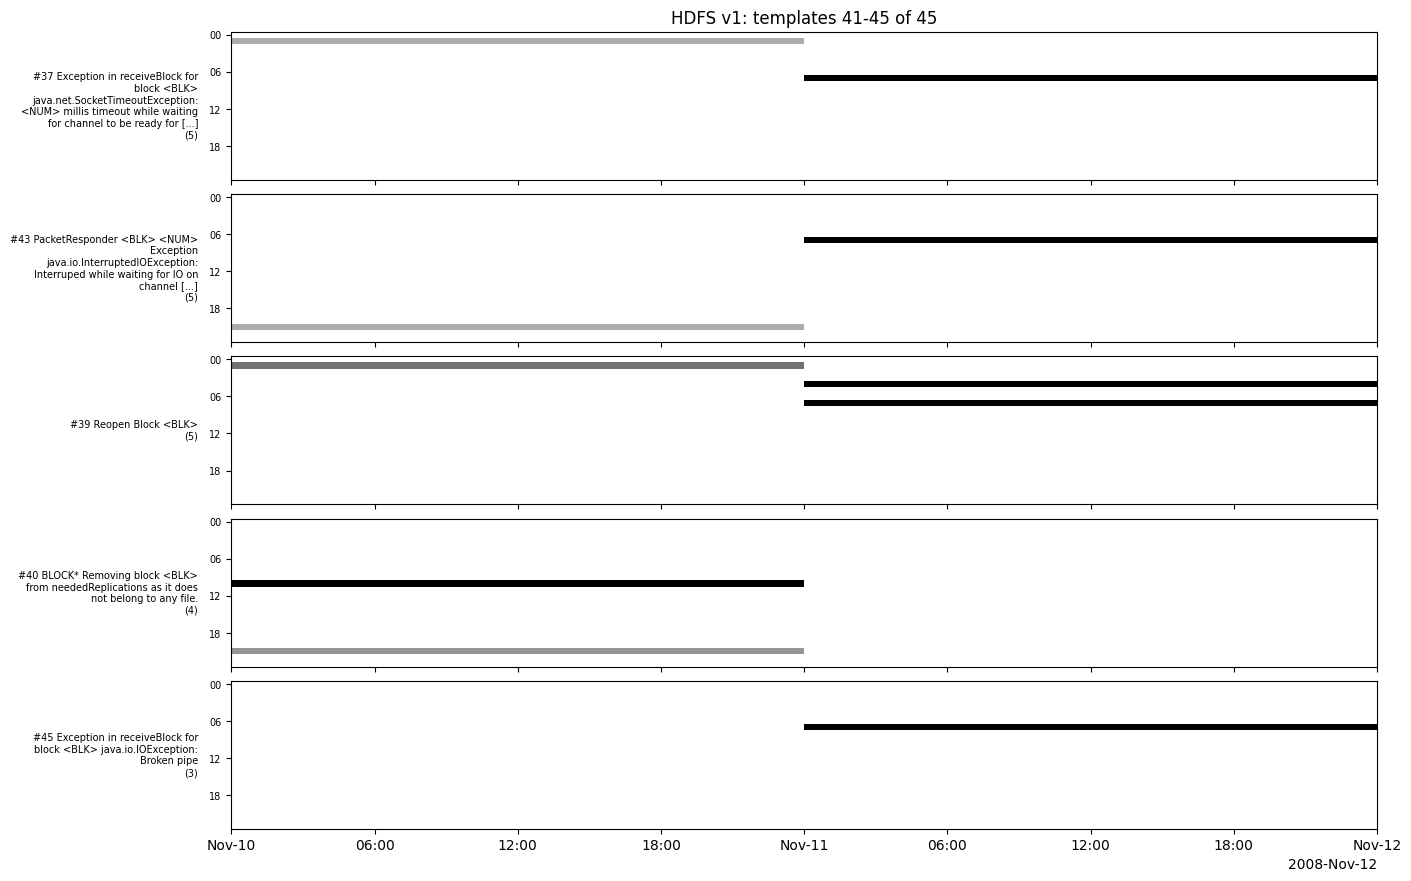

In [52]:
rows_v1 = list(count_per_window(hdfs_v1_reader, minutes=60))
df_v1 = template_hour_frame(rows_v1, ['level', 'component', 'template_id'], hdfs_v1_miner)
for fig in plot_template_pages(df_v1, top=100, title='HDFS v1'):
    plt.show()

Как и ожидалось, превалируют обыкновенные манипуляции с блоками (движения, запись, удаления). Самые редкие шаблоны - это исключения. Аналогично посмотрим другие системы:

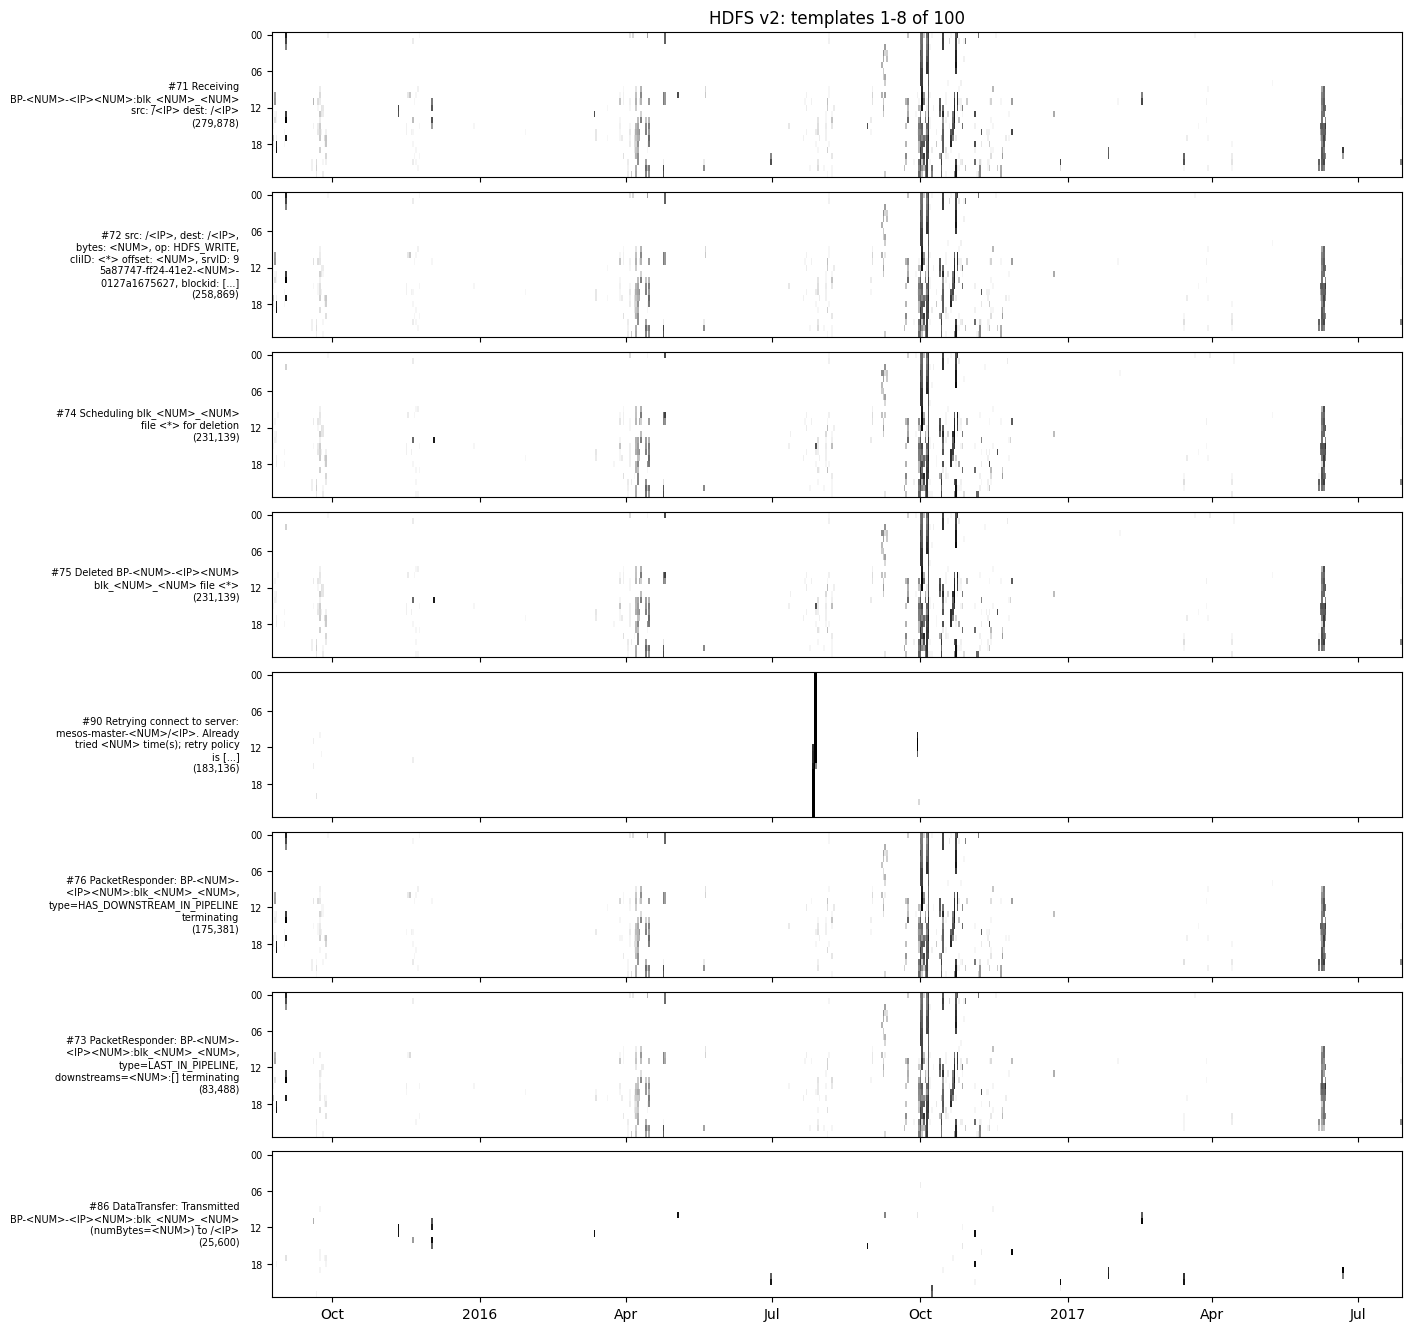

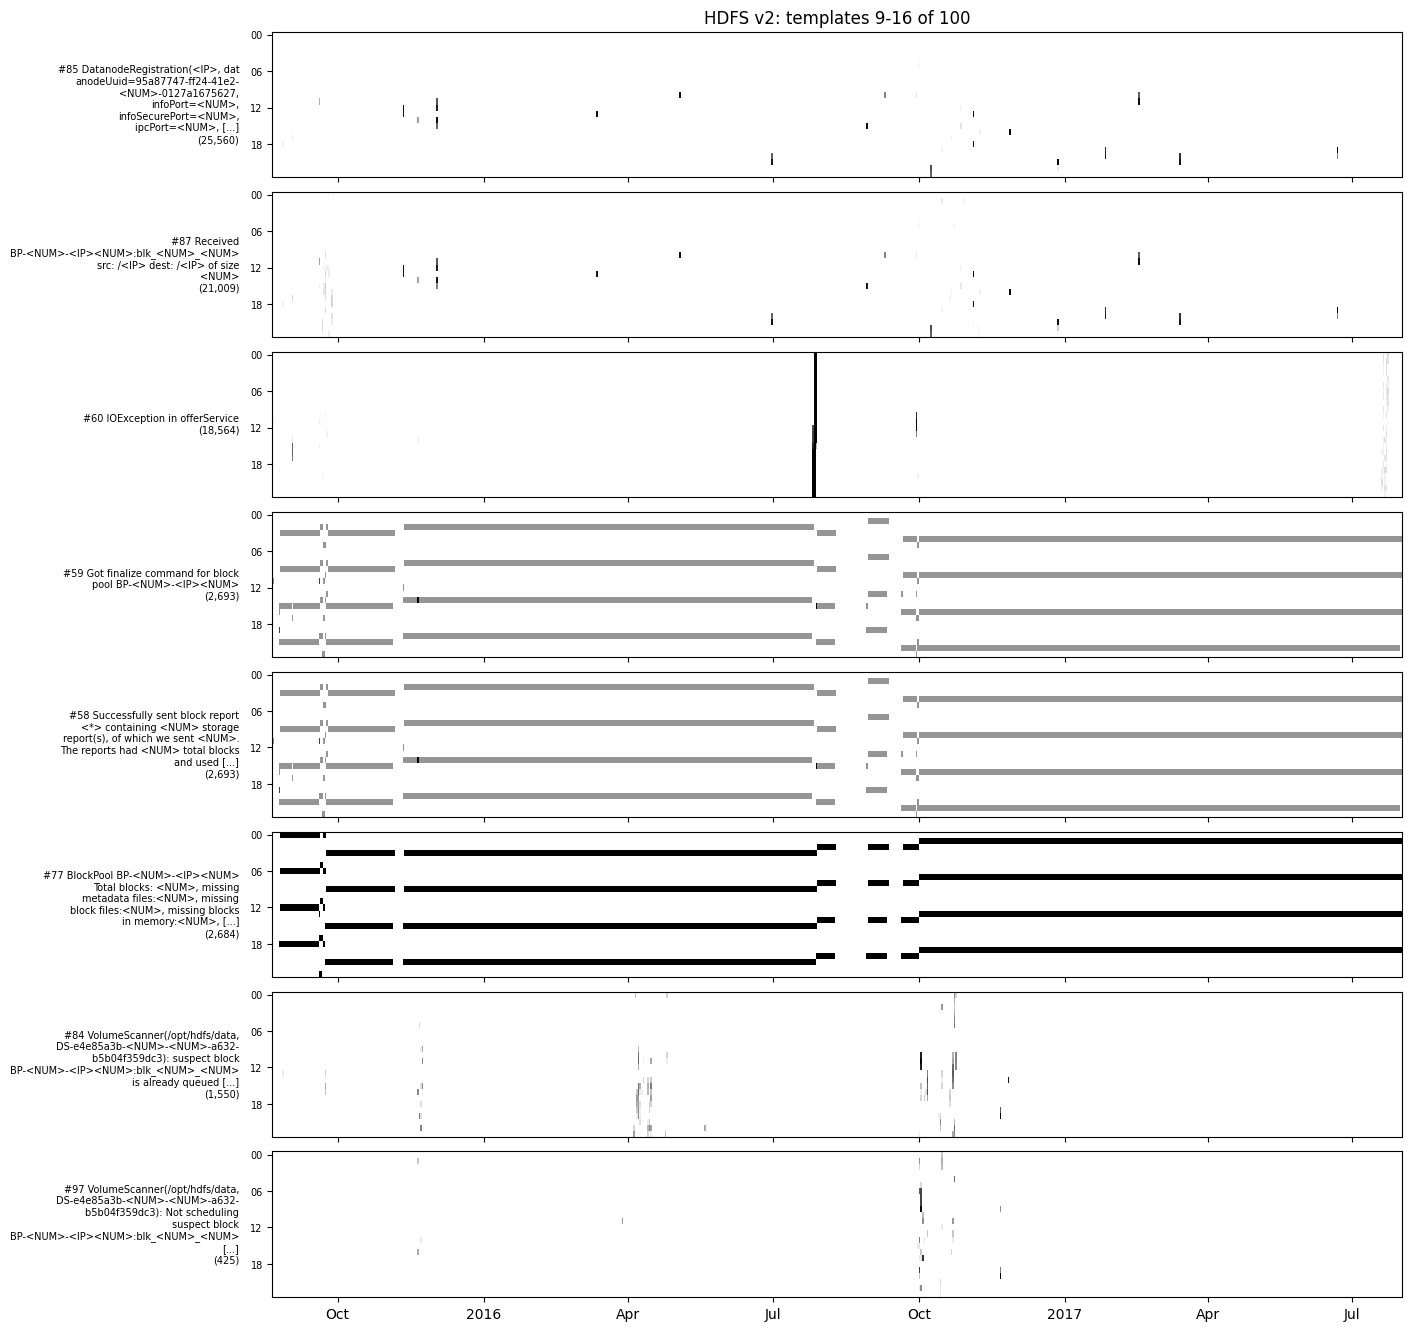

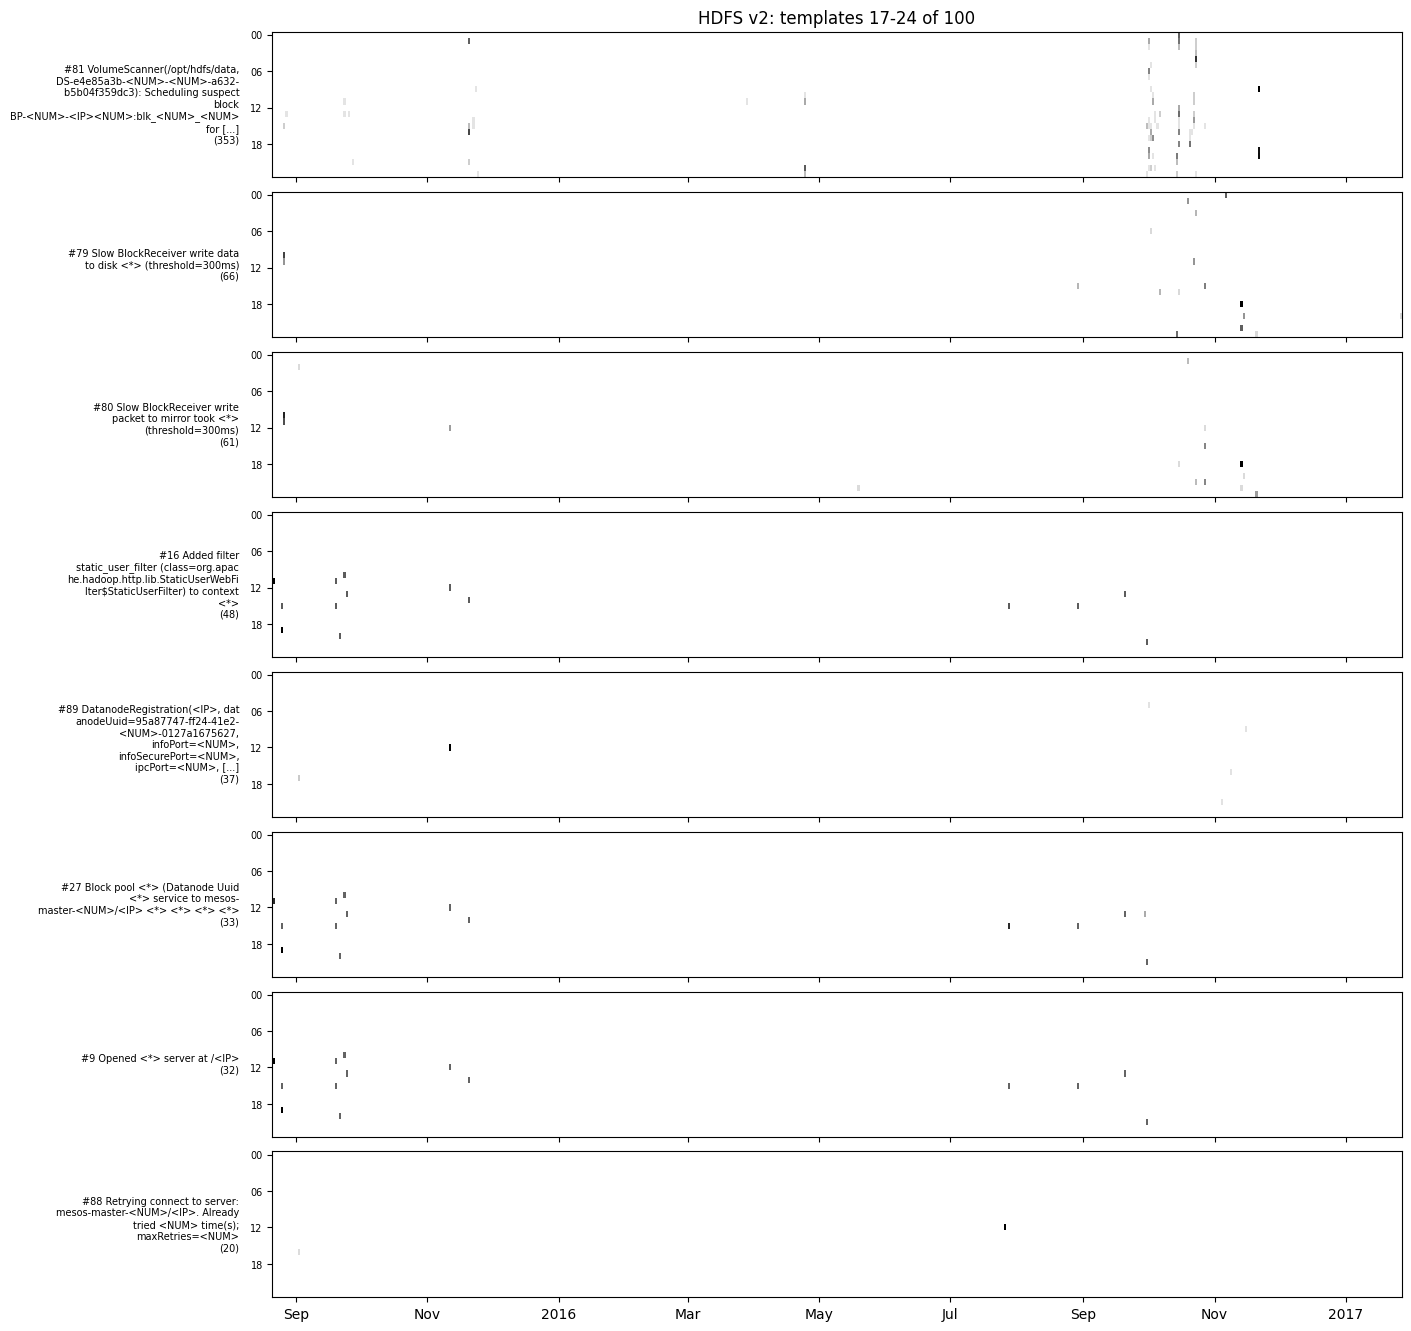

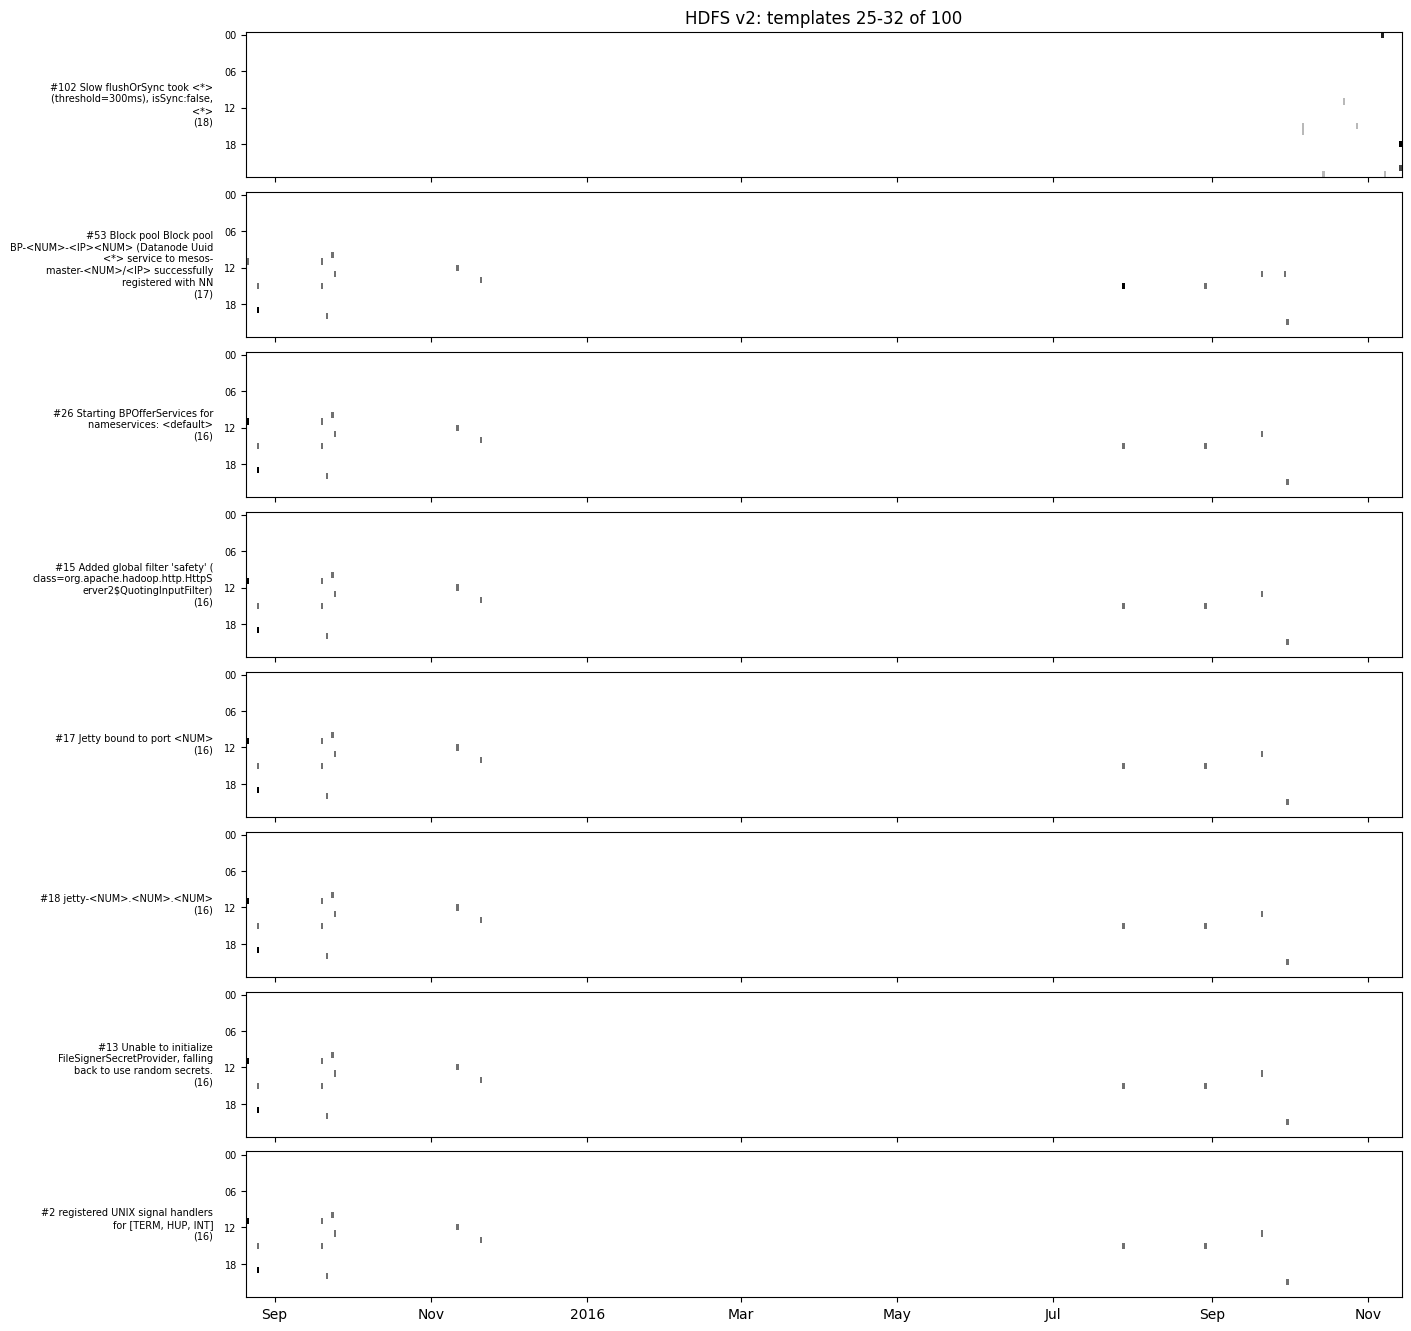

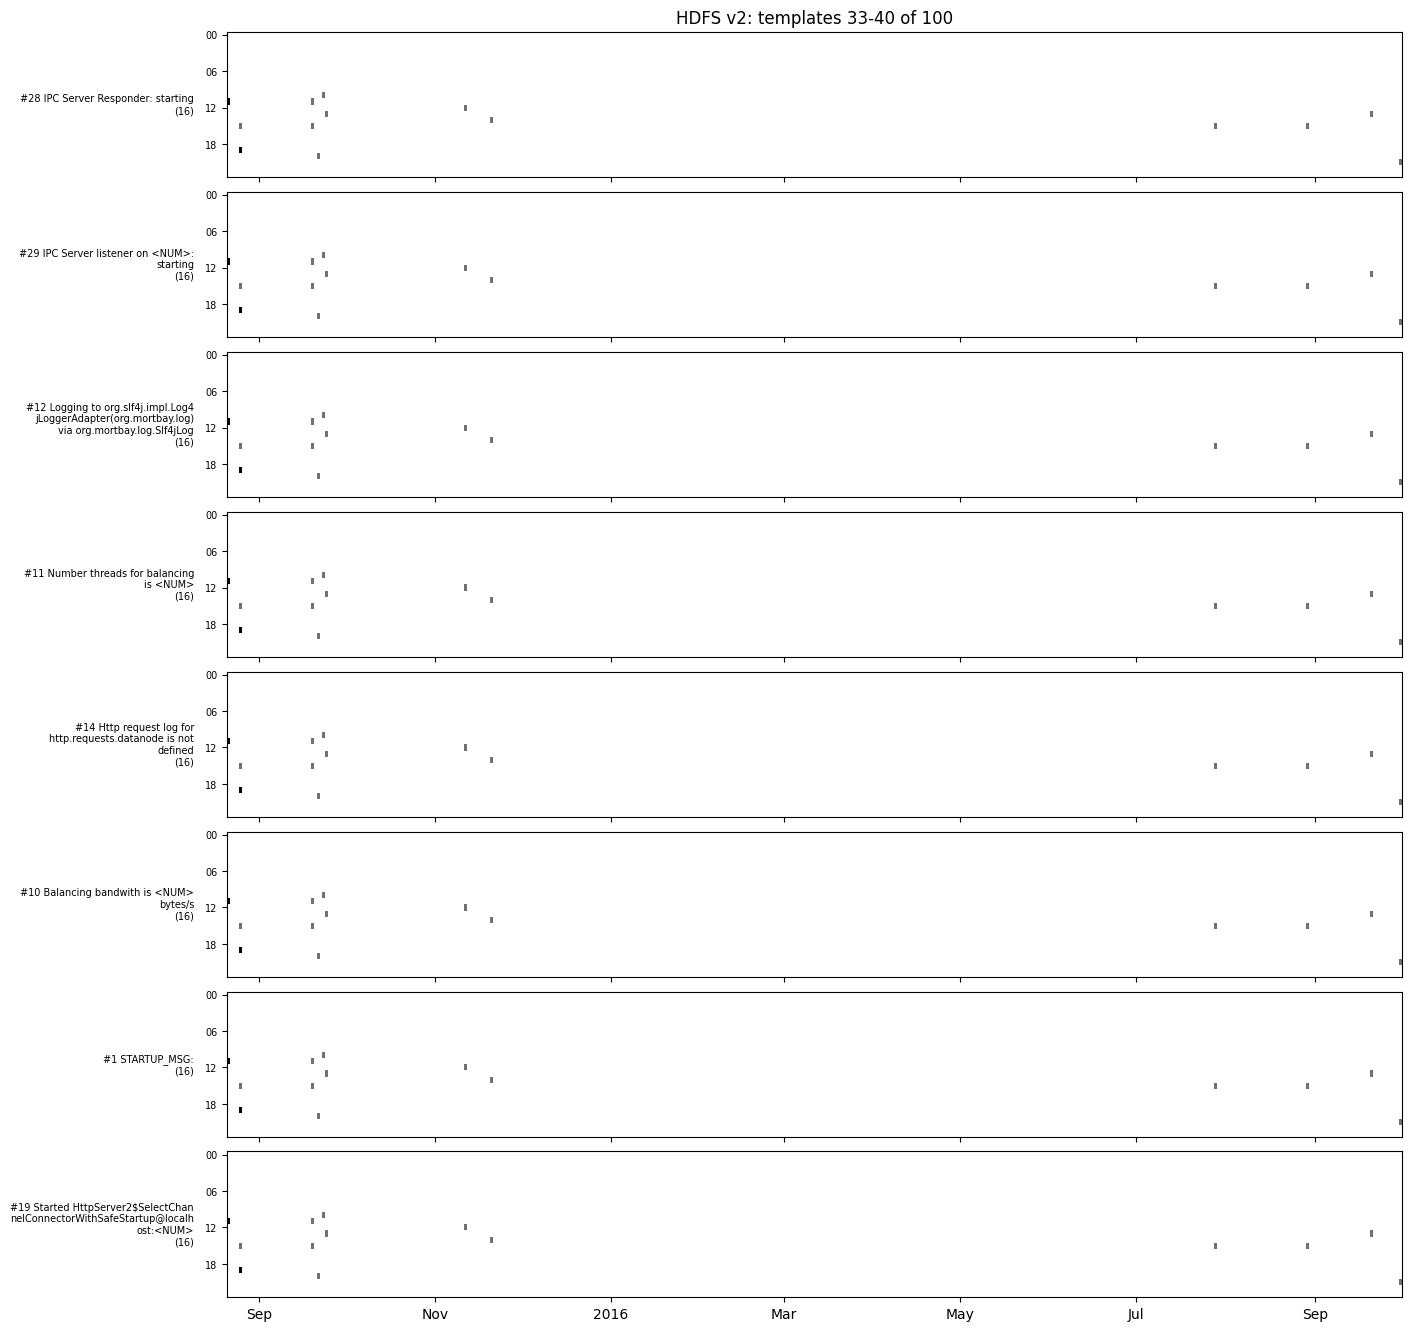

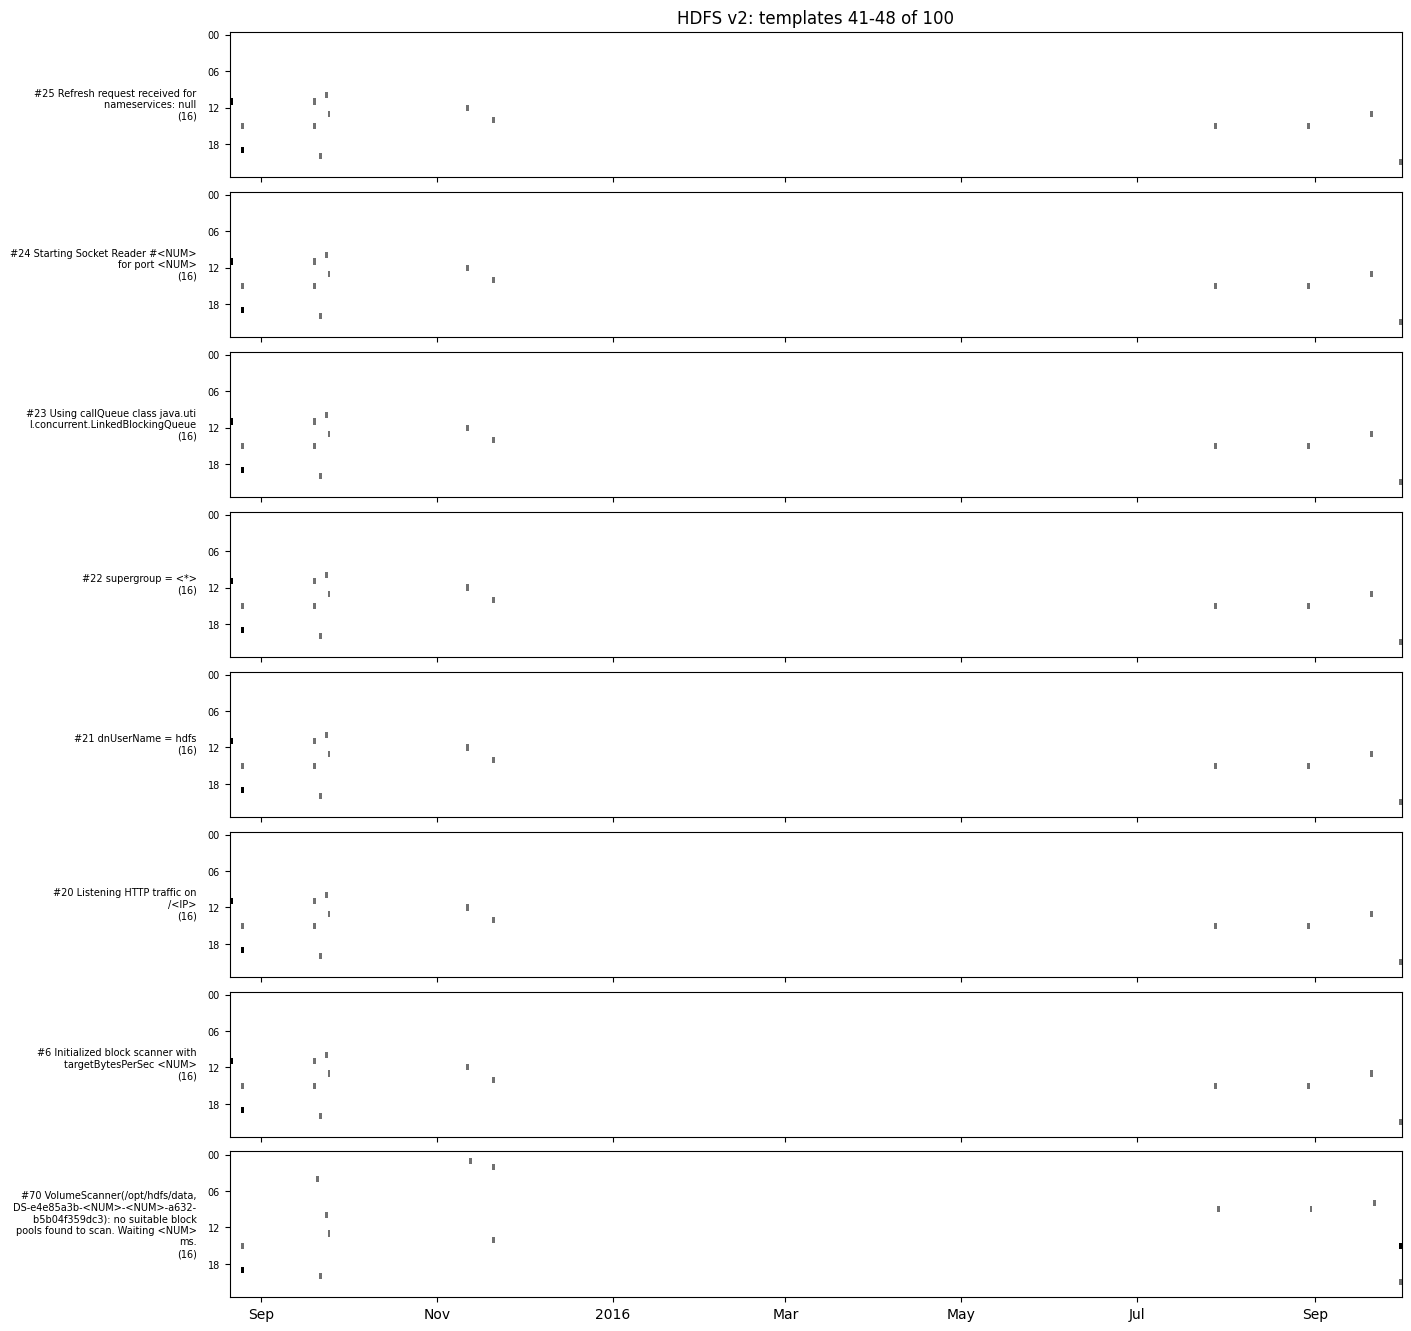

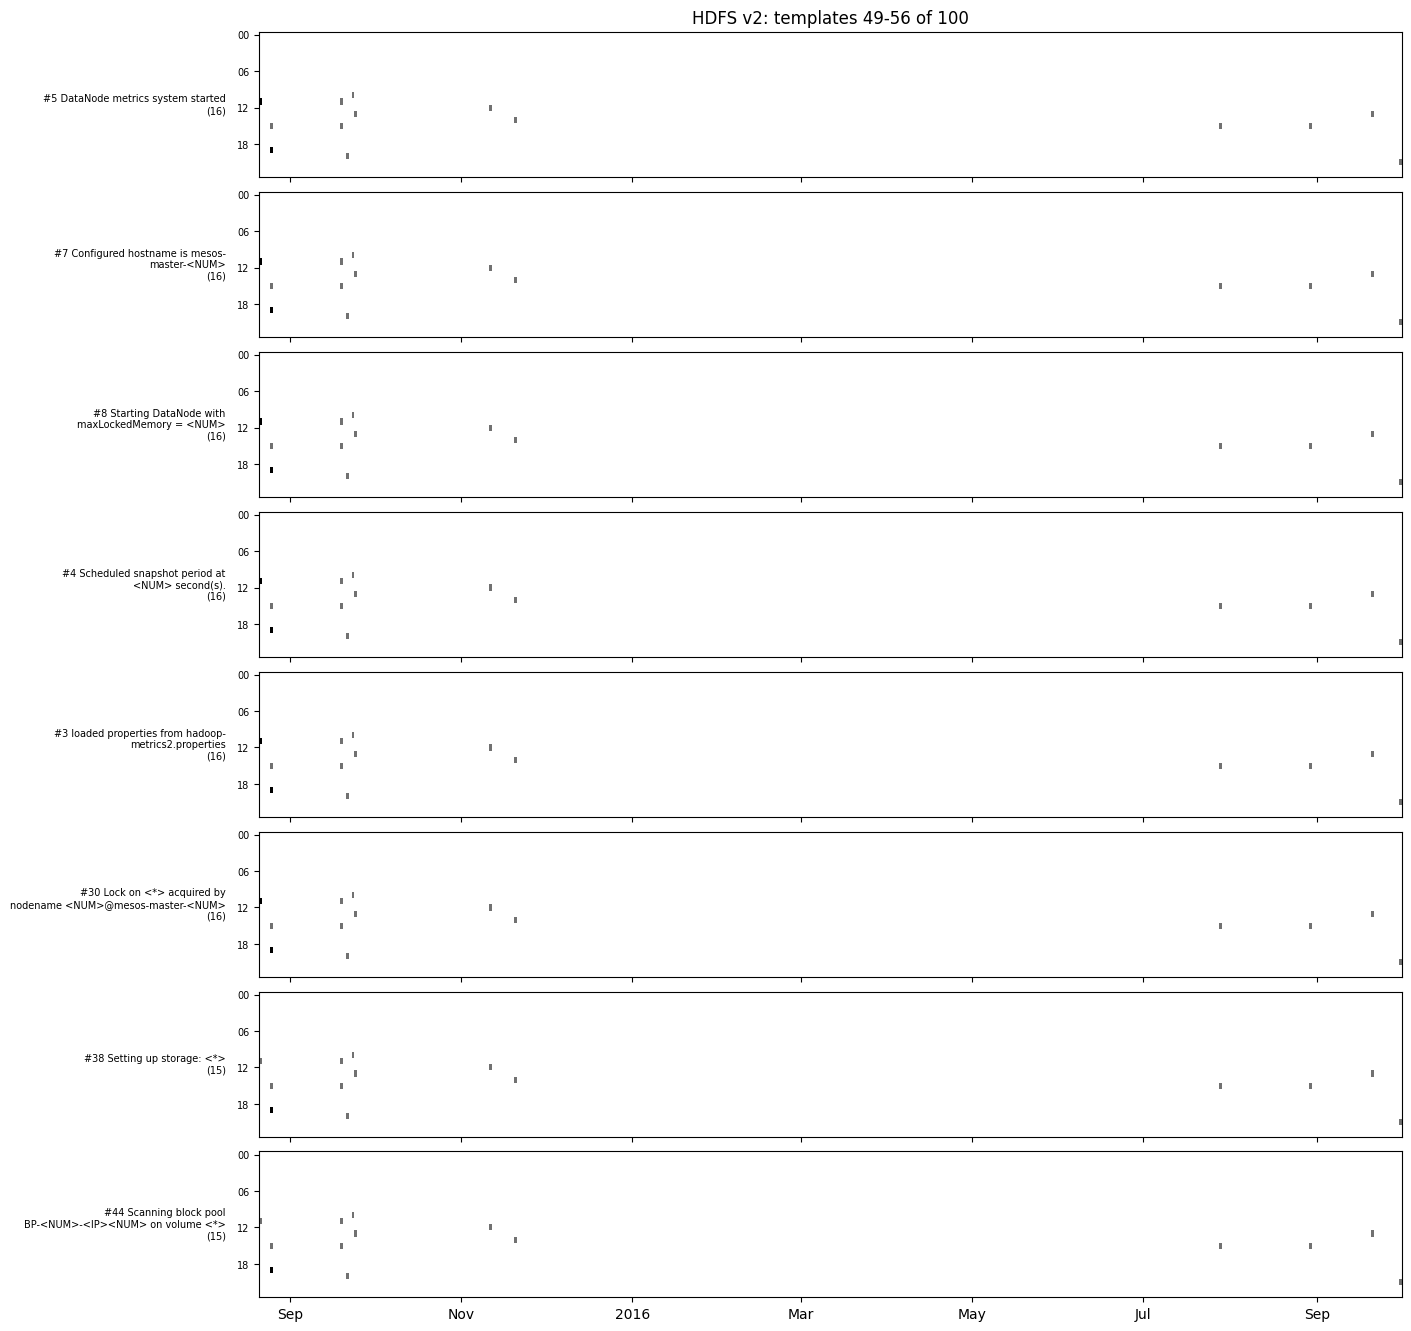

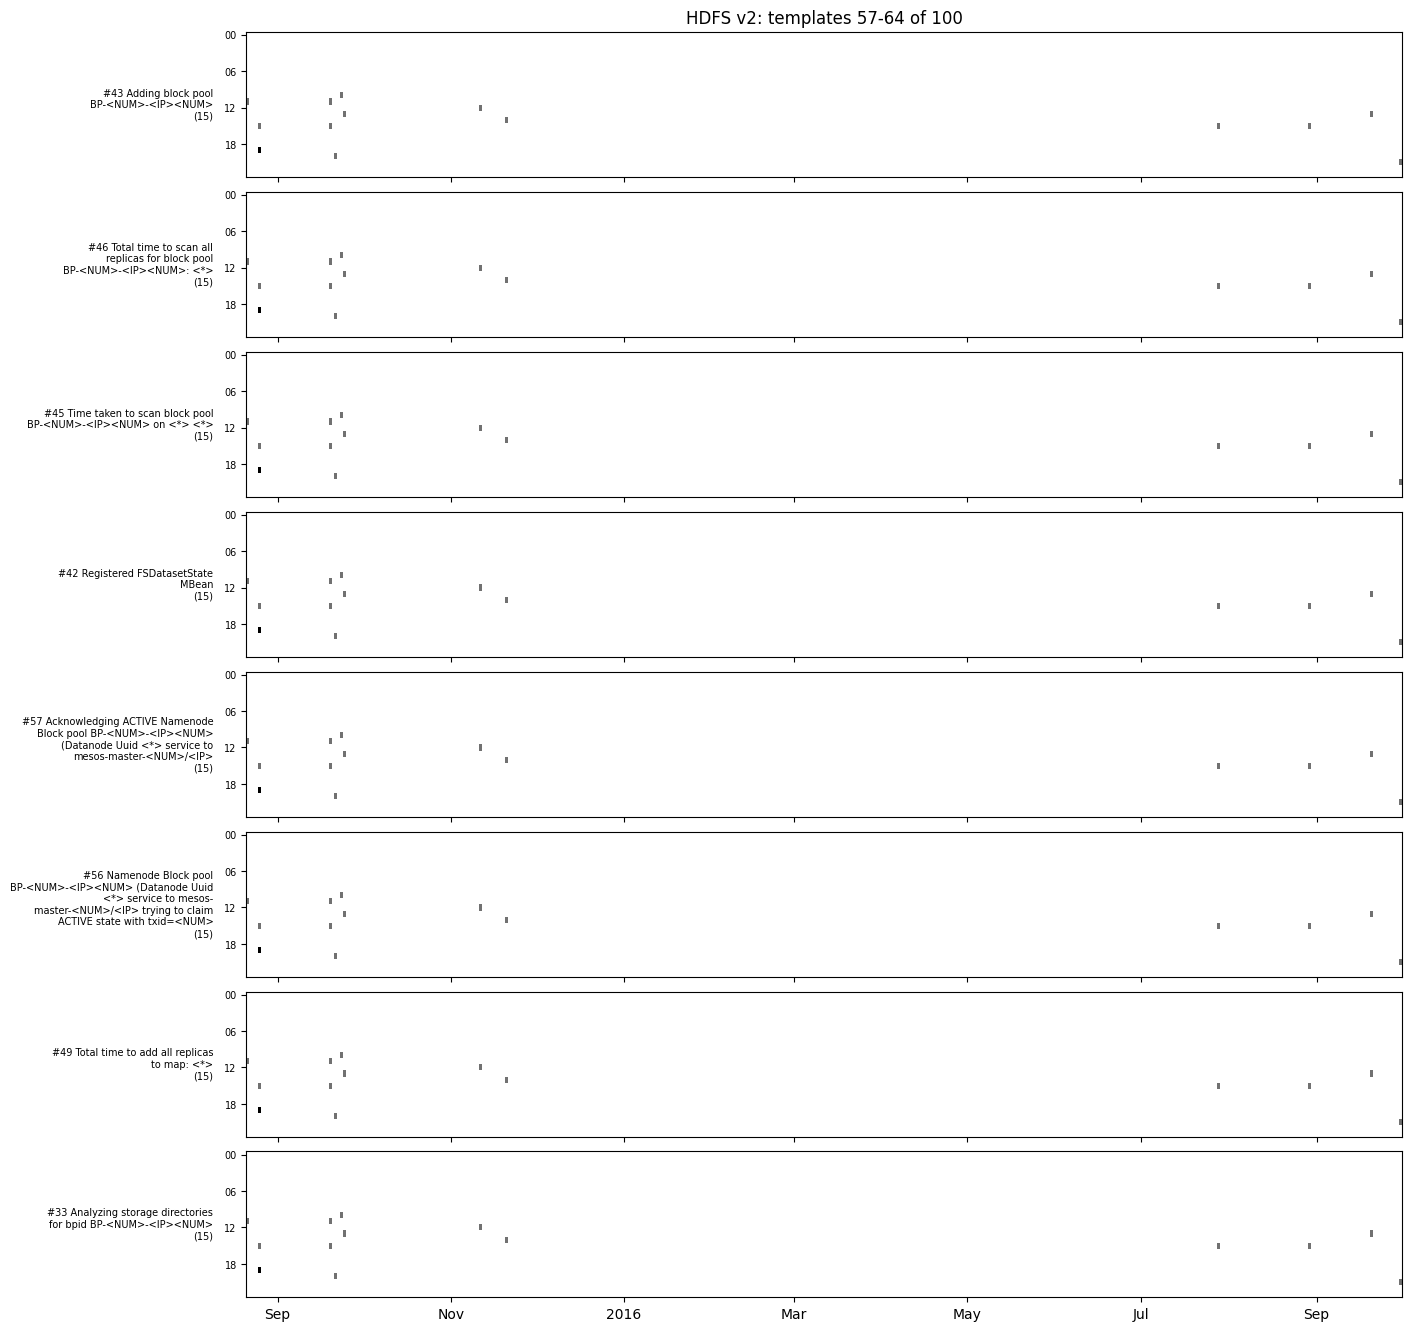

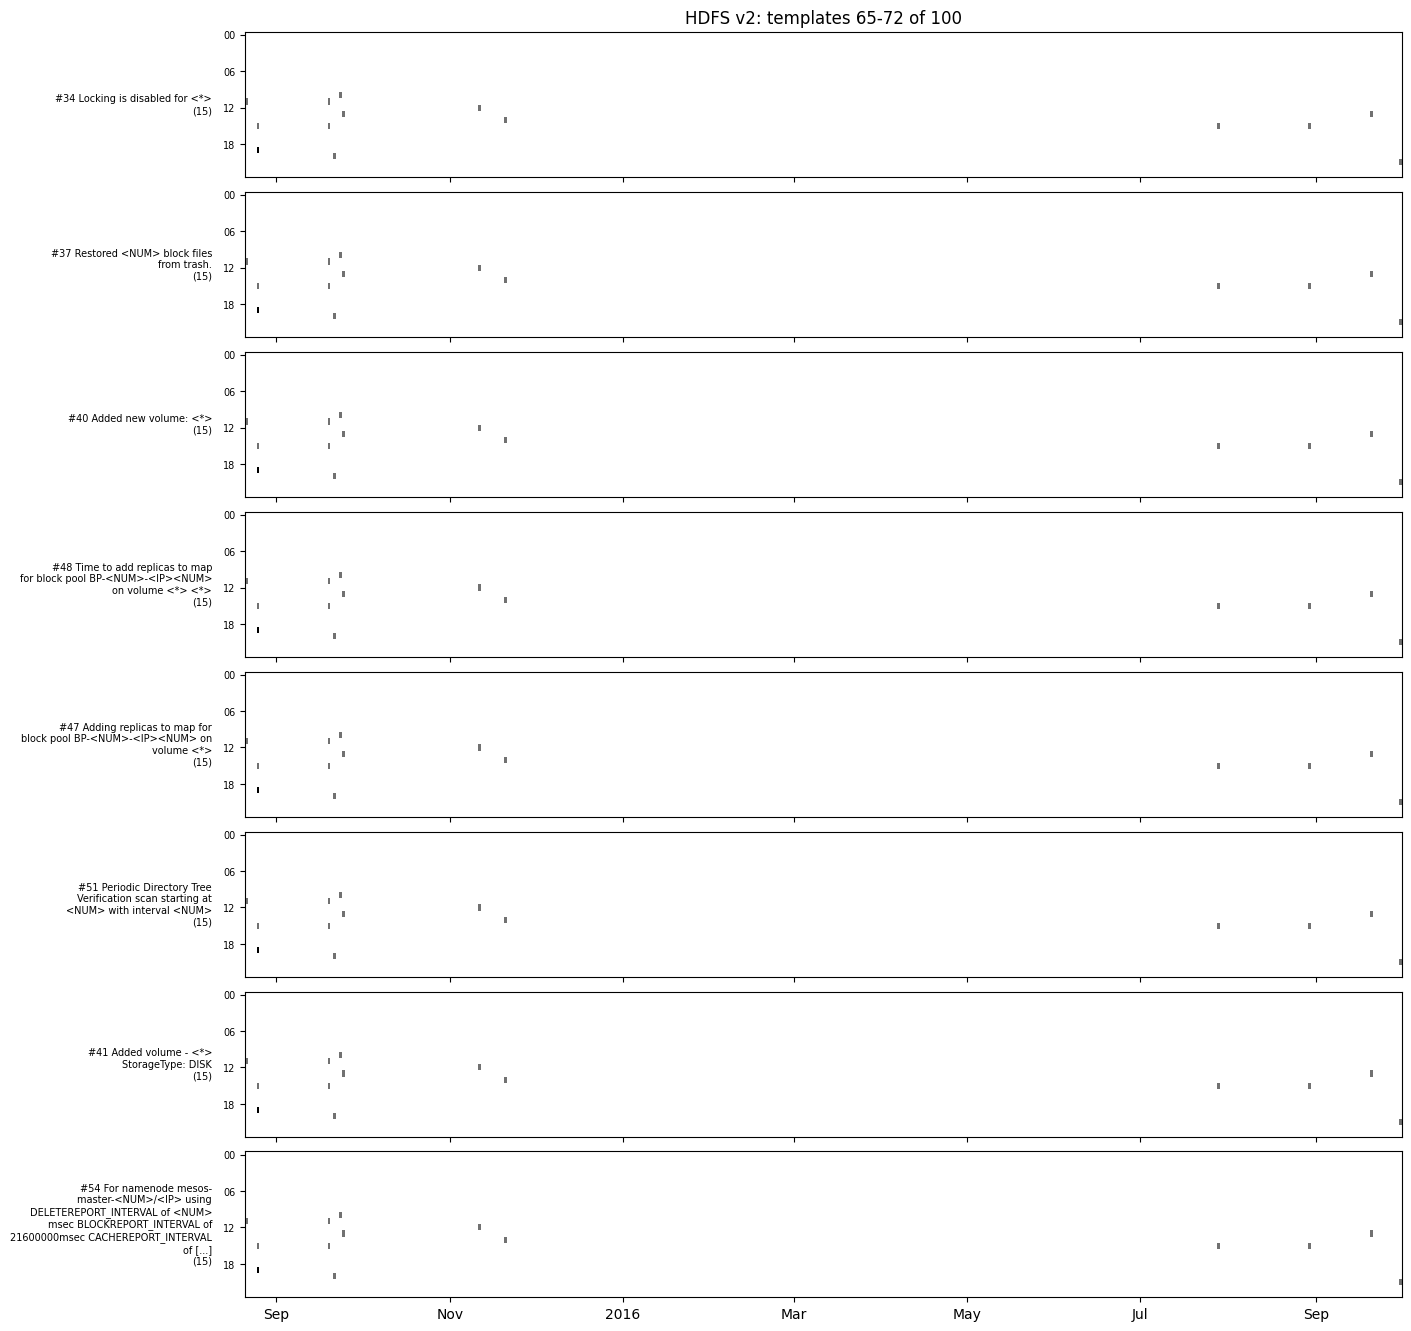

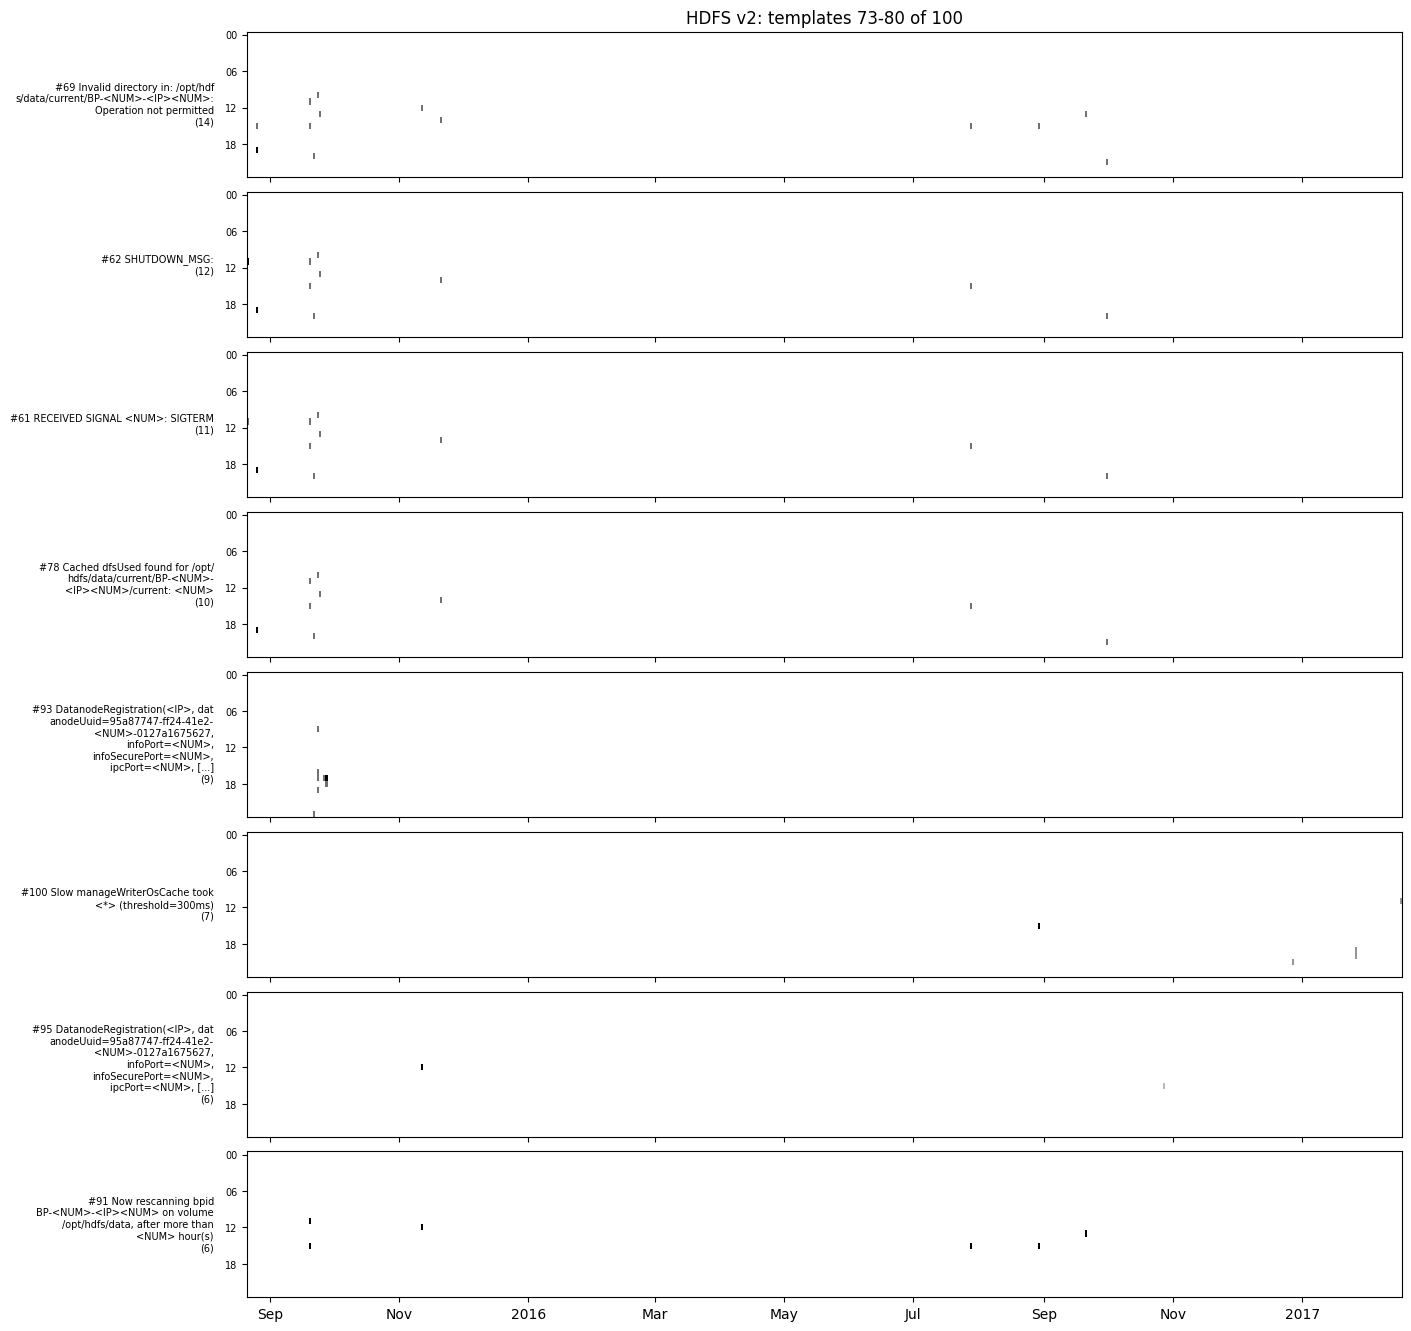

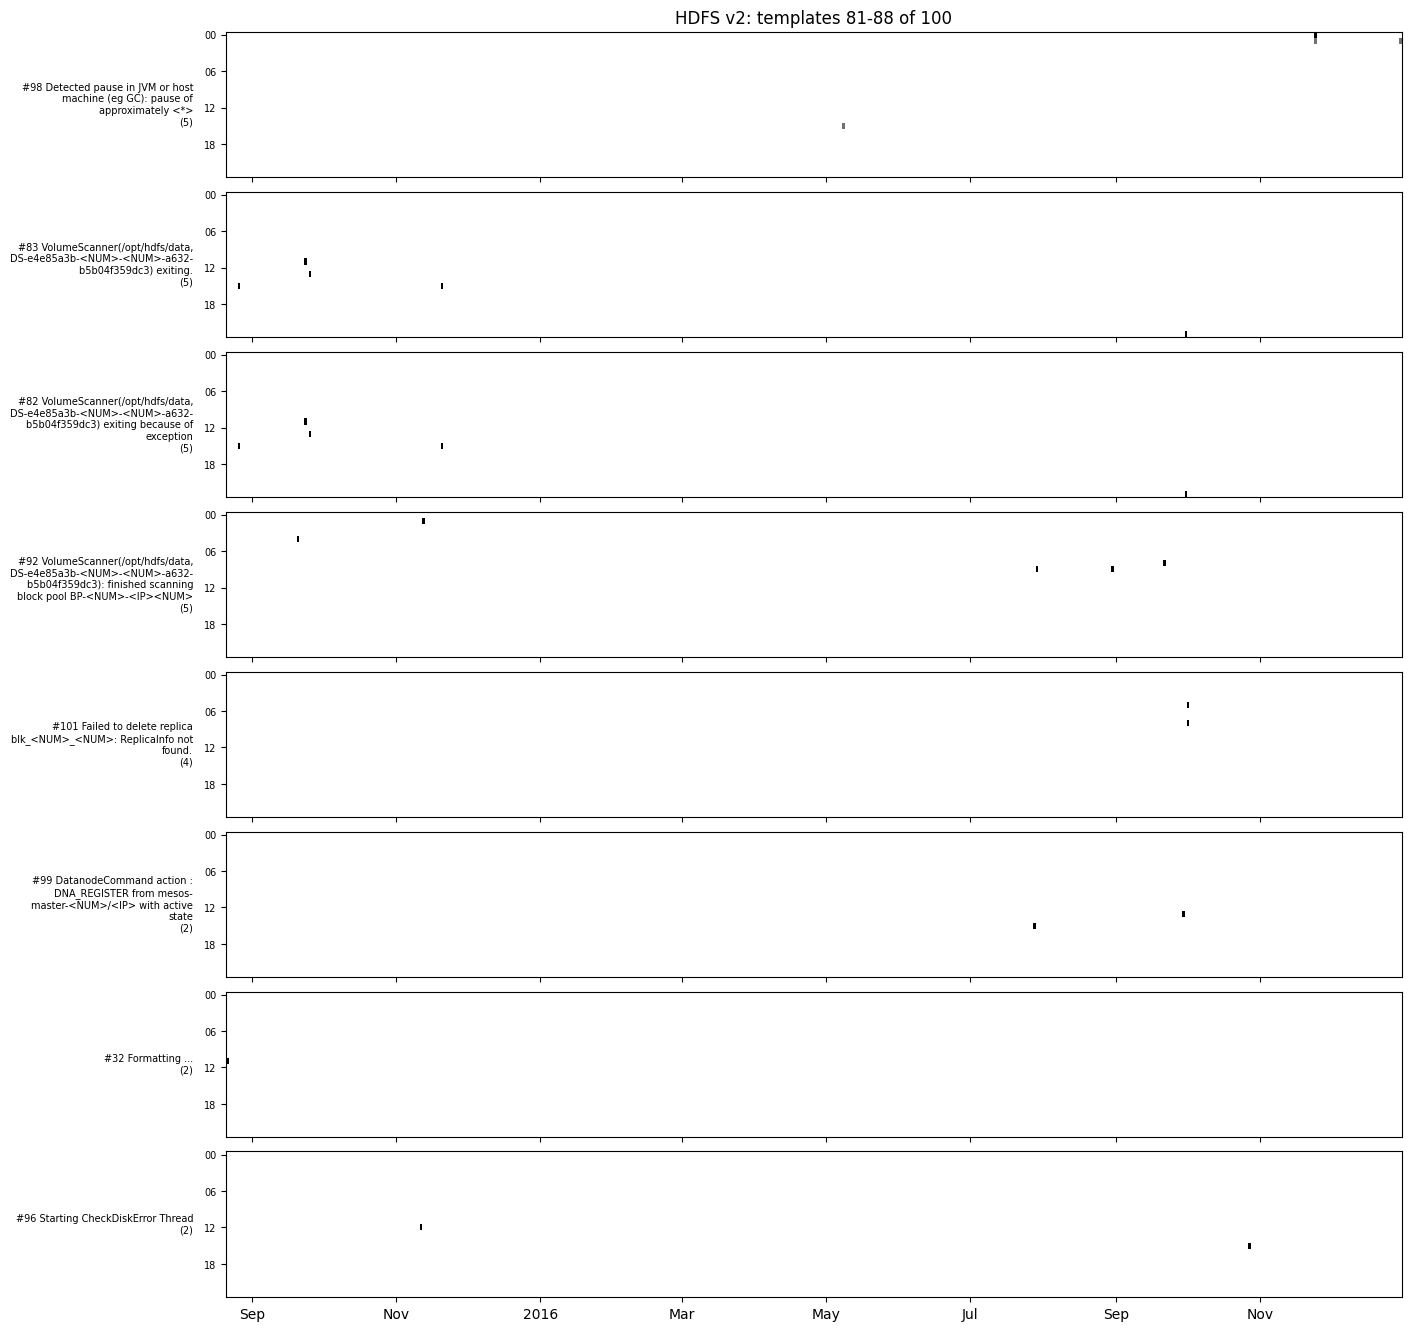

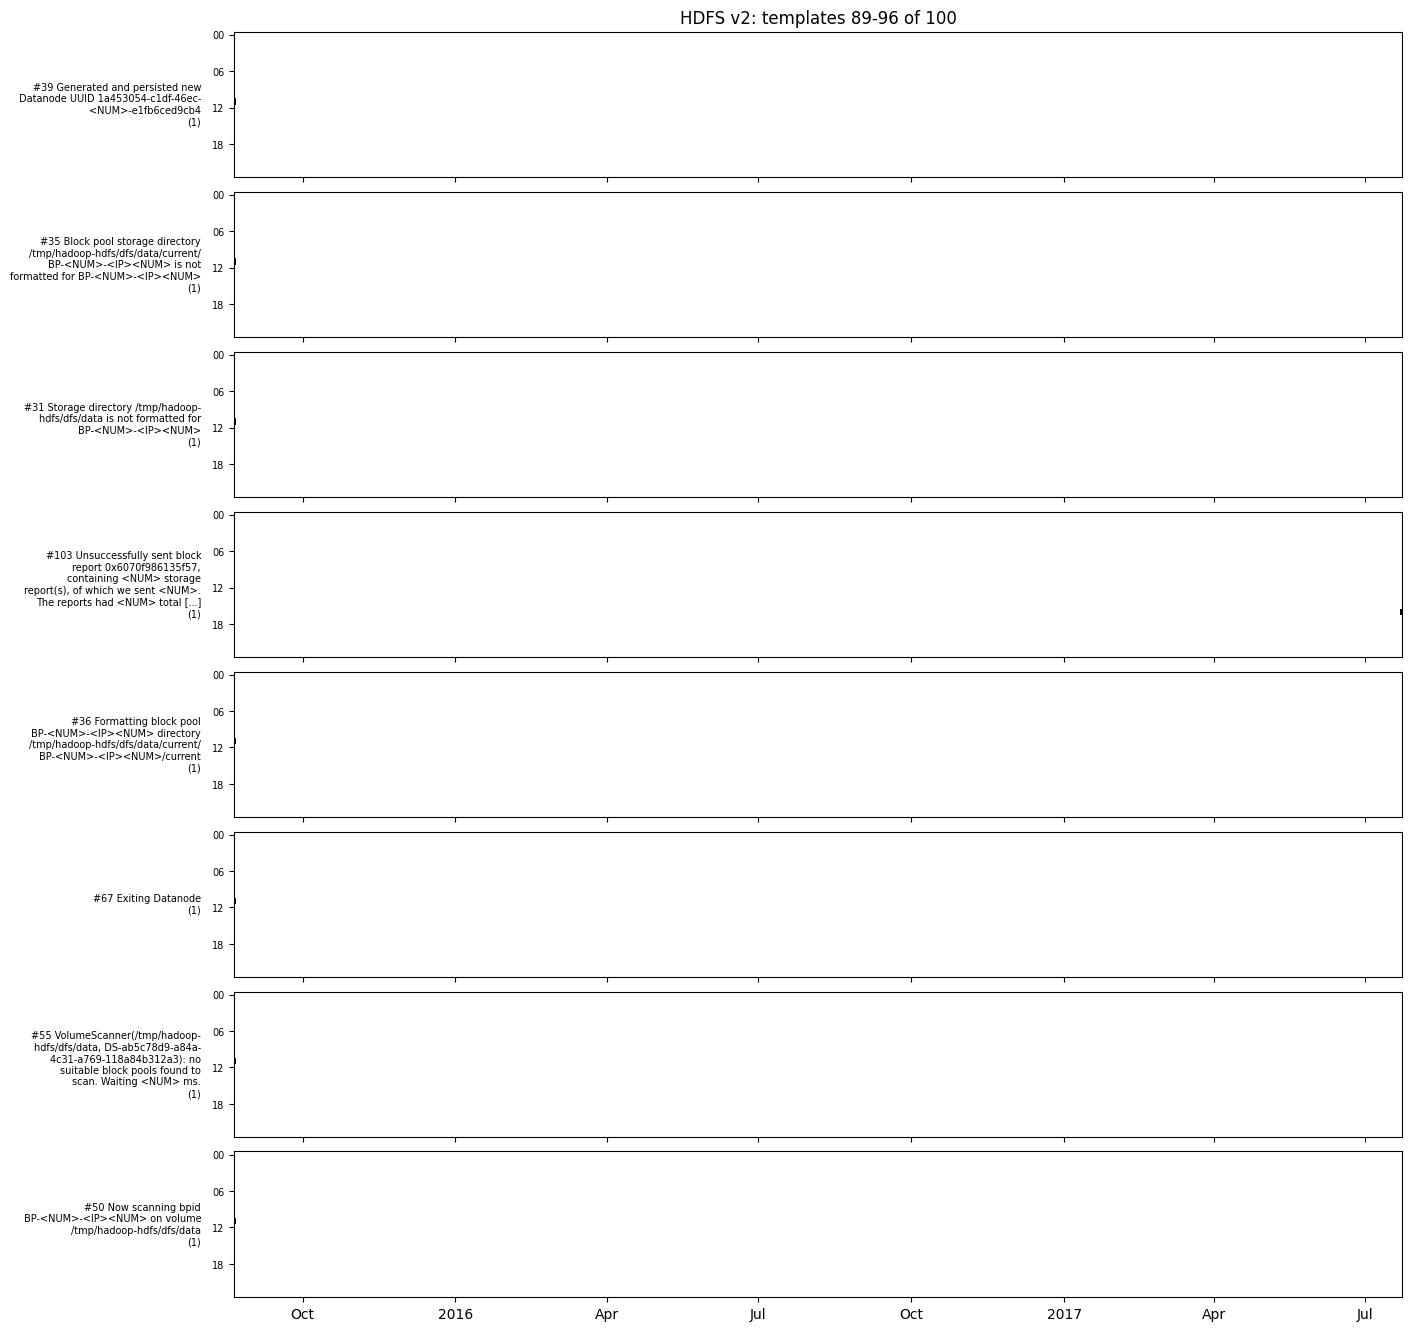

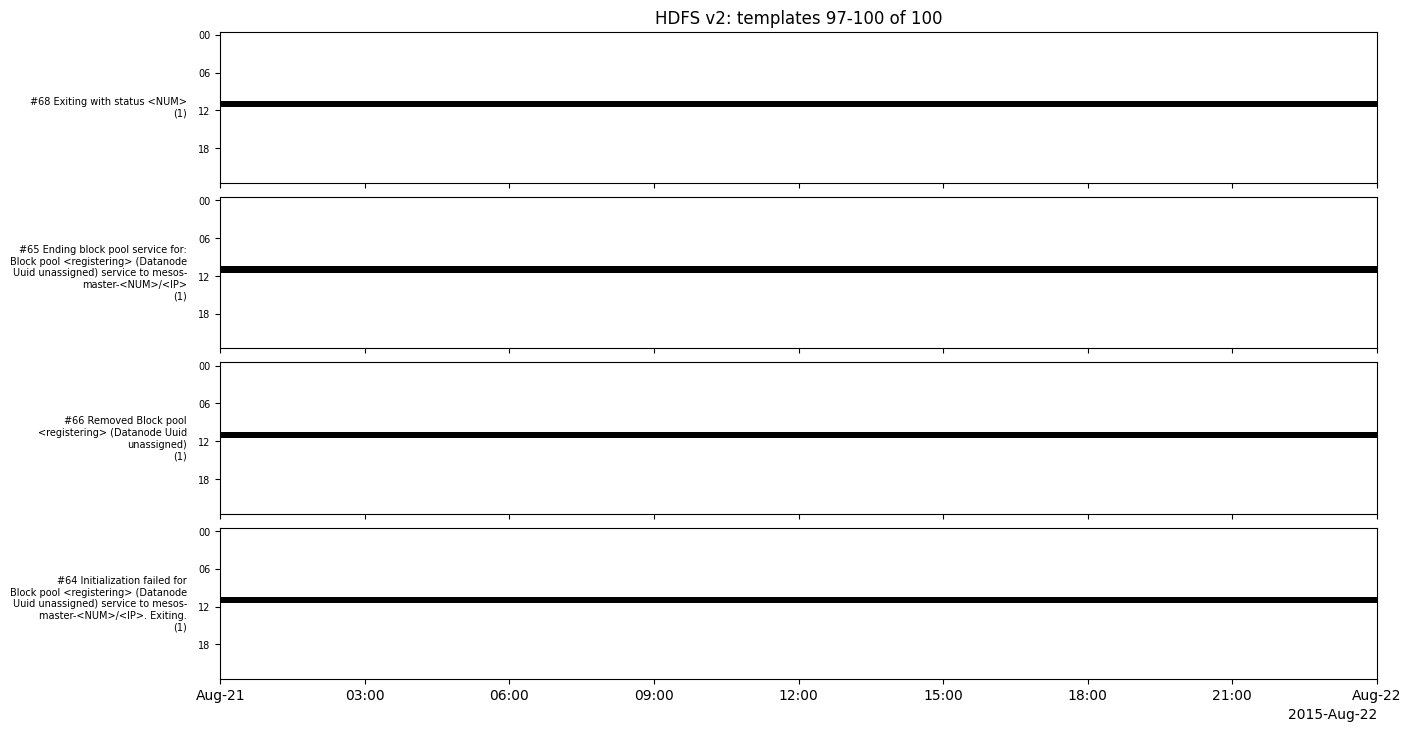

In [54]:
rows_datanode_v2 = list(count_per_window(hdfs_v2_datanode_reader, minutes=60))
df_datanode_v2 = template_hour_frame(rows_datanode_v2, ['level', 'component', 'template_id'], miner_v2)
for fig in plot_template_pages(df_datanode_v2, top=100, title='HDFS v2'):
    plt.show()

Видим, как и в предыдущих чартах, всплеск сообщений (повышенная активность) ближе к середине. Есть и очень редкие шаблоны. Для нашего исследования аномалий делаем два вывода: нужно будет обращать внимание как на наличие очень редких сообщений, так и объем сообщений в целом. Чисто зрительно обе ситуации считаем аномалией.

Посмотрим Linux:

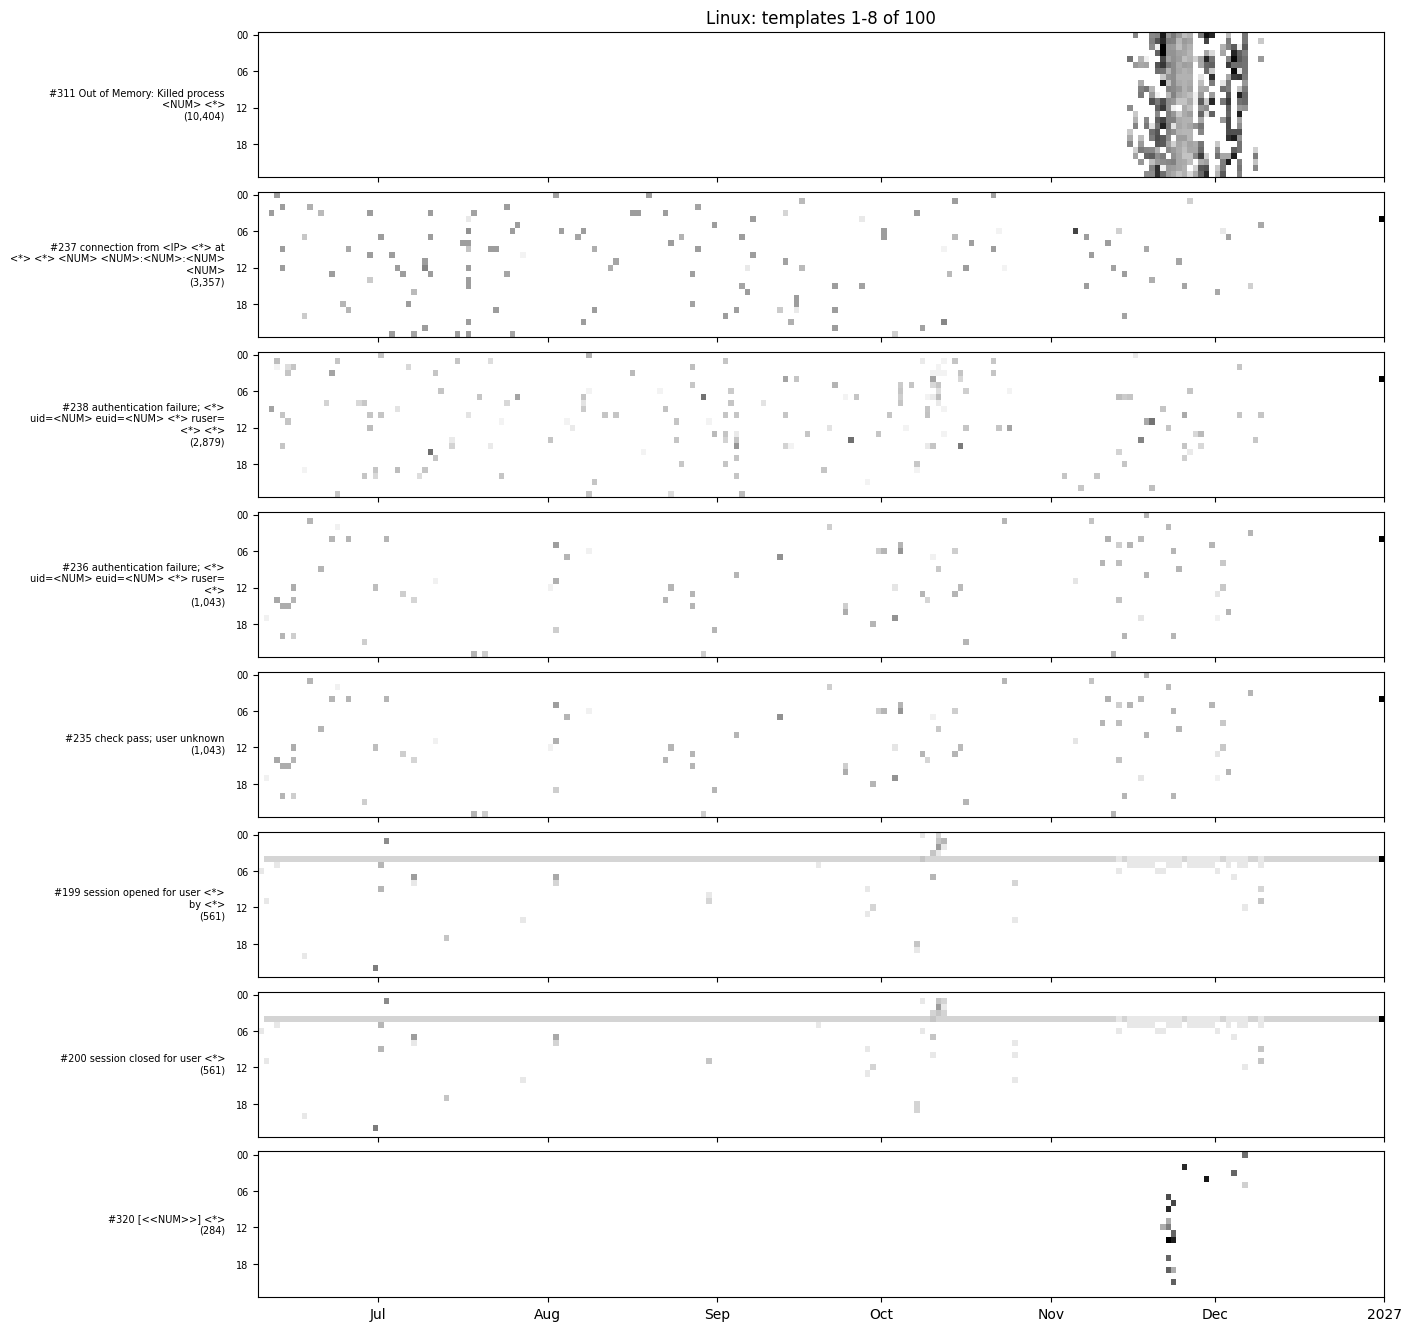

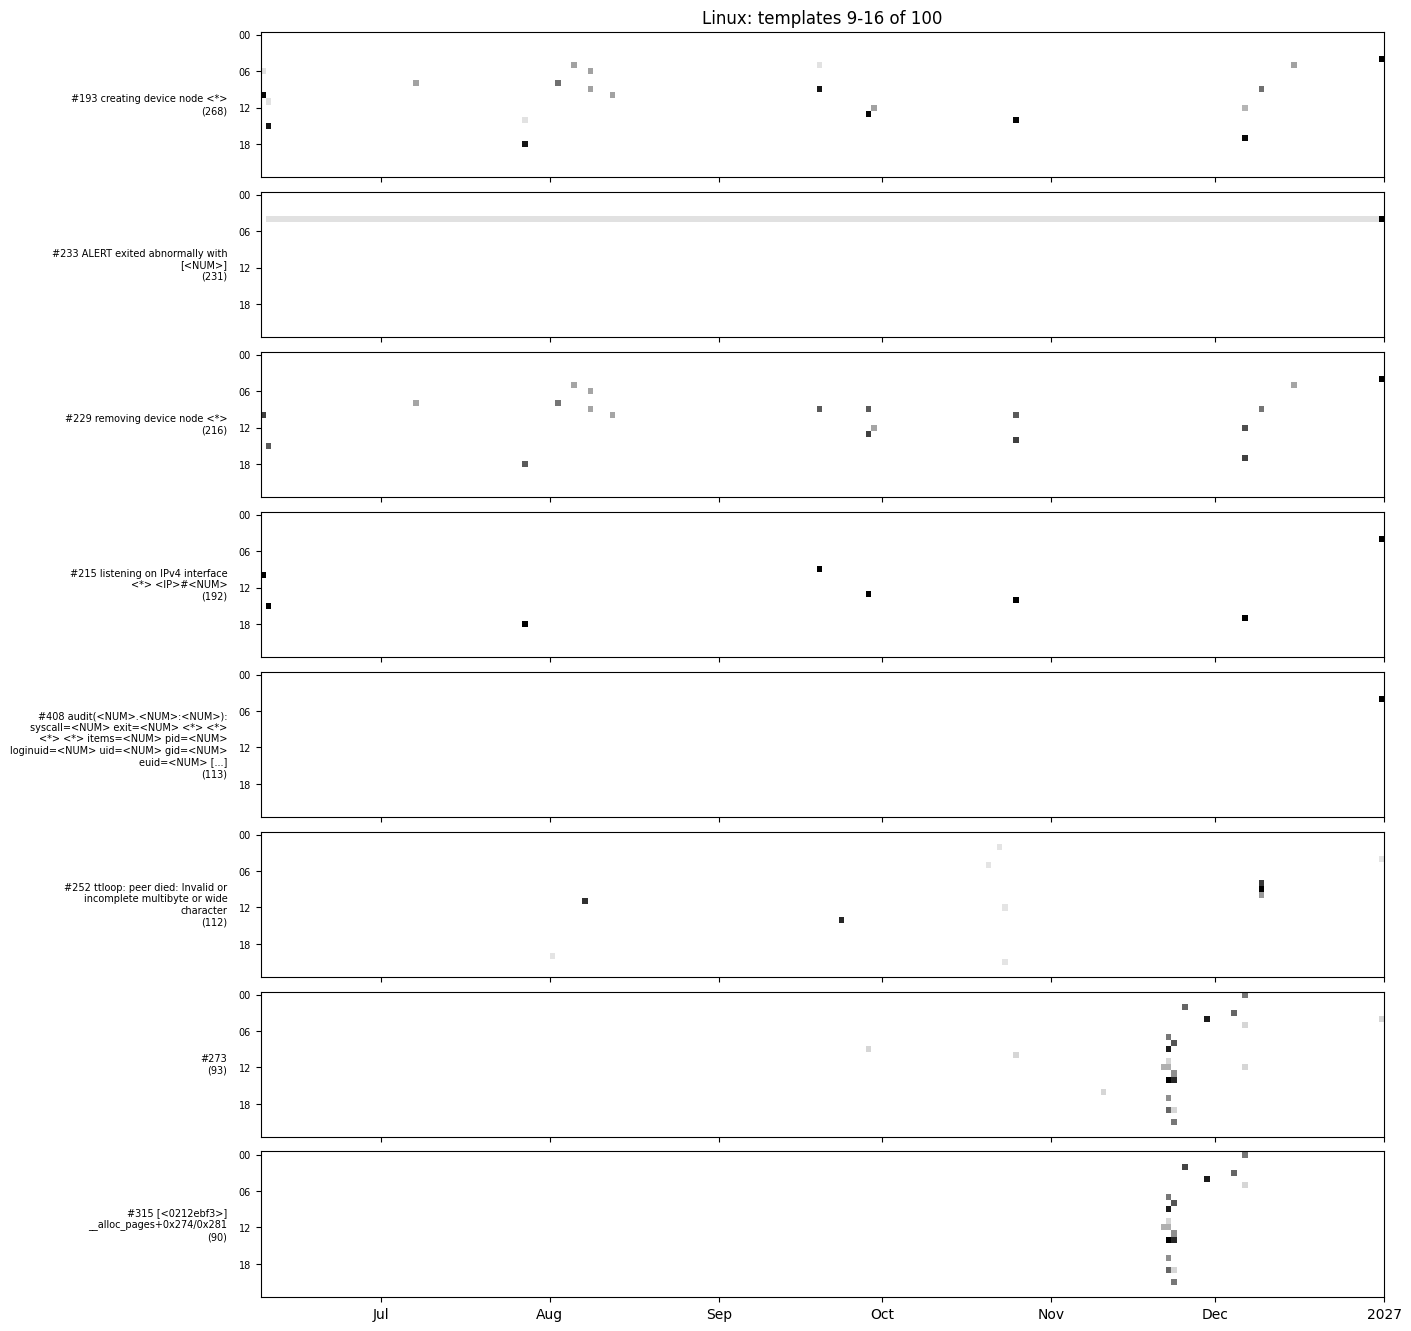

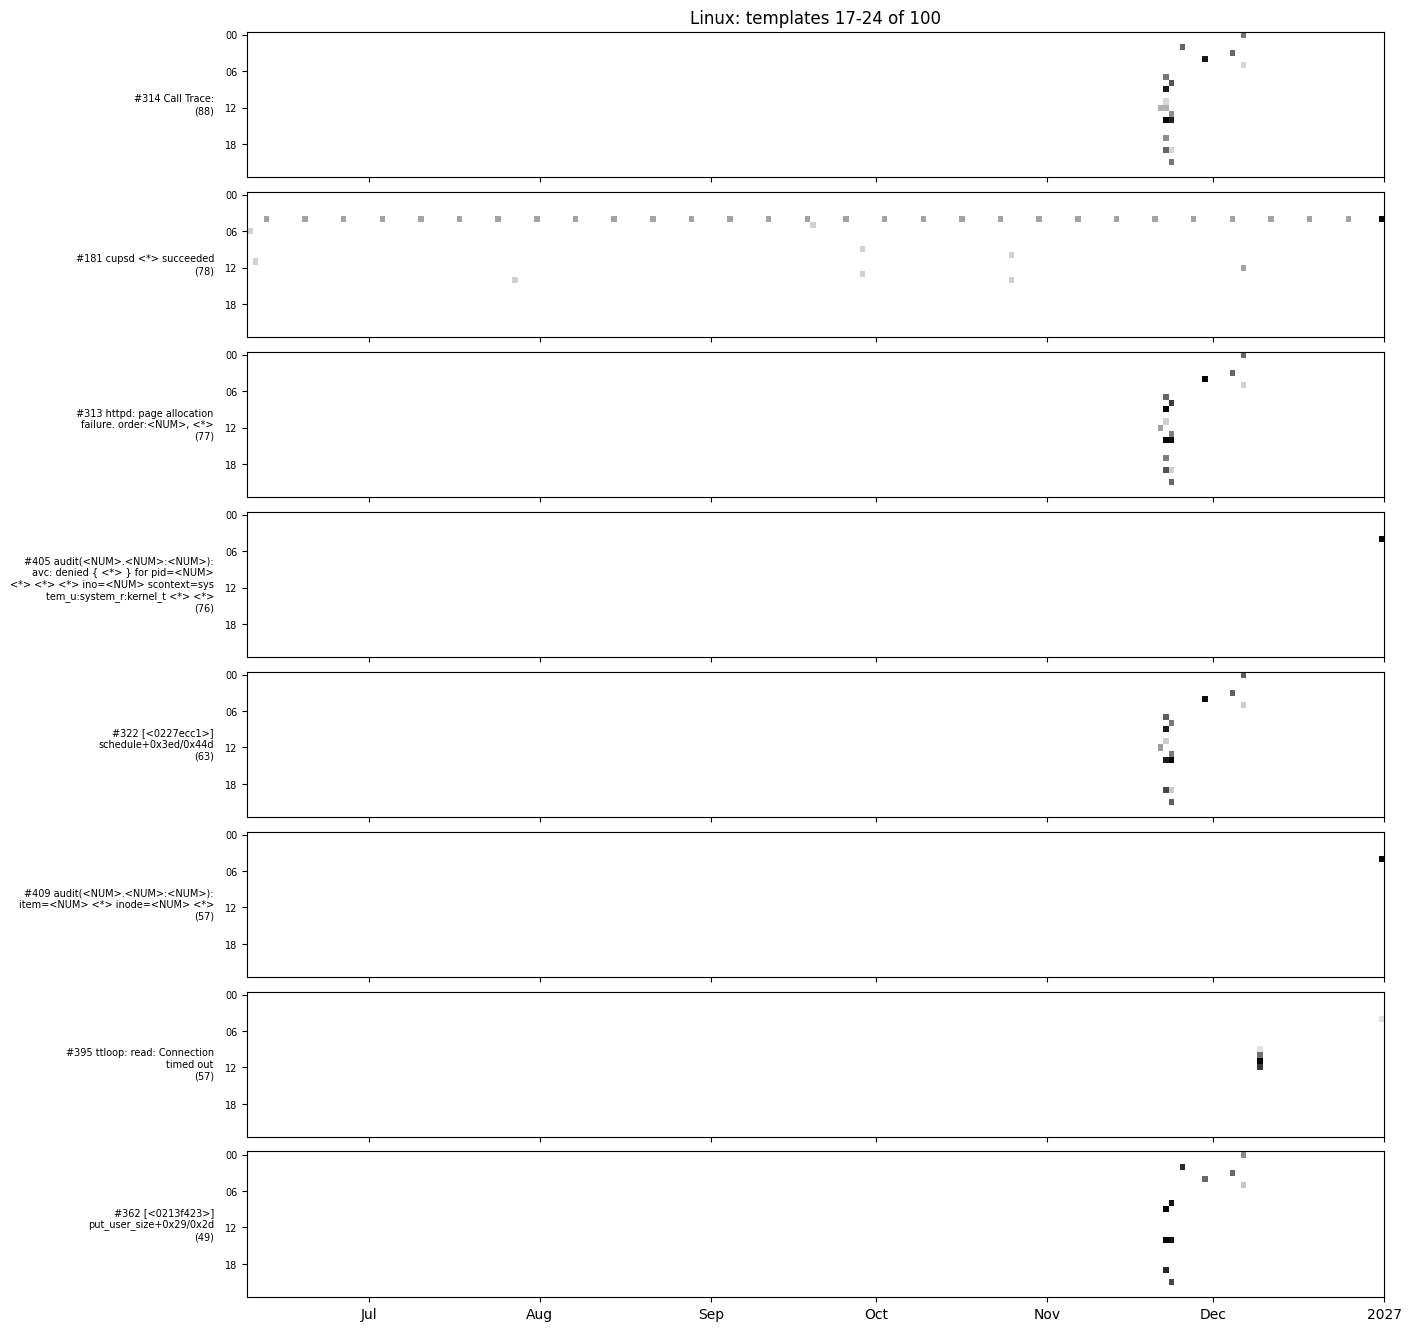

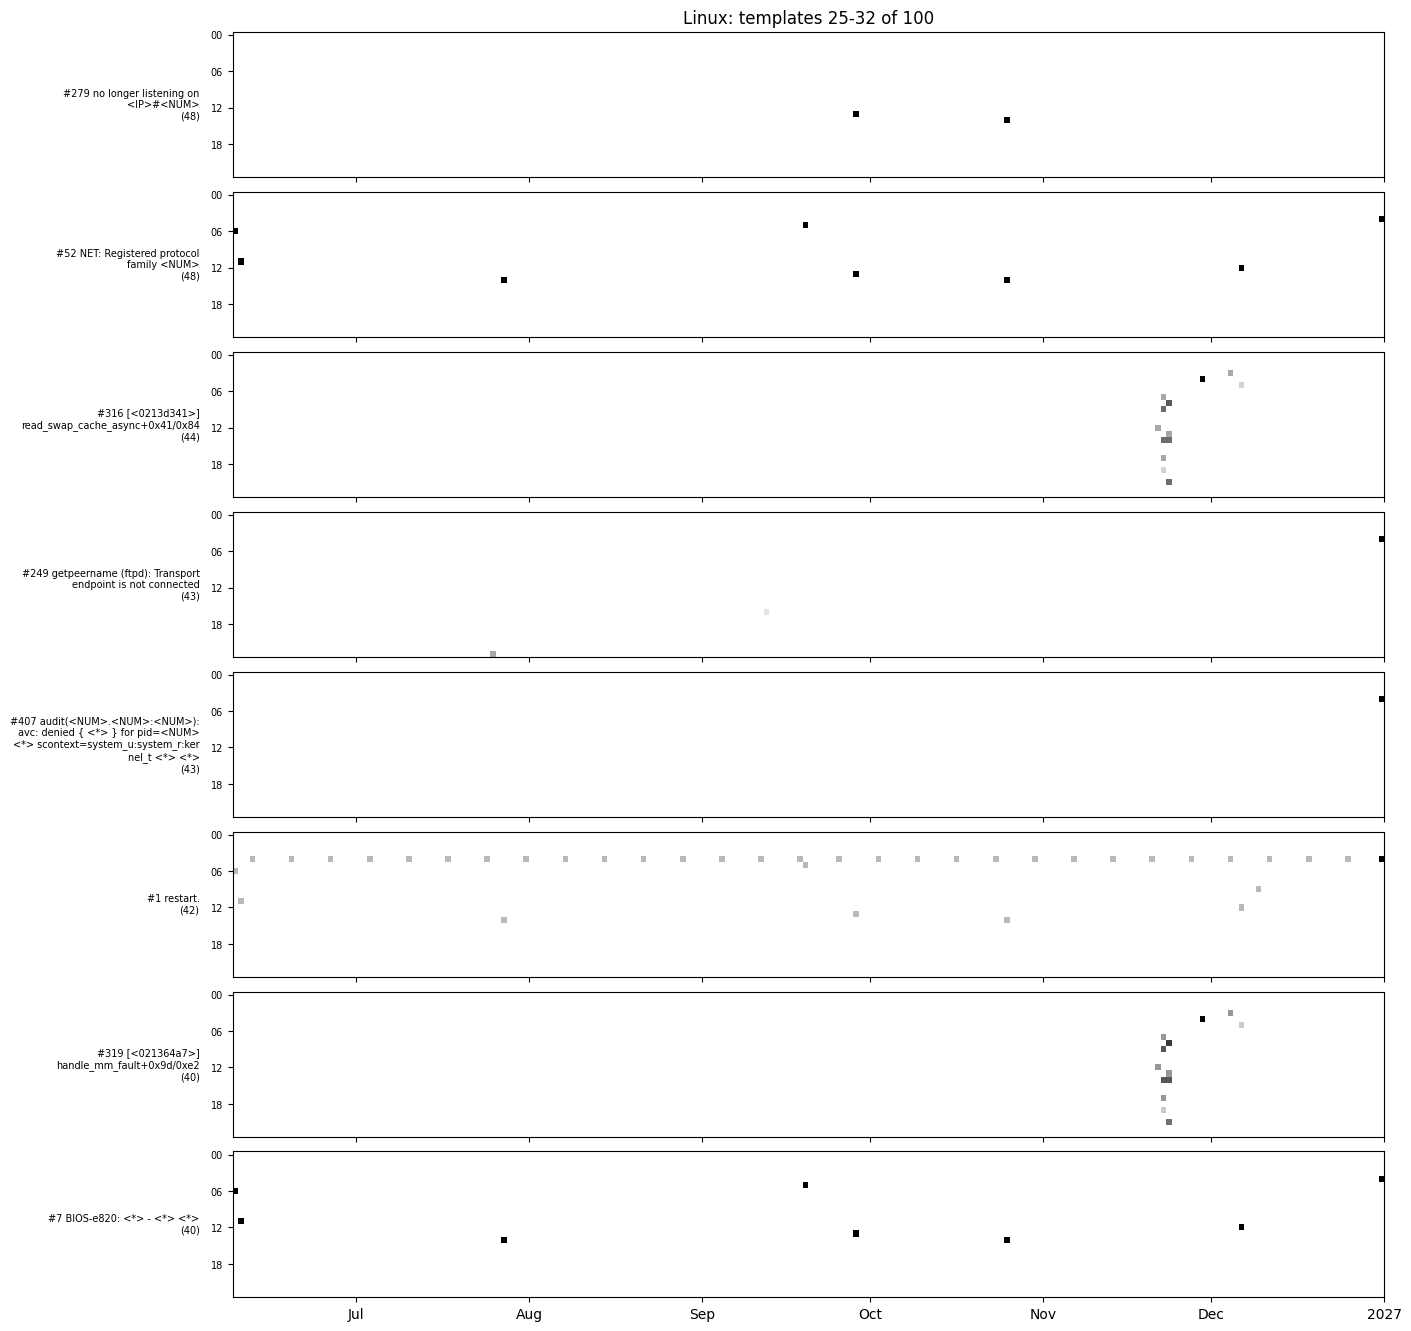

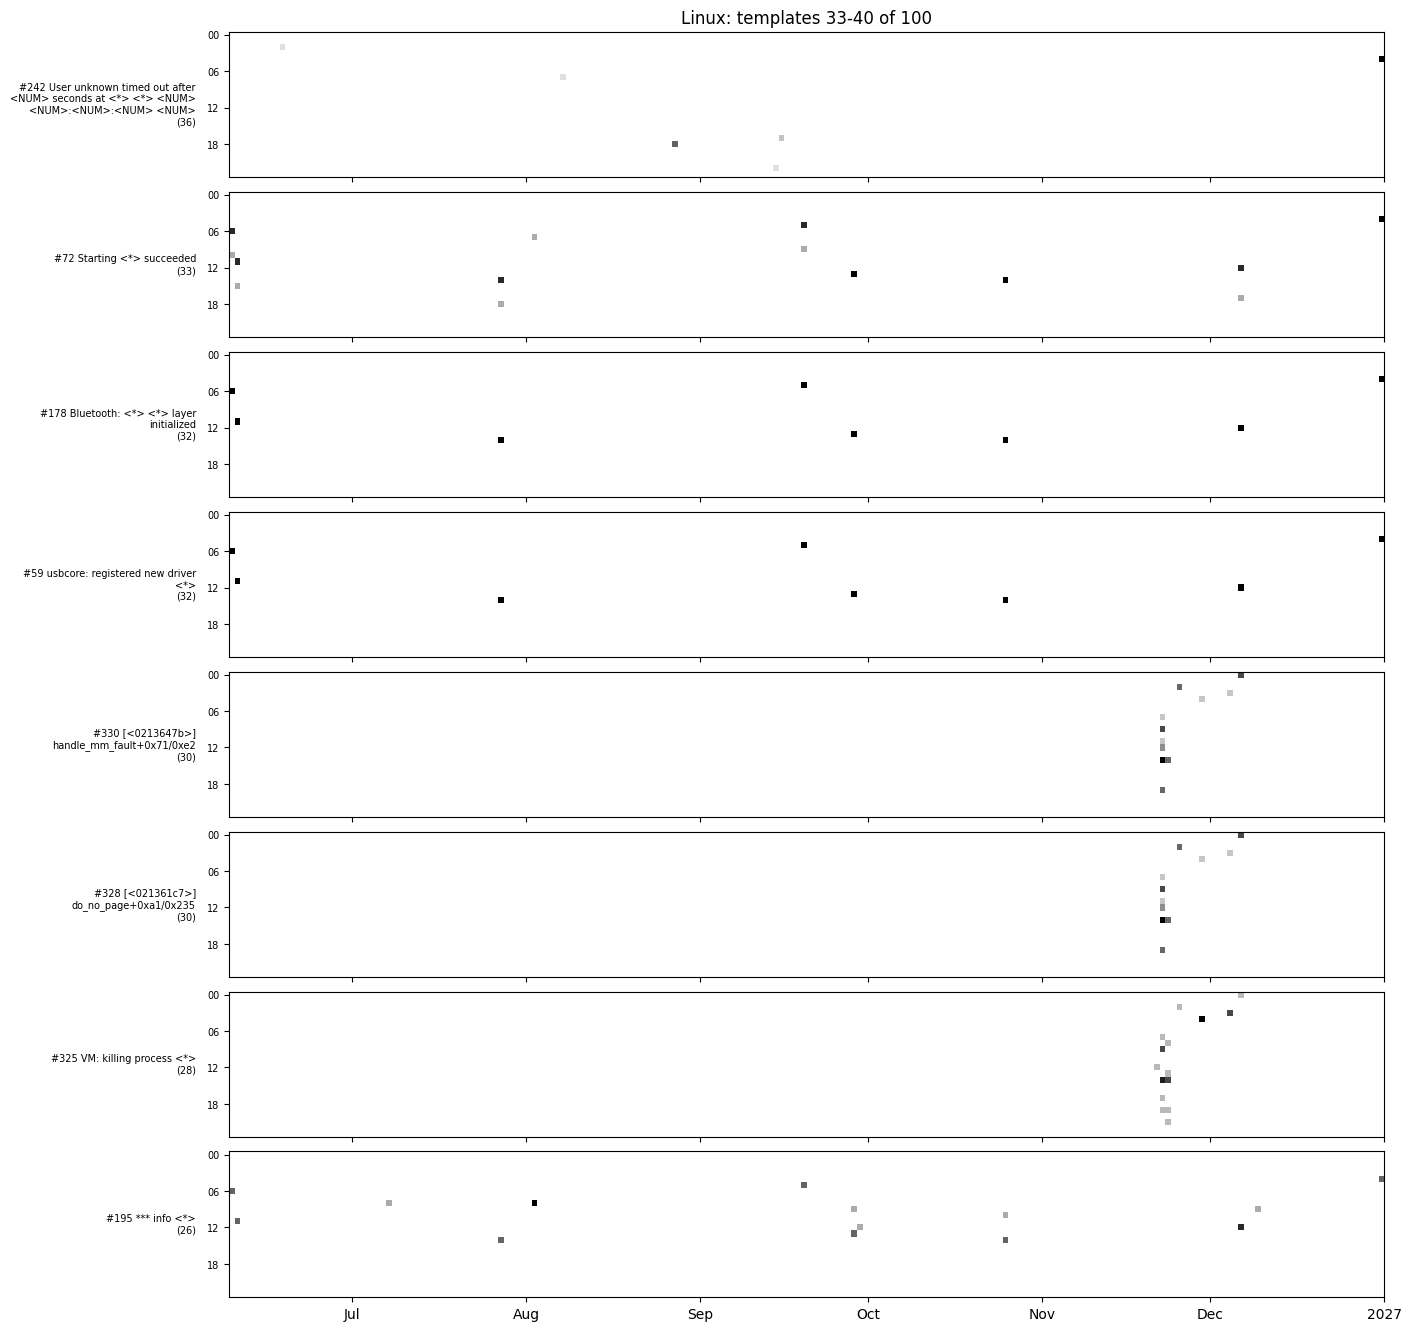

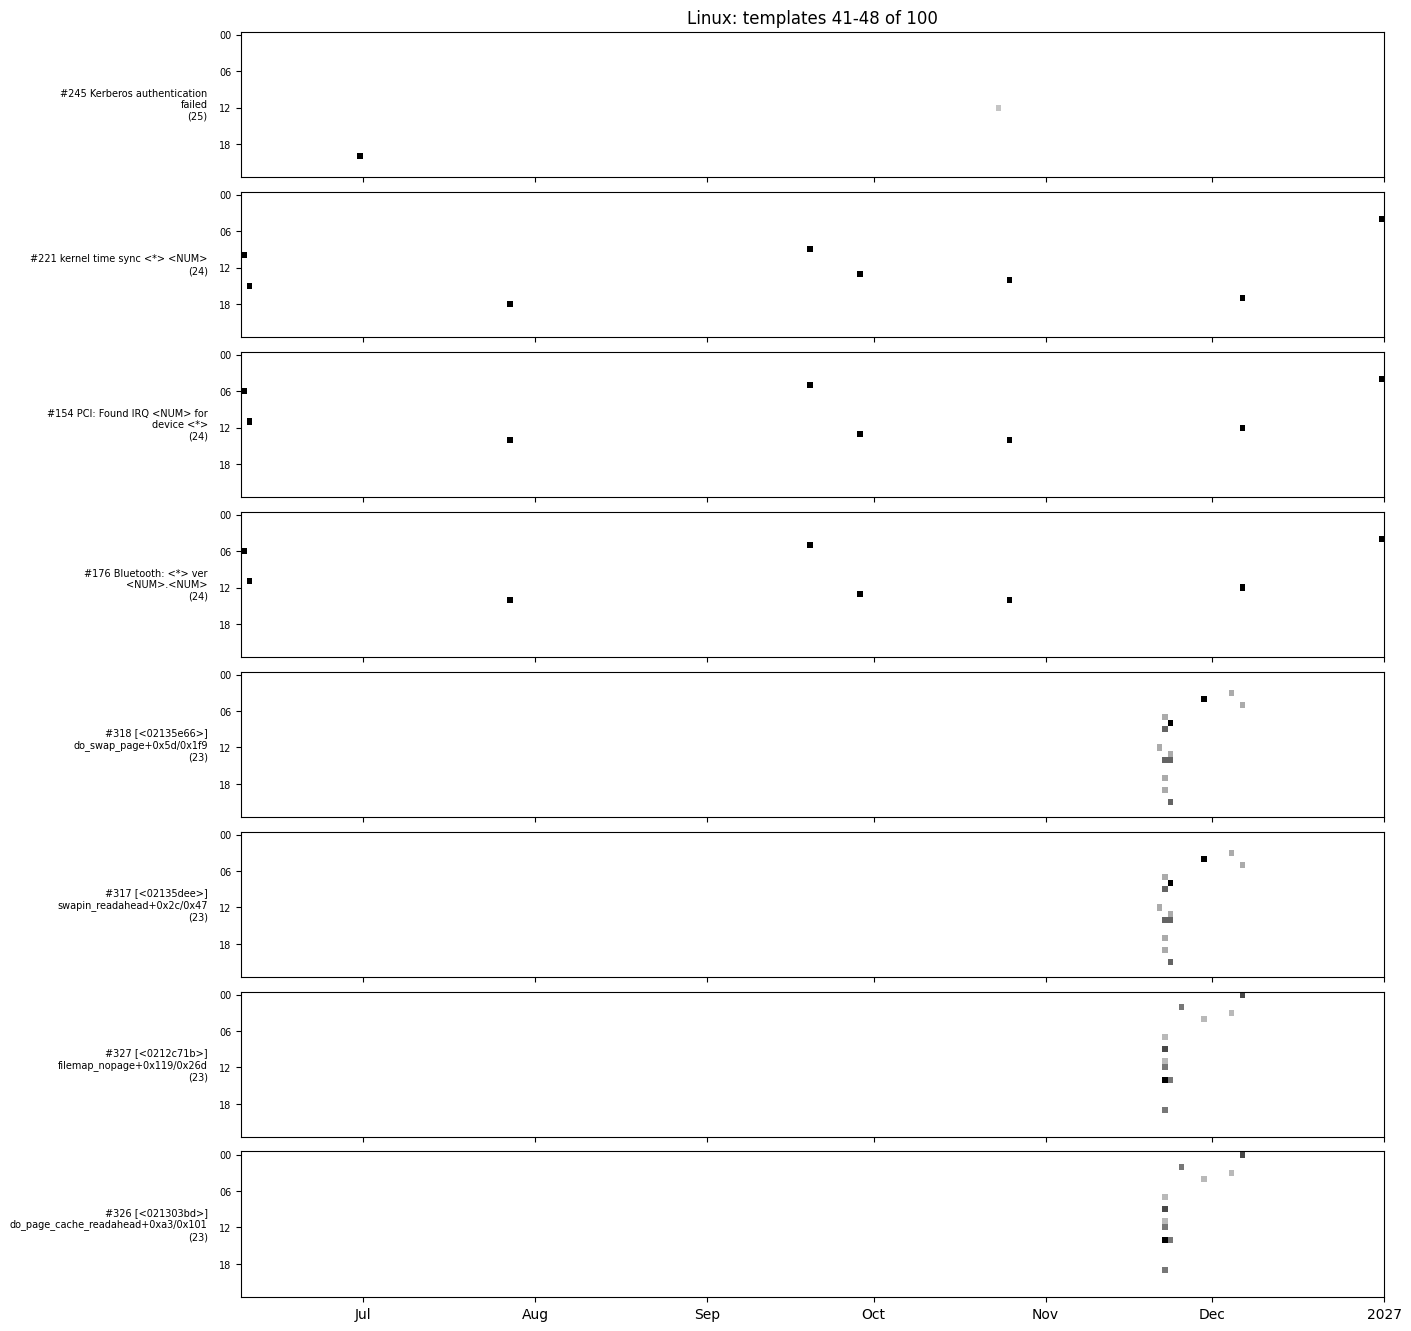

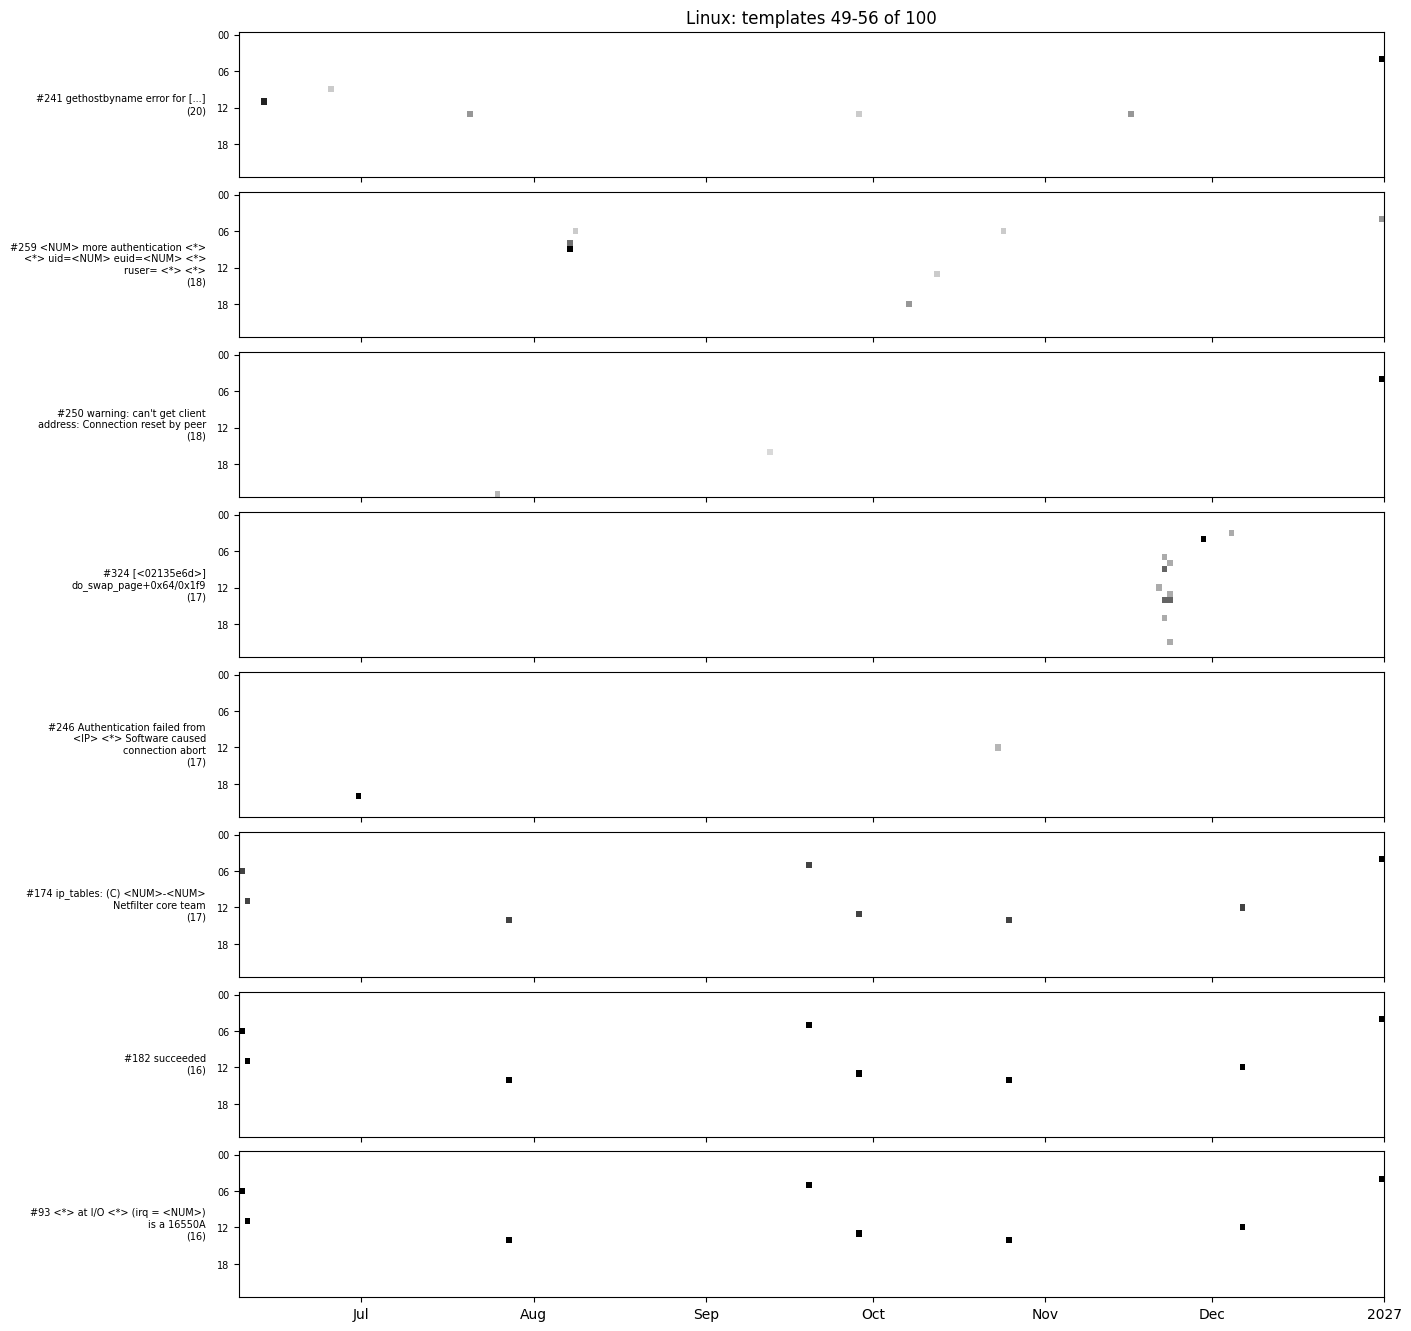

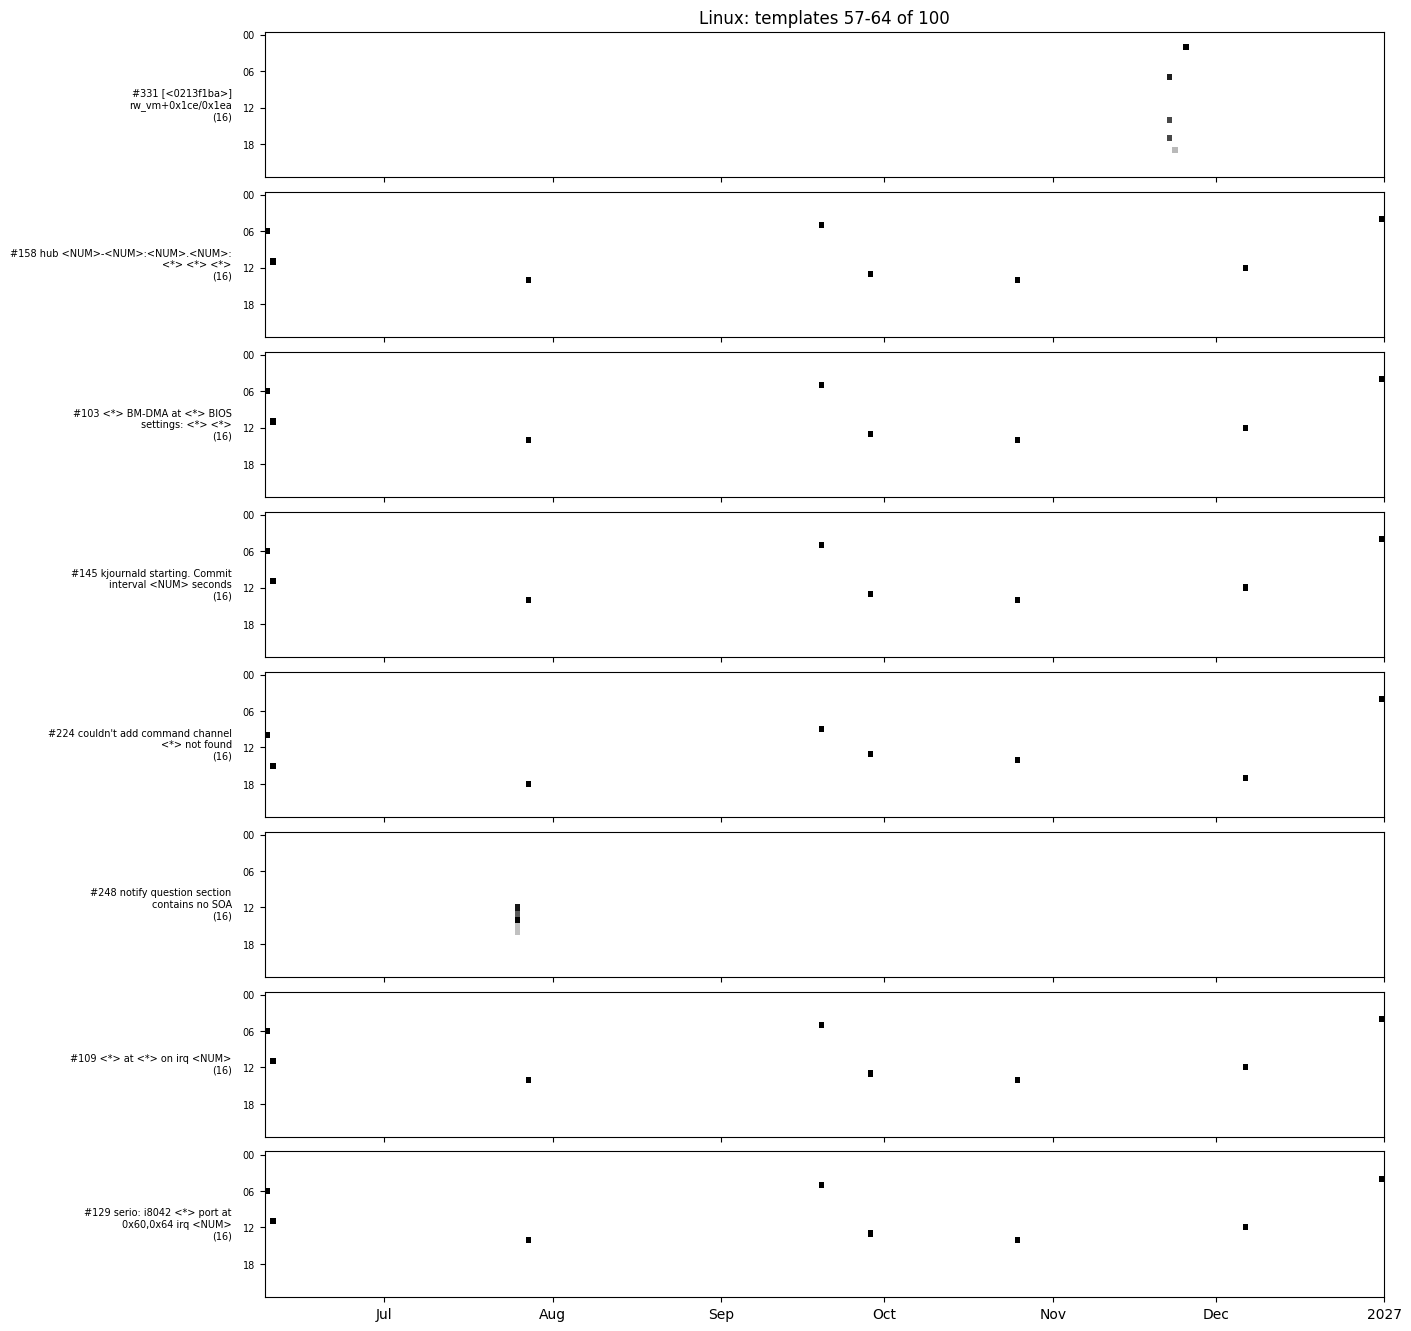

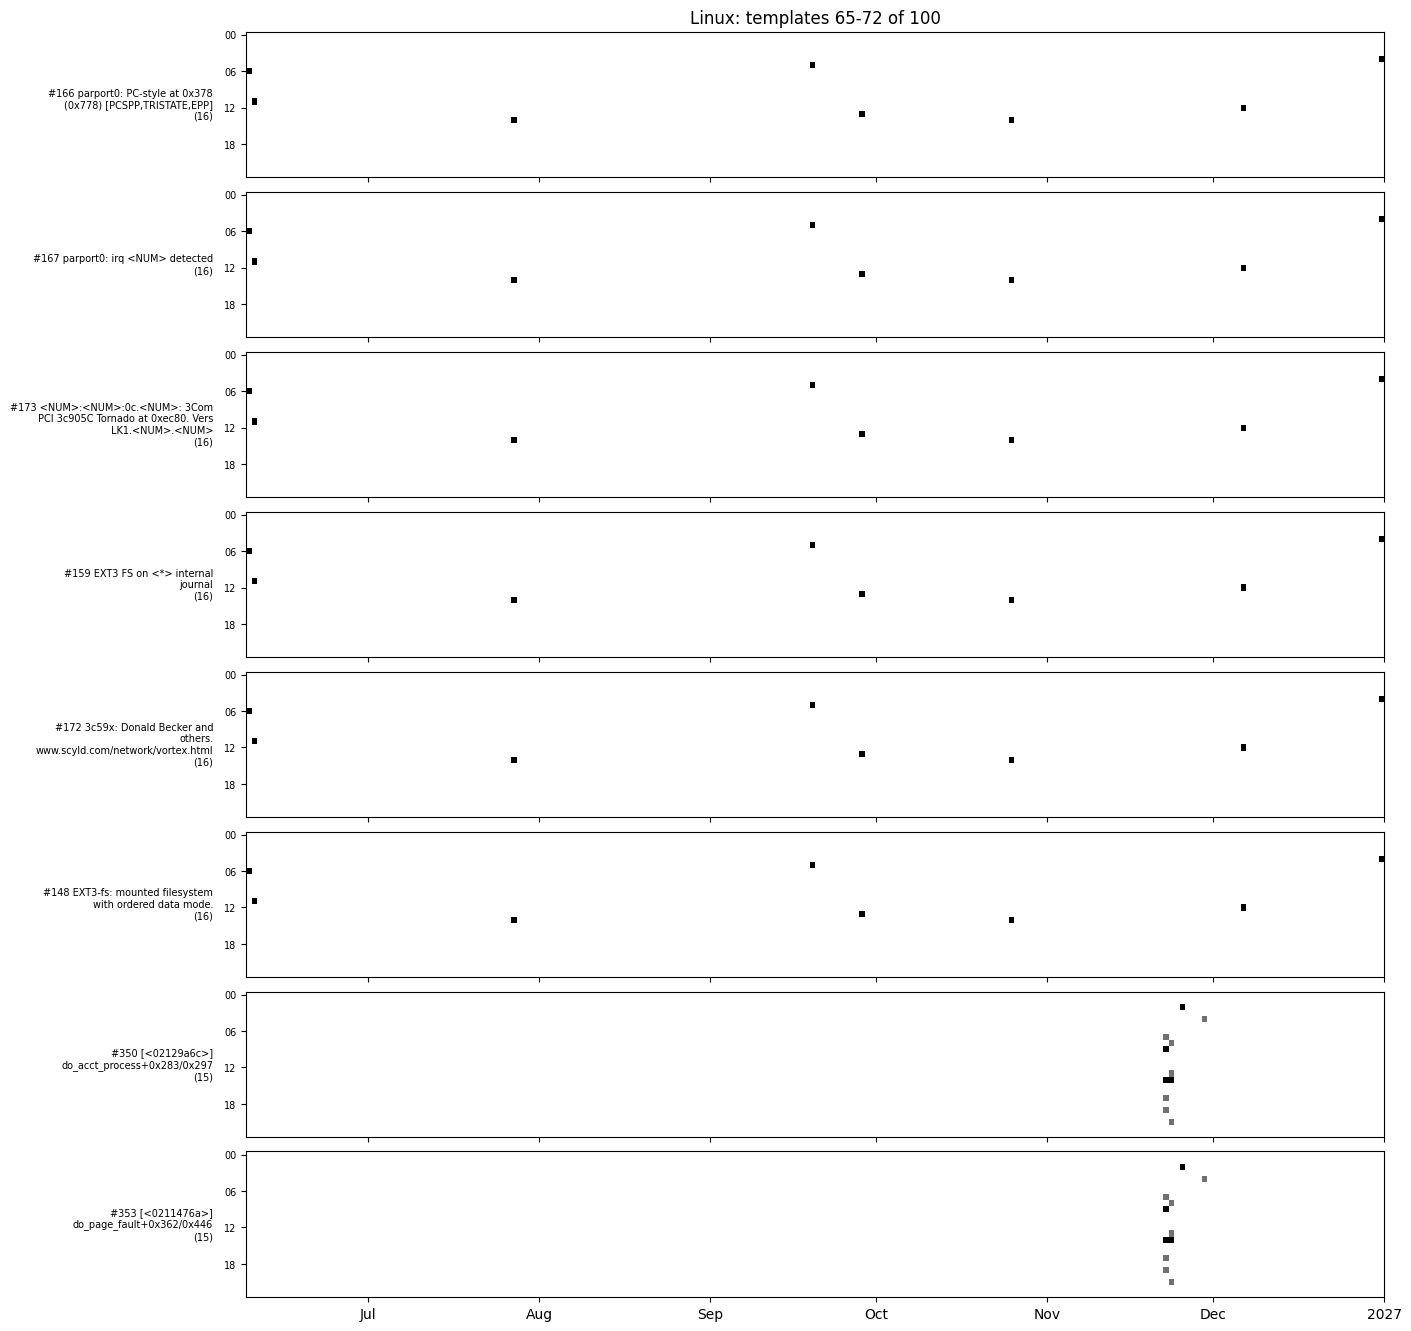

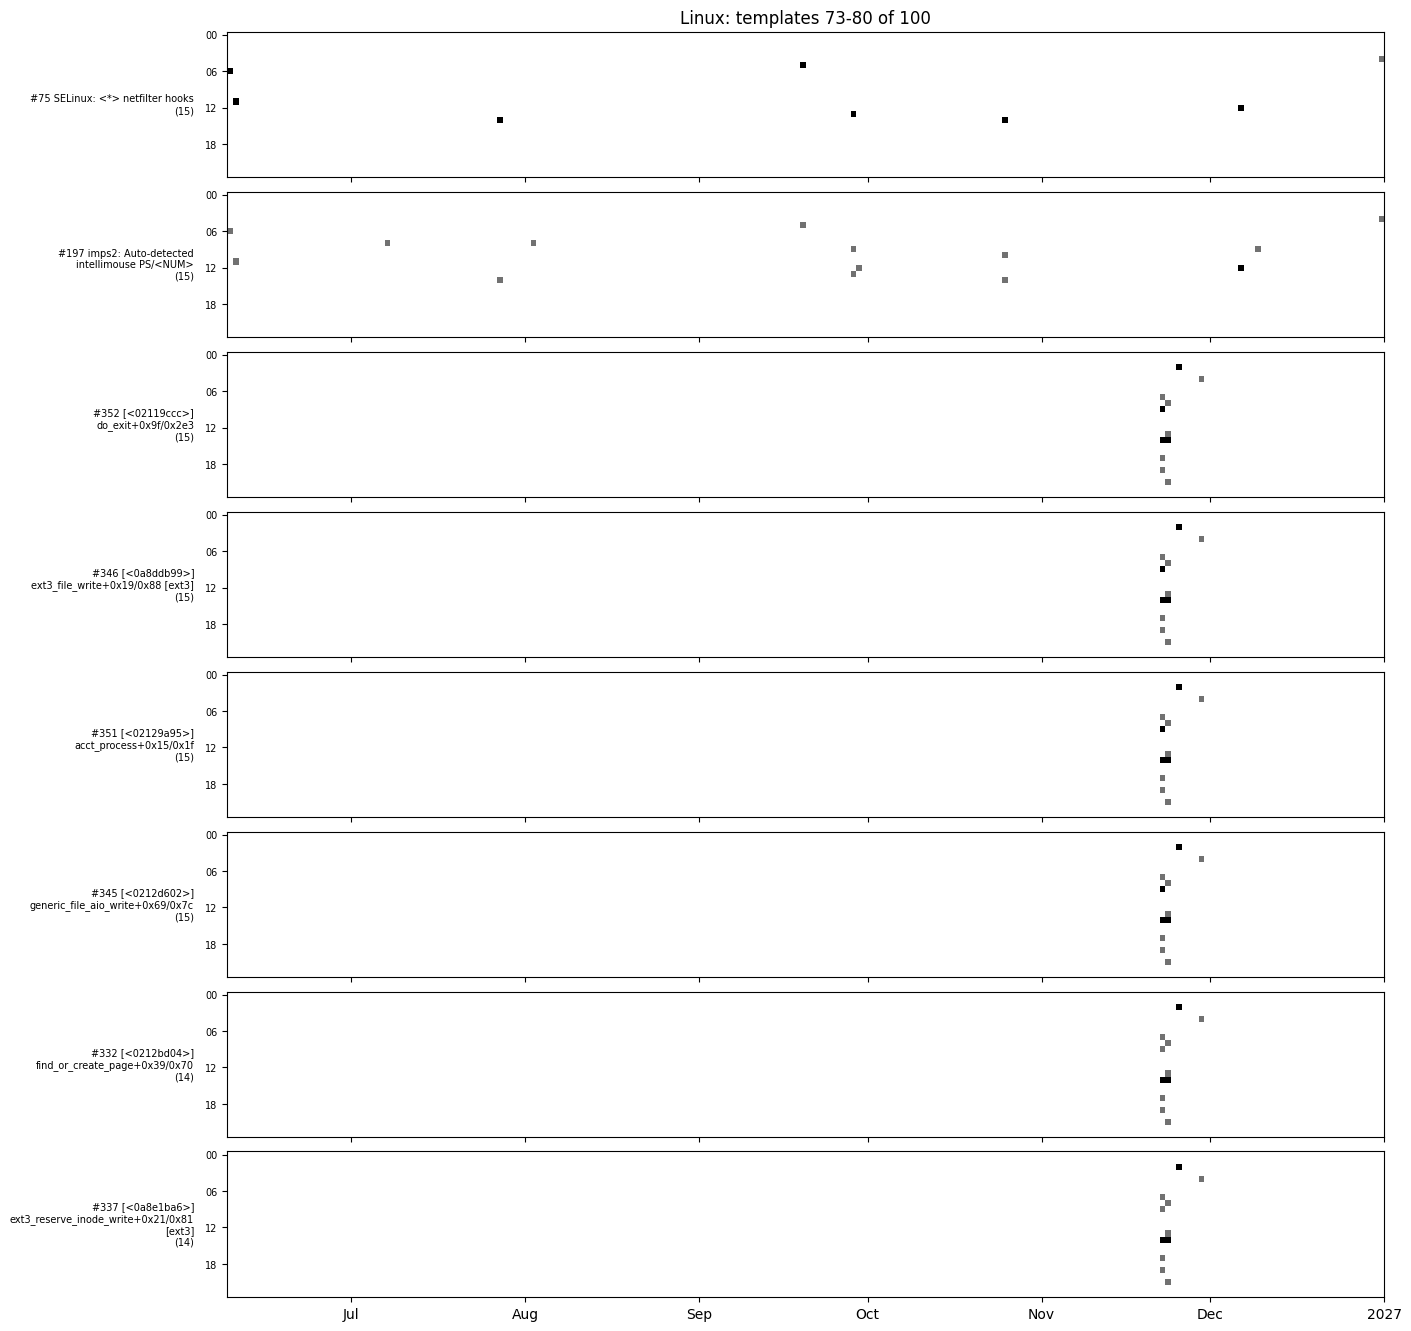

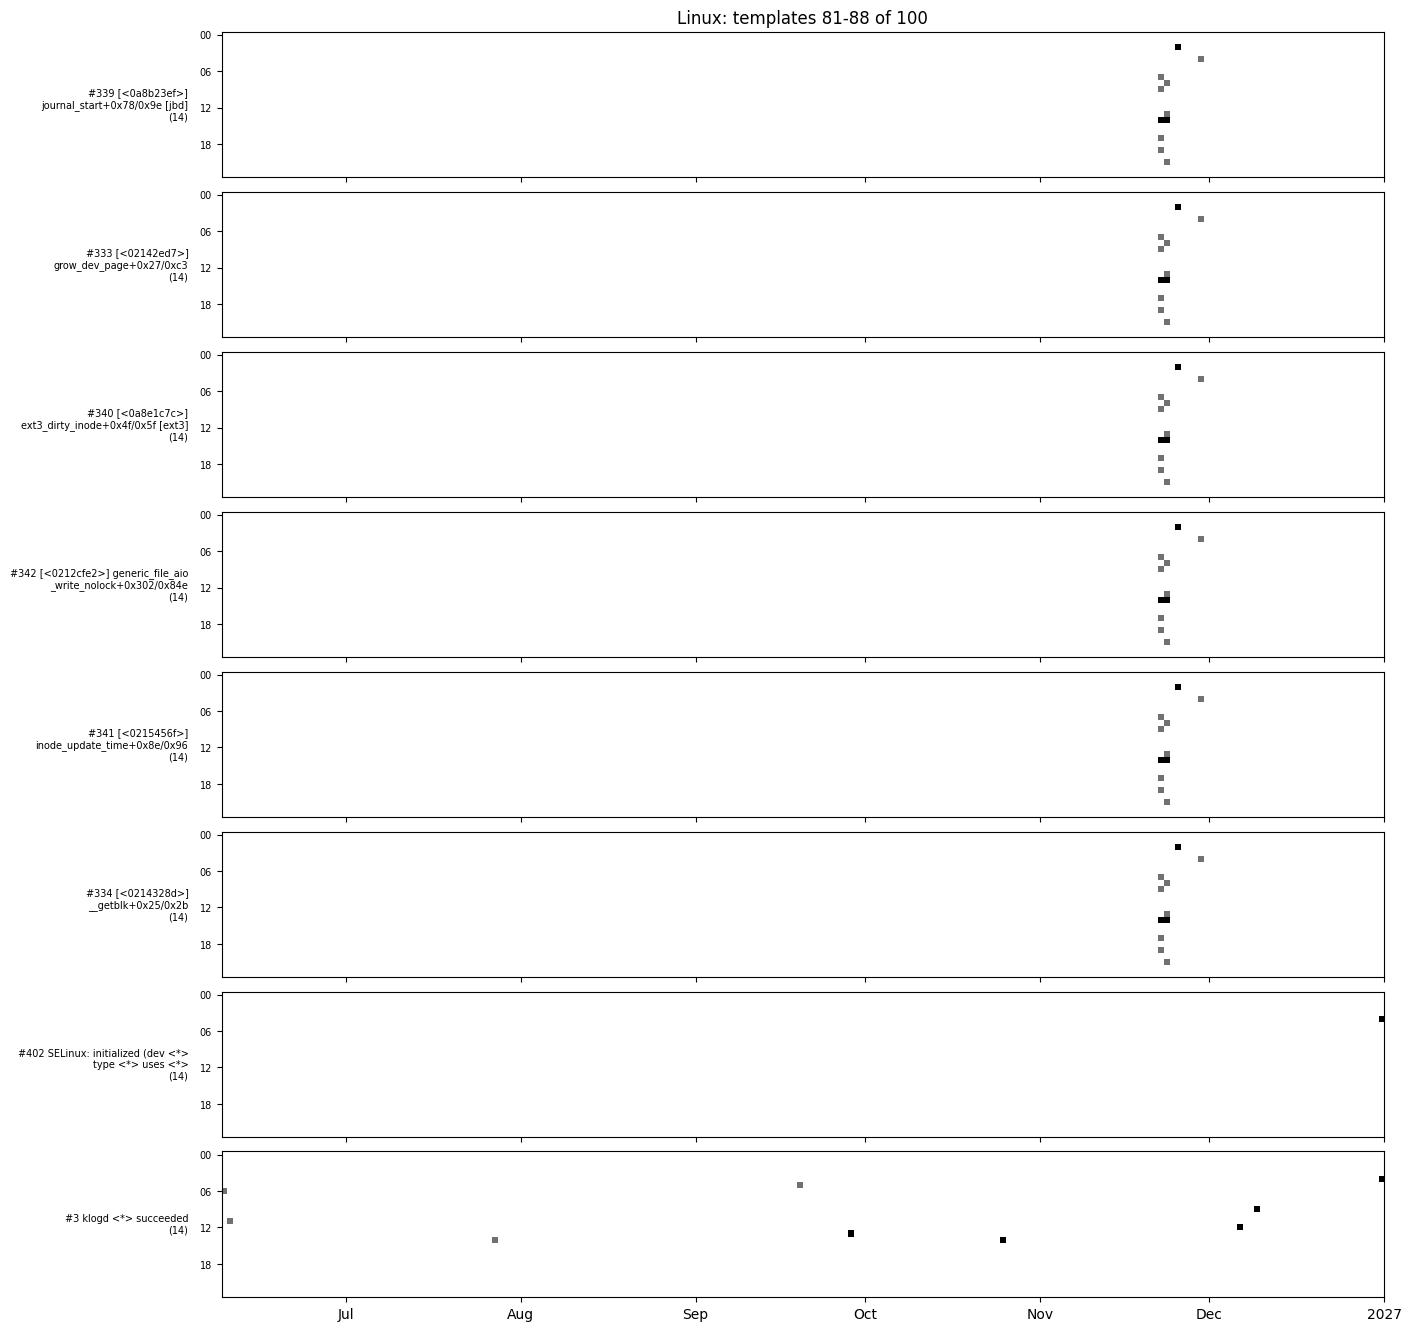

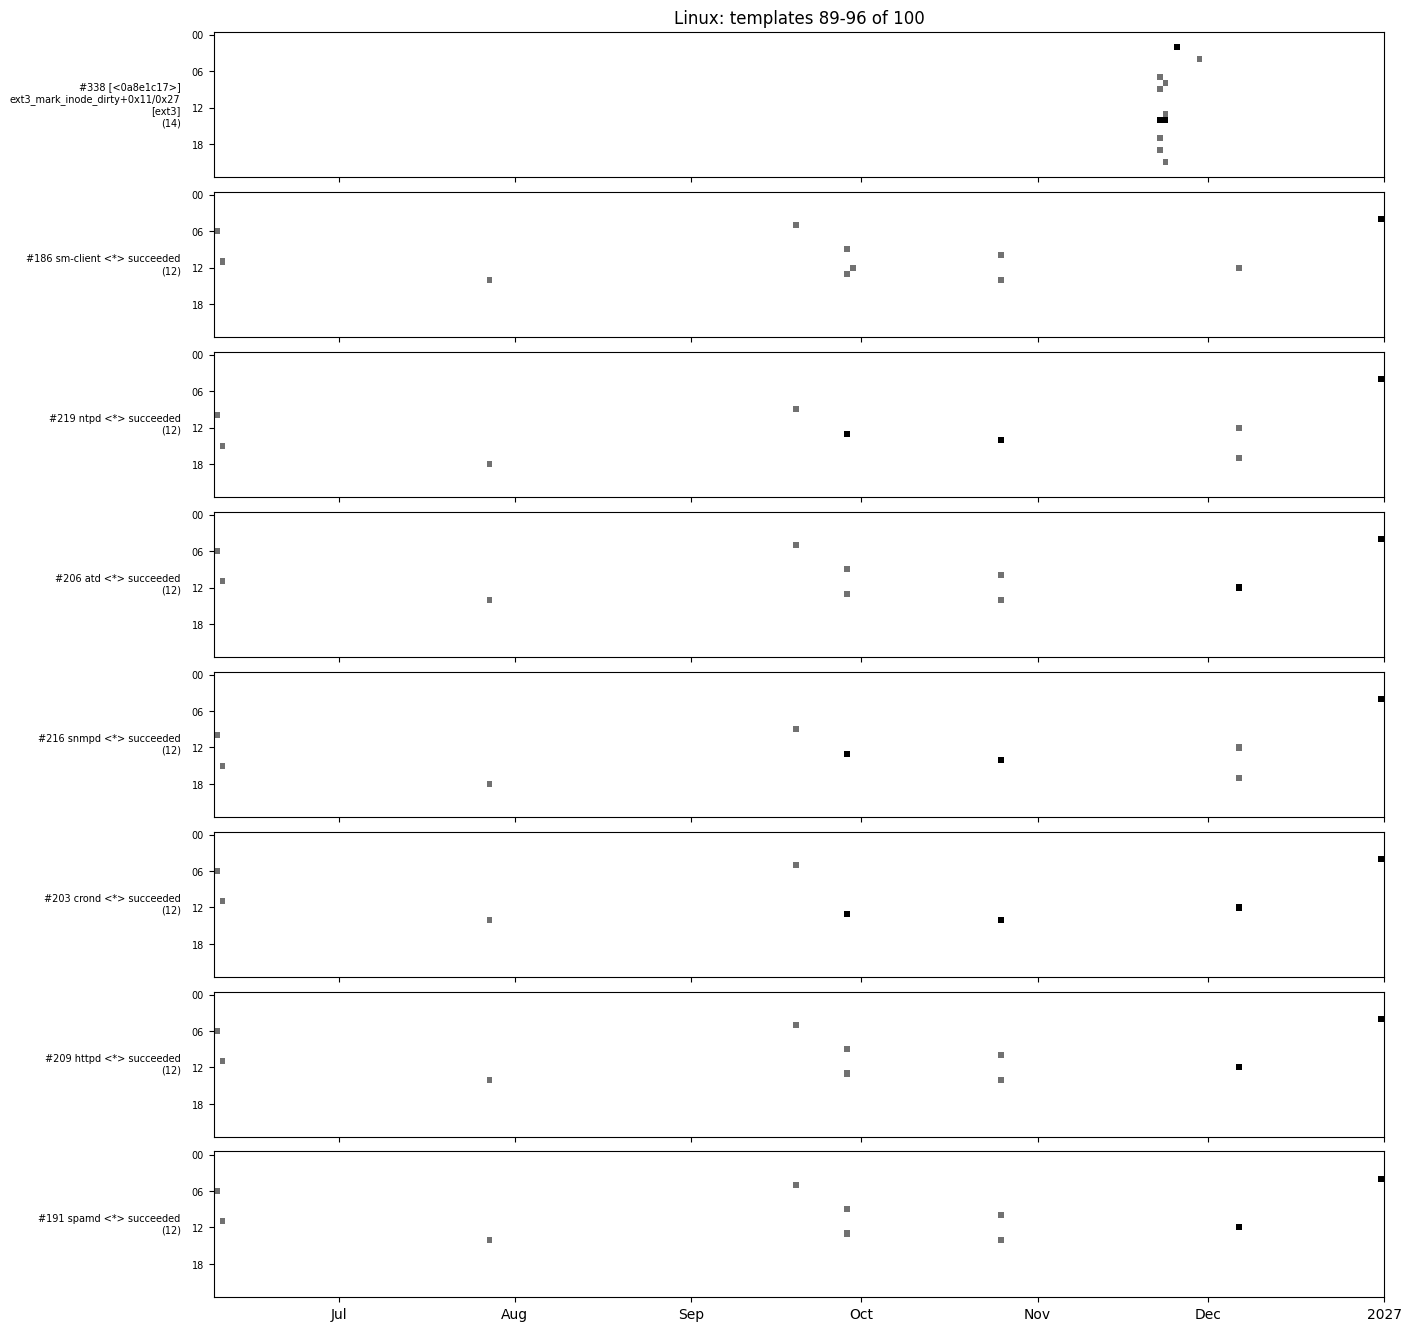

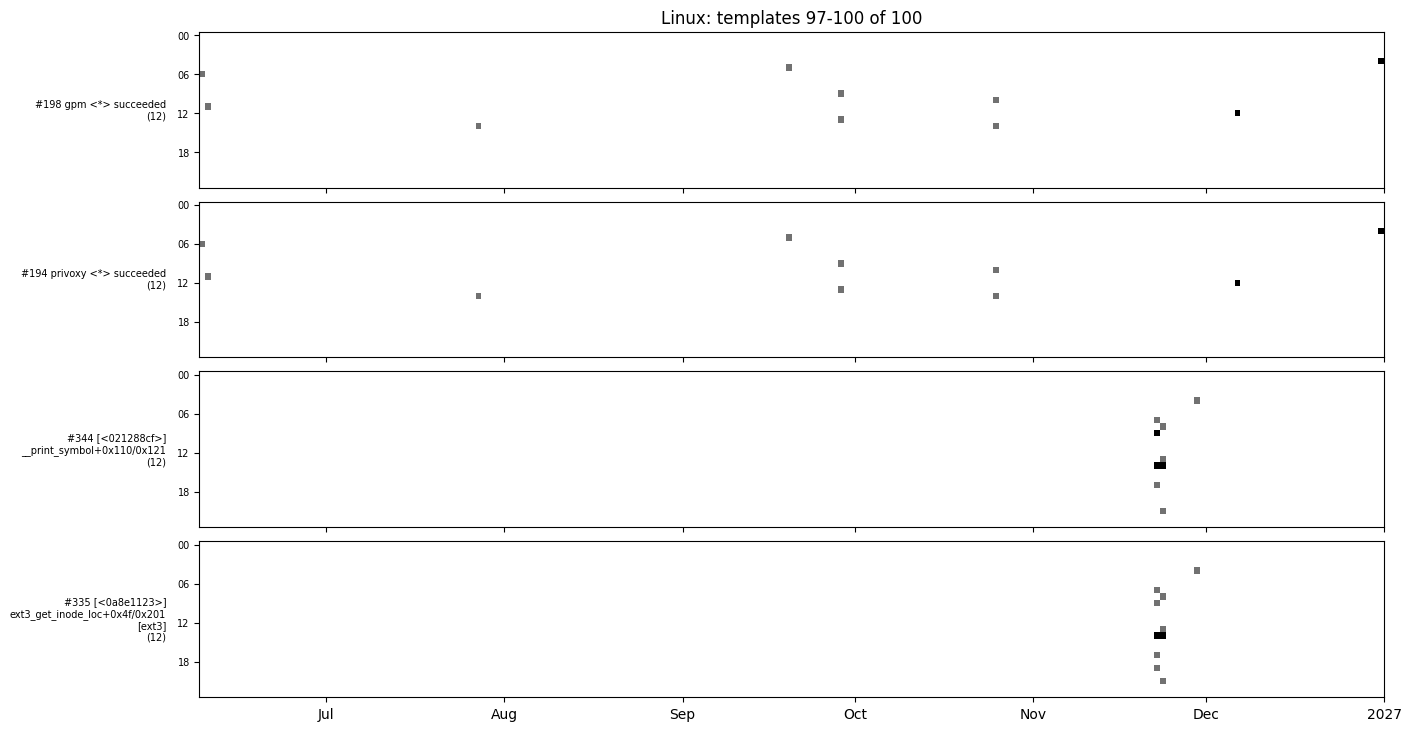

In [61]:
rows_linux = list(count_per_window(linux_reader, minutes=60))
df_linux = template_hour_frame(rows_linux, ['component', 'template_id'], miner_linux)
for fig in plot_template_pages(df_linux, top=100, title='Linux'):
    plt.show()

Наблюдаем очень мощный OOM ближе к концу. Надо будет подумать, что с этим сделать. Это частое сообщение, хотя и кластеризуется в одном месте. Для обычных моделей можно передать сигнал, что это относительно уникальное событие. Но чтобы отловить семантику, придется подключить трансформерные модели. Интересное наблюдение.

Как там дела у Proxifier?

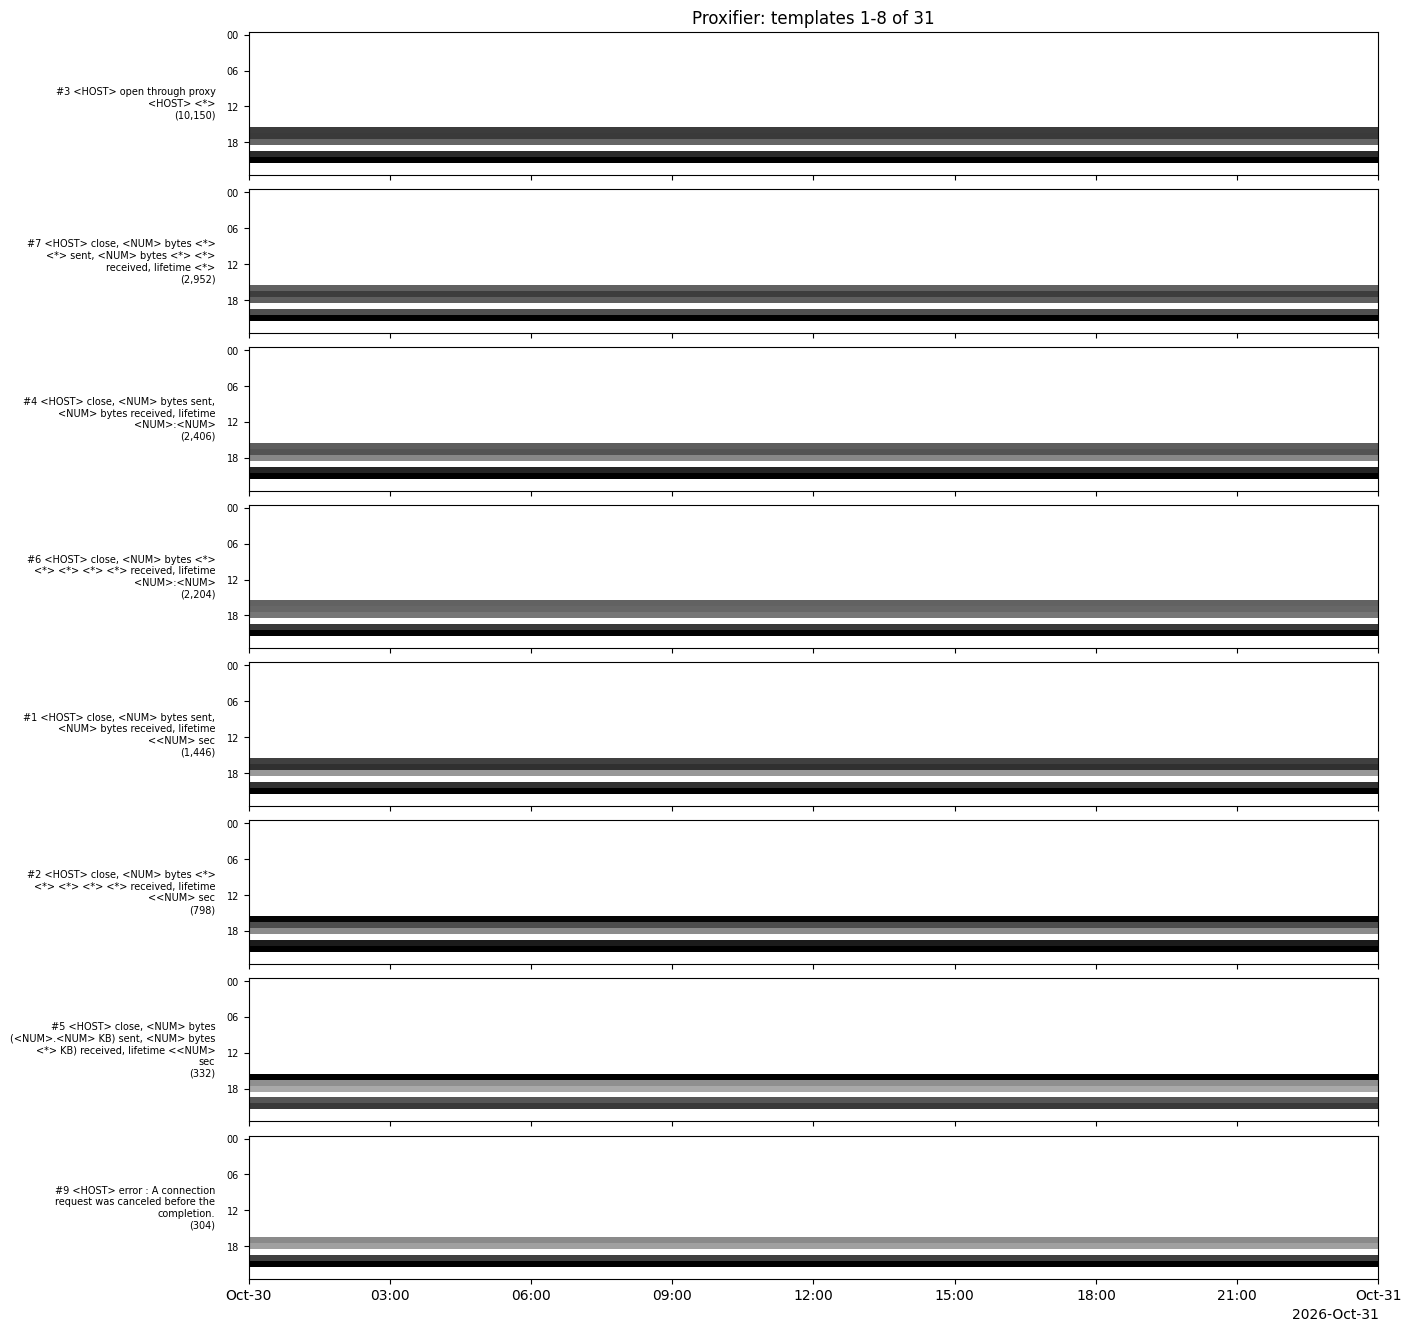

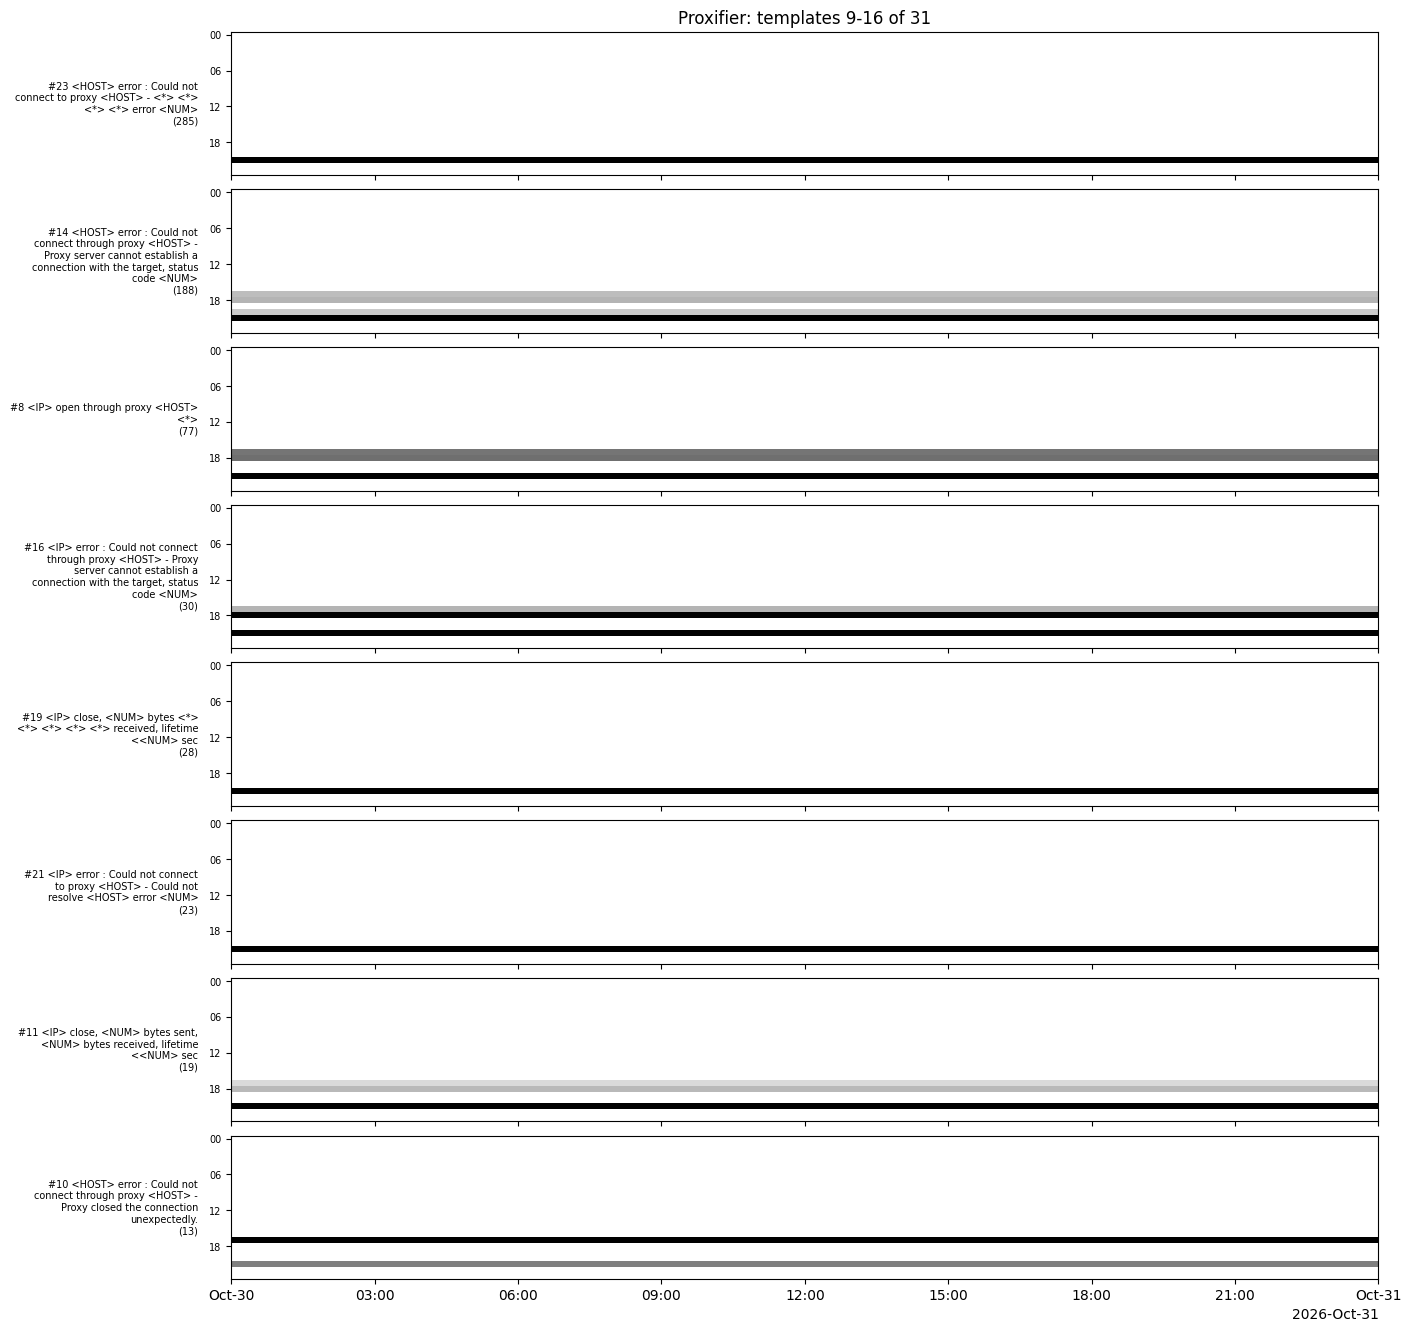

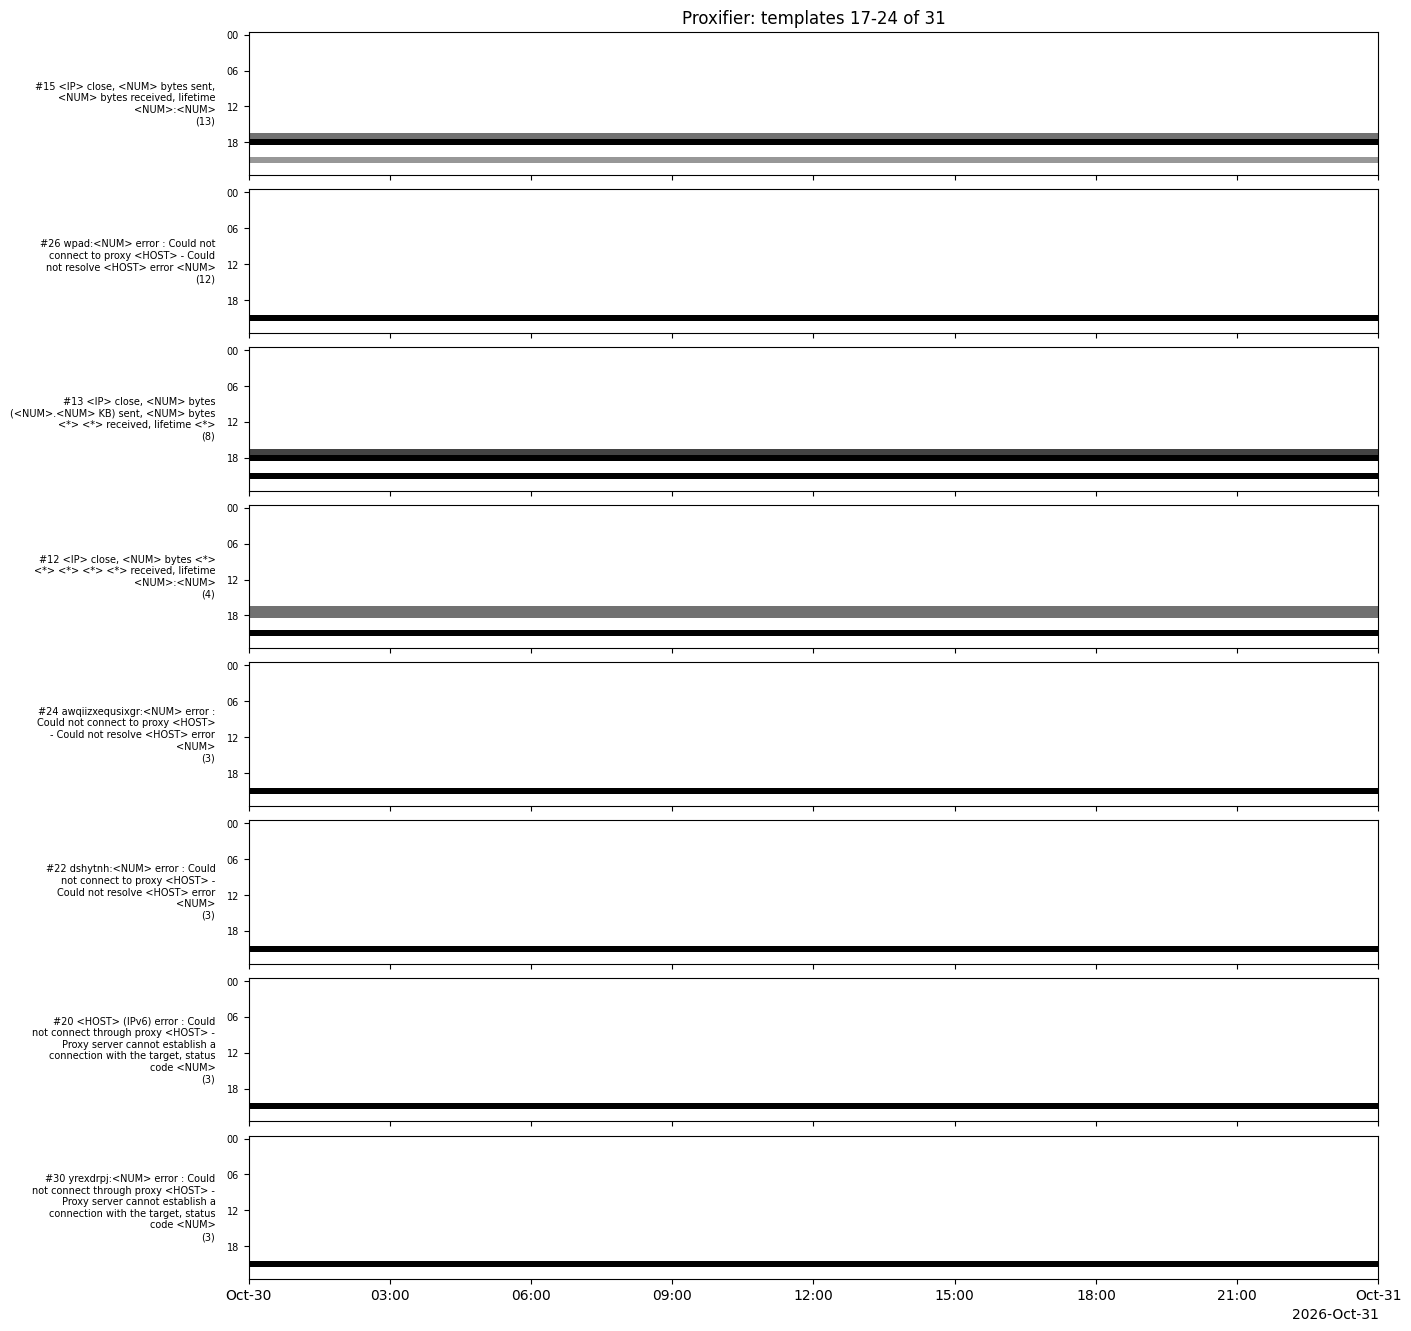

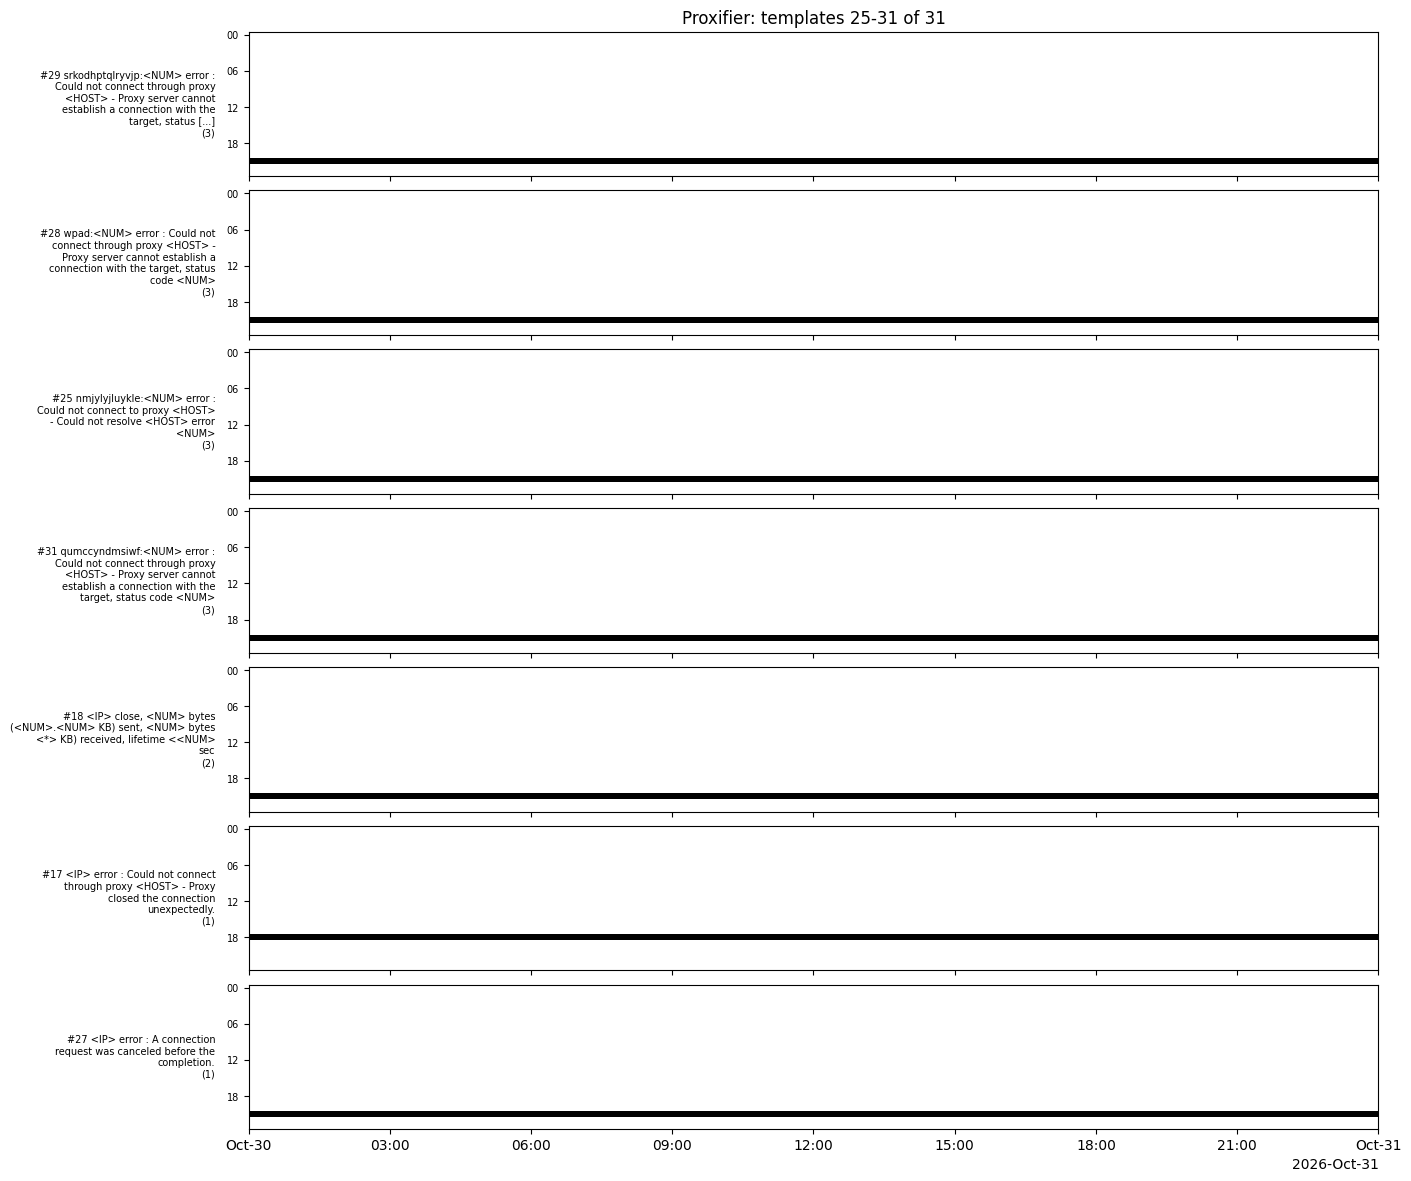

In [64]:
rows_proxifier = list(count_per_window(proxifier_reader, minutes=5))
df_proxifier = template_hour_frame(rows_proxifier, ['component', 'event', 'template_id'], miner_px)
for fig in plot_template_pages(df_proxifier, top=100, title='Proxifier'):
    plt.show()

Лог не настолько крупный, но видно, что реже происходят ошибки.